# Nabra (نبرة)
Arabic audio deepfake detection on ArA-DF 2026, Track 1. Main model: XLS-R 300M (frozen) + WPT + AASIST. Final-test EER **5.93%**.

| Part | Content |
|---|---|
| A | Data analysis and clean manifests |
| B | WPT training: learning rate and encoder |
| C | Trainable parameters: Head, LoRA, Partial |
| D | Final test |
| E | Error analysis |
| F | GATR explainability |
| G | Golden data |

**Running:** the switches in the first cell are all `False`. Heavy cells are skipped and the saved results are shown, which takes a few minutes on CPU. A switch set to `True` redoes that part (L4 GPU, hours).

EERs, CIs and the error analysis are always recomputed from the saved scores. No decision uses the final test. On Colab the files are read from `MyDrive/nabra`; locally, from the notebook's folder.

In [1]:
# Switches, paths and helpers
RUN_EDA = False
RUN_TRAINING = False
RUN_FINAL_TEST = False
RUN_XAI = False
N_BOOT = 2000

import os, sys, json, glob, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.core.magic import register_cell_magic
from IPython.display import display, Image
from sklearn.metrics import roc_curve, roc_auc_score
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = "/content/drive/MyDrive/nabra"
else:
    ROOT = os.environ.get("NABRA_ROOT", os.getcwd())
RUNS = os.path.join(ROOT, "runs")
if not os.path.isdir(RUNS):
    RUNS = os.path.join(ROOT, "artifacts", "results")
ART = os.path.join(ROOT, "artifacts", "aradf_eda")
OUT_ROOT = os.path.join(ROOT, "full_pipeline_outputs"); os.makedirs(OUT_ROOT, exist_ok=True)
MAIN = "xlsr300m__wpt__ftrecipe__lr0.0001__seed42"
DT, TEST = "track-1_development_test", "track-1_test"
SEARCH = [RUNS, os.path.join(RUNS, "summary"), os.path.join(RUNS, "report_figures"), ART,
          os.path.join(ROOT, "report_figures"), os.path.join(RUNS, "error_analysis")]

def find(name, *dirs):
    for d in list(dirs) + SEARCH:
        p = os.path.join(d, name)
        if os.path.exists(p):
            return p
    return None

def read_csv(name, *dirs, **kw):
    p = find(name, *dirs)
    if p is None:
        print(f"[not found] {name}"); return None
    return pd.read_csv(p, **kw)

def show_png(name, *dirs, width=900):
    p = find(name, *dirs)
    if p is None:
        print(f"[not found] {name}"); return
    print(name); display(Image(filename=p, width=width))

def eer_pct(y, s):
    fpr, tpr, _ = roc_curve(np.asarray(y), np.asarray(s), drop_intermediate=False)
    i = np.nanargmin(np.abs(1 - tpr - fpr))
    return float(100 * (fpr[i] + 1 - tpr[i]) / 2)

def manifest(split):
    m = pd.read_csv(os.path.join(ART, "manifests", f"{split}.csv"), low_memory=False)
    return m[m["keep"].astype(bool)].reset_index(drop=True)

def metrics_of(run):
    p = os.path.join(RUNS, run, "metrics.json")
    return json.load(open(p)) if os.path.exists(p) else None

STEP_CODE = {}
@register_cell_magic
def step(line, cell):
    flag, _, name = line.partition("--name")
    if name.strip():
        STEP_CODE[name.strip()] = cell
    if eval(flag, get_ipython().user_ns):
        get_ipython().run_cell(cell).raise_error()
    else:
        print(f"skipped ({flag.strip()} = False)")

def rerun(*names):
    for n in names:
        get_ipython().run_cell(STEP_CODE[n]).raise_error()

print("project folder:", ROOT, "\nruns:", RUNS)
print("run again:", {k: v for k, v in dict(RUN_EDA=RUN_EDA, RUN_TRAINING=RUN_TRAINING,
                                           RUN_FINAL_TEST=RUN_FINAL_TEST, RUN_XAI=RUN_XAI).items()})

project folder: C:/Users/Aisha/OneDrive/سطح المكتب/vss/Grad 
runs: C:/Users/Aisha/OneDrive/سطح المكتب/vss/Grad\artifacts\results
run again: {'RUN_EDA': False, 'RUN_TRAINING': False, 'RUN_FINAL_TEST': False, 'RUN_XAI': False}


---
# A. Data
Analysis, shortcut audit and clean manifests. Runs only with `RUN_EDA = True`.

### Setup

In [2]:
%%step RUN_EDA
# A1. Package versions
from importlib.metadata import version
import sys

print("Python:", sys.version.split()[0], "|", sys.executable)
for package in ("huggingface-hub", "soundfile", "pyarrow", "scikit-learn", "torch",
                "transformers", "numpy", "pandas", "scipy", "matplotlib"):
    print(f"{package}: {version(package)}")

skipped (RUN_EDA = False)


In [3]:
%%step RUN_EDA
# A2. Setup and dataset access
import os, io, re, json, glob, time, shutil, hashlib, sys
from collections import defaultdict
import numpy as np, pandas as pd, soundfile as sf
import matplotlib.pyplot as plt
from huggingface_hub import HfApi, hf_hub_download, login
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

REPO_ID    = "ArabicSpeech/ArA-DF-2026"
REVISION   = "2b1f042dc166b1d372841cb0d7110661ea5b2a93"
LOCAL_ROOT = None
AUDIO_ROOT = "/content/aradf_audio" if IN_COLAB else r"C:\Users\Aisha\nabra_data\aradf_audio"
EXTRACT_SPLITS = ["train", "dev", "track-1_development_test", "track-2_development_test"]
MAX_SHARDS_PER_SPLIT = None
SEED = 42

os.makedirs(AUDIO_ROOT, exist_ok=True)
np.random.seed(SEED)

HF_TOKEN = None
try:
    from google.colab import userdata; HF_TOKEN = userdata.get("HF_TOKEN")
except Exception:
    HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN: login(HF_TOKEN)

def list_files():
    if LOCAL_ROOT:
        return sorted(os.path.relpath(p, LOCAL_ROOT).replace(os.sep, "/")
                      for p in glob.glob(f"{LOCAL_ROOT}/**/*", recursive=True) if os.path.isfile(p))
    return sorted(HfApi().list_repo_files(REPO_ID, repo_type="dataset", revision=REVISION, token=HF_TOKEN))

def fetch(path):
    return os.path.join(LOCAL_ROOT, path) if LOCAL_ROOT else hf_hub_download(REPO_ID, path, repo_type="dataset", revision=REVISION, token=HF_TOKEN)

FILES = list_files()
print(len(FILES), "files in repo")

skipped (RUN_EDA = False)


**Result:** setup OK, Hub connected.

### Load metadata

In [4]:
%%step RUN_EDA
# A3. Load metadata
SPLITS = ["train", "dev", "track-1_development_test", "track-2_development_test", "track-1_test", "track-2_test"]
def meta_path(s):
    return f"metadata/{s}.parquet" if s in ("train", "dev") else f"metadata_labeled/{s}.parquet"

ALL = pd.concat([pd.read_parquet(fetch(meta_path(s))).assign(cfg=s) for s in SPLITS], ignore_index=True)
ALL["label_name"] = ALL["label"].map({1: "bonafide", 0: "spoof"})

def parse_name(i):
    p = str(i).split("_")
    return (p[0], p[1]) if len(p) >= 4 and p[2] in ("train", "dev") else ("unknown", "unknown")
ALL[["dialect", "gender"]] = pd.DataFrame(ALL["id"].map(parse_name).tolist(), index=ALL.index)
TD = ALL[ALL.cfg.isin(["train", "dev"])]
print(ALL.shape); ALL.head(3)

skipped (RUN_EDA = False)


**Result:** 345,672 labeled clips in 6 splits (matches the paper).

### Metadata EDA

In [5]:
%%step RUN_EDA
# A4. Labels per split
print(pd.crosstab(ALL.cfg, ALL.label_name, margins=True), "\n")
print(pd.crosstab([TD.cfg, TD.dialect], [TD.label_name], margins=True), "\n")
print(pd.crosstab([TD.cfg, TD.dialect, TD.gender], TD.label_name), "\n")
print(TD.groupby(["cfg", "dialect", "label_name"])["duration_sec"].describe(percentiles=[.05, .5, .95]).round(2))

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
pd.crosstab(ALL.cfg, ALL.label_name).plot.bar(ax=ax[0], title="label per split")
pd.crosstab([TD.dialect], [TD.gender]).plot.bar(ax=ax[1], title="dialect x gender (train+dev)")
TD.boxplot("duration_sec", by=["dialect", "label_name"], ax=ax[2], rot=45); ax[2].set_title("duration by dialect/label")
plt.suptitle(""); plt.tight_layout(); plt.show()

skipped (RUN_EDA = False)


**Result:** bona fide : spoof ≈ 1 : 2 in every split; dev is 71% Gulf; train is 81% male.

In [6]:
%%step RUN_EDA
# A5. Very long and very short clips
long_ = ALL[ALL.duration_sec > 15.5]; short_ = ALL[ALL.duration_sec < 1.0]
print("clips > 15.5 s:"); print(pd.crosstab(long_.cfg, long_.label_name))
print("\nclips < 1 s:");   print(pd.crosstab(short_.cfg, short_.label_name))
print("\nlongest clips:"); print(ALL.nlargest(8, "duration_sec")[["cfg", "id", "label_name", "duration_sec"]])

skipped (RUN_EDA = False)


**Result:** almost all clips over 15.5 s or under 1 s are spoof.

### Data pipeline functions

In [7]:
%%step RUN_EDA
# A6. Audio pipeline functions
import os, io, json, tarfile
import numpy as np, pandas as pd, soundfile as sf

SR = 16000
REPO_ID = "ArabicSpeech/ArA-DF-2026"

def iter_tar(tar_path):
    with tarfile.open(tar_path) as tf:
        for m in tf:
            if m.isfile() and m.name.endswith(".flac"):
                yield os.path.basename(m.name)[:-5], tf.extractfile(m).read()

def prepare_audio(splits, audio_root, keep_ids=None, token=None, max_shards=None, on_clip=None):
    from huggingface_hub import HfApi, hf_hub_download
    files = HfApi().list_repo_files(REPO_ID, repo_type="dataset", token=token)
    for split in splits:
        tars = sorted(f for f in files if f.startswith(f"data/{split}/") and f.endswith(".tar"))[:max_shards]
        os.makedirs(f"{audio_root}/{split}", exist_ok=True)
        for t in tars:
            local = hf_hub_download(REPO_ID, t, repo_type="dataset", token=token)
            extract_tar(local, split, audio_root, keep_ids, on_clip)

def extract_tar(local_tar, split, audio_root, keep_ids=None, on_clip=None):
    n = 0
    for cid, flac in iter_tar(local_tar):
        if on_clip: on_clip(split, cid, flac)
        if keep_ids is not None and cid not in keep_ids: continue
        p = f"{audio_root}/{split}/{cid}.flac"
        if not os.path.exists(p):
            with open(p, "wb") as f: f.write(flac)
        n += 1
    return n

def load_wave(path):
    x, sr = sf.read(path, dtype="float32", always_2d=False)
    if x.ndim > 1: x = x.mean(1)
    assert sr == SR, f"{path}: sr={sr}"
    return x

def trim_silence(x, top_db=40.0, frame=400, hop=160):
    if len(x) < frame: return x
    nf = 1 + (len(x) - frame) // hop
    idx = np.arange(frame)[None, :] + hop * np.arange(nf)[:, None]
    e = 10 * np.log10((x[idx] ** 2).mean(1) + 1e-10)
    v = np.flatnonzero(e > e.max() - top_db)
    return x[v[0] * hop: v[-1] * hop + frame] if len(v) else x

def rms_normalize(x, target_dbfs=-23.0):
    rms = np.sqrt(np.mean(x ** 2) + 1e-12)
    return np.clip(x * (10 ** (target_dbfs / 20) / rms), -1, 1).astype(np.float32)

def crop_or_pad(x, n, train, rng=np.random):
    if len(x) == 0: return np.zeros(n, np.float32)
    if len(x) < n: x = np.tile(x, int(np.ceil(n / len(x))))
    if len(x) == n: return x[:n]
    start = rng.randint(0, len(x) - n + 1) if train else 0
    return x[start:start + n]

def augment(x, rng=np.random, p=0.5):
    from scipy.signal import resample_poly, butter, sosfilt
    if rng.rand() < p:
        x = x * 10 ** (rng.uniform(-6, 6) / 20)
    if rng.rand() < p:
        snr = rng.uniform(10, 40); pw = np.mean(x ** 2) + 1e-12
        x = x + rng.randn(len(x)).astype(np.float32) * np.sqrt(pw / 10 ** (snr / 10))
    if rng.rand() < p * 0.5:
        y = resample_poly(x, 1, 2)
        y = sosfilt(butter(4, [300, 3400], btype="band", fs=8000, output="sos"), y)
        x = resample_poly(y, 2, 1)[:len(x)]
    return np.clip(x, -1, 1).astype(np.float32)

def make_windows(x, n):
    if len(x) <= n: return crop_or_pad(x, n, train=False)[None, :]
    starts = list(range(0, len(x) - n + 1, n))
    if starts[-1] + n < len(x): starts.append(len(x) - n)
    return np.stack([x[s:s + n] for s in starts])

DEFAULT_CONFIG = dict(crop_sec=64600 / 16000, trim_silence=False, normalize="none", augment_p=0.5)

def clean_wave(x, cfg):
    if cfg.get("trim_silence"): x = trim_silence(x)
    if cfg.get("normalize") == "rms": x = rms_normalize(x)
    return x.astype(np.float32)

def preprocess(x, cfg, train, rng=np.random):
    x = clean_wave(x, cfg); n = int(round(cfg["crop_sec"] * SR))
    if not train: return make_windows(x, n).astype(np.float32)
    x = crop_or_pad(x, n, True, rng)
    if cfg.get("augment_p", 0) > 0: x = augment(x, rng, cfg["augment_p"])
    return x.astype(np.float32)

def make_dataset(manifest, audio_root, cfg, train):
    import torch
    df = manifest[manifest["keep"]].reset_index(drop=True)
    class AraDFDataset(torch.utils.data.Dataset):
        def __init__(self): self.df = df
        def __len__(self): return len(self.df)
        def __getitem__(self, i):
            r = self.df.iloc[i]
            x = preprocess(load_wave(os.path.join(audio_root, r["path"])), cfg, train)
            return torch.from_numpy(x), int(r["label"]), r["id"]
    return AraDFDataset()

def collate_windows(batch):
    import torch
    waves = torch.cat([b[0] for b in batch]); counts = [b[0].shape[0] for b in batch]
    return waves, torch.tensor([b[1] for b in batch]), [b[2] for b in batch], counts

def make_loader(ds, batch_size=16, train=True, balanced=False, num_workers=0):
    import torch
    if not train:
        return torch.utils.data.DataLoader(ds, batch_size=batch_size, shuffle=False,
                                           num_workers=num_workers, collate_fn=collate_windows)
    sampler = None
    if balanced:
        y = ds.df["label"].to_numpy(dtype=np.int64); w = 1.0 / np.bincount(y, minlength=2)[y]
        sampler = torch.utils.data.WeightedRandomSampler(torch.as_tensor(w, dtype=torch.double),
                                                         num_samples=len(y), replacement=True)
    return torch.utils.data.DataLoader(ds, batch_size=batch_size, shuffle=(sampler is None),
                                       sampler=sampler, num_workers=num_workers, drop_last=True)

def class_weights(manifest):
    y = manifest[manifest["keep"]]["label"].values
    c = np.bincount(y, minlength=2); return (len(y) / (2 * c)).tolist()

def compute_eer(labels, scores):
    from sklearn.metrics import roc_curve
    fpr, tpr, _ = roc_curve(np.asarray(labels), np.asarray(scores), pos_label=1)
    fnr = 1 - tpr; i = np.nanargmin(np.abs(fnr - fpr))
    return float(100 * (fpr[i] + fnr[i]) / 2)

skipped (RUN_EDA = False)


In [8]:
%%step RUN_EDA
# A7. Collect the pipeline functions
import types
AD = types.SimpleNamespace(**{k: v for k, v in globals().items() if k in (
    "iter_tar", "extract_tar", "load_wave", "trim_silence", "rms_normalize", "crop_or_pad", "augment",
    "DEFAULT_CONFIG", "preprocess", "make_dataset", "make_loader", "class_weights", "compute_eer", "SR",
    "make_windows", "clean_wave", "collate_windows")})
print("pipeline functions ready")

skipped (RUN_EDA = False)


### Audio extraction and acoustic features

In [9]:
%%step RUN_EDA
# A8. Extract audio and acoustic features
def acoustic_features(x16, sr=16000, frame=400, hop=160, nfft=512):
    x = x16.astype(np.float32) / 32768
    out = dict(peak=float(np.abs(x).max(initial=0)), clip_frac=float(np.mean(np.abs(x16) >= 32700)),
               dc=float(x.mean()) if len(x) else 0.0, rms_db=float(20 * np.log10(np.sqrt(np.mean(x ** 2) + 1e-12))))
    if len(x) < frame:
        return {**out, "lead_sil": 0.0, "trail_sil": 0.0, "speech_ratio": 0.0, "snr_est": 0.0, "rolloff95": 0.0, "centroid": 0.0}, None
    nf = 1 + (len(x) - frame) // hop
    fr = x[np.arange(frame)[None, :] + hop * np.arange(nf)[:, None]]
    e = 10 * np.log10((fr ** 2).mean(1) + 1e-10)
    v = e > max(e.max() - 40, -70)
    iv = np.flatnonzero(v)
    spec = np.abs(np.fft.rfft(fr[v] * np.hanning(frame), nfft)) ** 2 if v.any() else np.zeros((1, nfft // 2 + 1))
    ps = spec.mean(0); f = np.fft.rfftfreq(nfft, 1 / sr); c = np.cumsum(ps) / (ps.sum() + 1e-12)
    out.update(lead_sil=float(iv[0] * hop / sr) if len(iv) else 0.0,
               trail_sil=float((nf - 1 - iv[-1]) * hop / sr) if len(iv) else 0.0,
               speech_ratio=float(v.mean()), snr_est=float(np.percentile(e, 95) - np.percentile(e, 10)),
               rolloff95=float(f[min(np.searchsorted(c, 0.95), len(f) - 1)]), centroid=float((f * ps).sum() / (ps.sum() + 1e-12)))
    return out, np.log10(ps + 1e-12)

FEATS, LTAS = [], defaultdict(lambda: [np.zeros(257), 0])
lab_of = dict(zip(zip(ALL.cfg, ALL.id), ALL.label))

def on_clip(split, cid, flac):
    x, sr = sf.read(io.BytesIO(flac), dtype="int16", always_2d=False)
    if x.ndim > 1: x = x.mean(1).astype("int16")
    d, spec = acoustic_features(x, sr)
    FEATS.append(dict(cfg=split, id=cid, sr=sr, dur=len(x) / sr,
                      wav_md5=hashlib.md5(x.tobytes()).hexdigest(),
                      trim_md5=hashlib.md5(np.trim_zeros(np.where(np.abs(x) > 8, x, 0)).tobytes()).hexdigest(), **d))
    if spec is not None:
        k = (split, lab_of.get((split, cid))); LTAS[k][0] += spec; LTAS[k][1] += 1

t0 = time.time()
for split in EXTRACT_SPLITS:
    tars = sorted(f for f in FILES if f.startswith(f"data/{split}/") and f.endswith(".tar"))[:MAX_SHARDS_PER_SPLIT]
    os.makedirs(f"{AUDIO_ROOT}/{split}", exist_ok=True)
    for t in tars:
        n = AD.extract_tar(fetch(t), split, AUDIO_ROOT, on_clip=on_clip)
        print(f"{t}: {n} clips | {time.time() - t0:.0f}s")

F = pd.DataFrame(FEATS).merge(ALL[["cfg", "id", "label", "label_name", "dialect", "gender", "duration_sec", "sha256"]], on=["cfg", "id"], how="left")
print(F.shape, "| missing labels:", int(F.label.isna().sum()))

skipped (RUN_EDA = False)


**Result:** 73,716 clips extracted (train, dev and both development tests).

### Acoustic EDA

In [10]:
%%step RUN_EDA
# A9. Acoustic features by label
COLS = ["rms_db", "peak", "clip_frac", "dc", "lead_sil", "trail_sil", "speech_ratio", "snr_est", "rolloff95", "centroid"]
print(F.groupby(["cfg", "label_name"])[COLS].median().round(3))

fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for a, c in zip(axes.ravel(), COLS):
    for (s, l), d in F.groupby(["cfg", "label_name"]):
        if s in ("train", "track-1_development_test", "track-2_development_test"):
            a.hist(d[c].clip(*d[c].quantile([.01, .99])), bins=50, histtype="step", density=True, label=f"{s[:9]}-{l}")
    a.set_title(c)
axes[0, 0].legend(fontsize=7); plt.tight_layout(); plt.show()

skipped (RUN_EDA = False)


**Result:** spoofs have leading/trailing silence and higher SNR; bona fide has almost none.

In [11]:
%%step RUN_EDA
# A10. Silence by dialect and gender
D = F[F.cfg.isin(["train", "dev"])]
FEATS5 = ["rms_db", "lead_sil", "trail_sil", "speech_ratio", "snr_est"]
print(D.groupby(["dialect", "label_name"])[FEATS5].median().round(3), "\n")
print(D.groupby(["gender", "label_name"])[FEATS5].median().round(3), "\n")
rows = []
for dl, d in D.groupby("dialect"):
    if d.label.nunique() < 2: continue
    for c in FEATS5:
        e = AD.compute_eer(d.label.astype(int), d[c]); rows.append(dict(dialect=dl, feature=c, EER=round(min(e, 100 - e), 1)))
print("Single-feature EER per dialect (lower = stronger shortcut):")
print(pd.DataFrame(rows).pivot(index="feature", columns="dialect", values="EER"))

skipped (RUN_EDA = False)


**Result:** the silence pattern is the same in every dialect and gender.

### Long-term average spectrum

In [12]:
%%step RUN_EDA
# A11. Long-term average spectrum
f = np.fft.rfftfreq(512, 1 / 16000)
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
for (s, l), (acc, n) in sorted(LTAS.items(), key=str):
    if n == 0: continue
    a = ax[0] if s in ("train", "dev") else ax[1]
    a.plot(f, 10 * (acc / n), label=f"{s} | {'bonafide' if l == 1 else 'spoof'}", lw=1)
for a, t in zip(ax, ["train / dev", "development tests"]):
    a.set_title(f"LTAS: {t}"); a.set_xlabel("Hz"); a.set_ylabel("dB"); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

skipped (RUN_EDA = False)


**Result:** Track 1 dev-test is narrowband (drops above 4 kHz): a channel mismatch with train.

### Shortcut audit

In [13]:
%%step RUN_EDA
# A12. Shortcut audit
rows = []
for s in ["train", "dev", "track-1_development_test", "track-2_development_test"]:
    d = F[F.cfg == s].dropna(subset=["label"])
    if d.label.nunique() < 2: continue
    for c in COLS + ["dur"]:
        e = AD.compute_eer(d.label.astype(int), d[c].fillna(0)); rows.append(dict(split=s, feature=c, EER=round(min(e, 100 - e), 1)))
SHORT = pd.DataFrame(rows).pivot(index="feature", columns="split", values="EER")
print(SHORT.sort_values("train"))
NUISANCE = ["rms_db", "peak", "dc", "clip_frac", "lead_sil", "trail_sil", "speech_ratio", "dur"]
low = SHORT[(SHORT[["train", "dev"]] < 40).any(axis=1)].index.tolist()
risky = [c for c in low if c in NUISANCE]
print("\nNuisance shortcuts (EER < 40%):", risky or "none")
print("Informative spectral cues (EER < 40%):", [c for c in low if c not in NUISANCE] or "none")

skipped (RUN_EDA = False)


**Result:** silence is a strong shortcut (EER ≈ 15%); duration is not (≈ 46%).

### Data quality and leakage

In [14]:
%%step RUN_EDA
# A13. Data quality: silent clips and duplicates
PRIORITY = {s: i for i, s in enumerate(SPLITS)}
issues = []
q = F.assign(silent=F.peak < 50 / 32768)
for _, r in q[q.silent].iterrows(): issues.append((r.cfg, r.id, "silent", True))
for _, r in q[q.clip_frac > 0.01].iterrows(): issues.append((r.cfg, r.id, "clipped>1%", False))
for _, r in ALL[ALL.duration_sec > 30].iterrows(): issues.append((r.cfg, r.id, "duration>30s", False))
for _, r in ALL[ALL.duration_sec < 0.5].iterrows(): issues.append((r.cfg, r.id, "duration<0.5s", False))

def dup_drops(df, key, name):
    d = df.assign(prio=df.cfg.map(PRIORITY)).sort_values(["prio", "id"])
    dup = d[d.duplicated(key, keep="first")]
    for _, r in dup.iterrows(): issues.append((r.cfg, r.id, f"duplicate ({name})", True))
    return len(dup)
print("metadata sha256 duplicates dropped:", dup_drops(ALL, "sha256", "sha256"))
print("waveform md5 duplicates dropped   :", dup_drops(F, "wav_md5", "waveform"))
print("trimmed md5 duplicates dropped    :", dup_drops(F, "trim_md5", "trimmed waveform"))

ISS = pd.DataFrame(issues, columns=["cfg", "id", "reason", "drop"]).drop_duplicates(["cfg", "id", "reason"])
print(pd.crosstab(ISS.reason, ISS.cfg))

skipped (RUN_EDA = False)


**Result:** 20 silent clips and 1 duplicate removed from train/dev; test duplicates are flagged only.

In [15]:
%%step RUN_EDA
# A14. Copied audio across splits
import torch
from transformers import AutoFeatureExtractor, AutoModel, AutoModelForAudioXVector
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
N_PER_SPLIT = 5000
WIN = 64600

def sample_split(s, n):
    d = F[(F.cfg == s) & (F.peak >= 50 / 32768)]
    return d.sample(min(n, len(d)), random_state=SEED).reset_index(drop=True)

def embed_waves(waves, model_name, layer=None, xvector=False, bs=16):
    fe = AutoFeatureExtractor.from_pretrained(model_name)
    m = (AutoModelForAudioXVector if xvector else AutoModel).from_pretrained(model_name).to(DEVICE).eval()
    out = []
    for i in range(0, len(waves), bs):
        inp = fe([w for w in waves[i:i + bs]], sampling_rate=16000, return_tensors="pt", padding=True)
        inp = {k: v.to(DEVICE) for k, v in inp.items()}
        with torch.no_grad(), torch.autocast(DEVICE, enabled=DEVICE == "cuda"):
            e = m(**inp).embeddings if xvector else m(**inp, output_hidden_states=True).hidden_states[layer].mean(1)
        out.append(torch.nn.functional.normalize(e.float(), dim=-1).cpu())
    del m; torch.cuda.empty_cache()
    return torch.cat(out)

def first_window(r):
    return AD.crop_or_pad(AD.load_wave(f"{AUDIO_ROOT}/{r.cfg}/{r.id}.flac"), WIN, train=False)

SAMP = {s: sample_split(s, N_PER_SPLIT) for s in ["train", "dev", "track-1_development_test", "track-2_development_test"]}
EMB = {s: embed_waves([first_window(r) for _, r in d.iterrows()], "facebook/wav2vec2-xls-r-300m", layer=8) for s, d in SAMP.items()}

ctrl = SAMP["train"].head(500)
rng = np.random.RandomState(SEED)
ctrl_aug = [AD.augment(first_window(r), rng, p=1.0) for _, r in ctrl.iterrows()]
E_ctrl = embed_waves(ctrl_aug, "facebook/wav2vec2-xls-r-300m", layer=8)
pos = (E_ctrl * EMB["train"][:len(ctrl)]).sum(1).numpy()
THR = float(np.percentile(pos, 5))
print(f"positive control (same clip, degraded): median {np.median(pos):.4f}, 5th pct {THR:.4f} -> threshold")

LEAK = []
for s in ["dev", "track-1_development_test", "track-2_development_test"]:
    S = EMB[s] @ EMB["train"].T
    nn_sim, nn_idx = S.max(1)
    hit = (nn_sim > THR).numpy()
    print(f"{s}: {hit.mean() * 100:.2f}% of clips have a train clip above threshold | max sim {nn_sim.max():.4f}")
    for j in np.argsort(-nn_sim.numpy())[:5]:
        LEAK.append(dict(split=s, clip=SAMP[s].id[j], clip_label=SAMP[s].label_name[j], train=SAMP["train"].id[int(nn_idx[j])],
                         train_label=SAMP["train"].label_name[int(nn_idx[j])], sim=round(float(nn_sim[j]), 4)))
LEAK = pd.DataFrame(LEAK); print(LEAK)

skipped (RUN_EDA = False)


**Result:** no copied audio between train and the other splits.

In [16]:
%%step RUN_EDA
# A15. Speakers across splits
SPK = "microsoft/wavlm-base-plus-sv"
bf = F[(F.cfg == "train") & (F.label == 1) & (F.dur >= 7) & F.gender.isin(["Male", "Female"])]
bf = bf.sample(min(800, len(bf)), random_state=SEED)
w = [AD.load_wave(f"{AUDIO_ROOT}/train/{i}.flac") for i in bf.id]
A = embed_waves([x[:3 * 16000] for x in w], SPK, xvector=True)
B = embed_waves([x[-3 * 16000:] for x in w], SPK, xvector=True)
genuine = (A * B).sum(1).numpy()
g = bf.gender.values
impostor = (A[g == "Male"] @ B[g == "Female"].T).flatten().numpy()
from sklearn.metrics import roc_curve
y = np.r_[np.ones(len(genuine)), np.zeros(len(impostor))]; sc = np.r_[genuine, impostor]
fpr, tpr, th = roc_curve(y, sc); k = np.nanargmin(np.abs(1 - tpr - fpr))
SPK_THR = float(th[k])
print(f"calibrated speaker threshold {SPK_THR:.3f} (speaker-verification EER on this data {100 * (fpr[k] + 1 - tpr[k]) / 2:.1f}%)")
plt.figure(figsize=(8, 3)); plt.hist(genuine, 50, alpha=.6, density=True, label="same speaker")
plt.hist(impostor, 50, alpha=.6, density=True, label="different speakers"); plt.axvline(SPK_THR, c="k", ls="--"); plt.legend(); plt.show()

SPKE = {s: embed_waves([first_window(r)[:3 * 16000] for _, r in d.head(2000).iterrows()], SPK, xvector=True) for s, d in SAMP.items()}
tr_bf = torch.as_tensor(SAMP["train"].head(2000).label.values == 1)
for s in ["dev", "track-1_development_test", "track-2_development_test"]:
    nn = (SPKE[s] @ SPKE["train"][tr_bf].T).max(1).values.numpy()
    print(f"{s}: {100 * (nn > SPK_THR).mean():.1f}% of clips have a same-speaker bona fide clip in train (estimate, 2,000-clip samples)")

skipped (RUN_EDA = False)


**Result:** speakers are shared across splits by design, but every speaker has real and fake clips.

### Preprocessing decisions

In [17]:
%%step RUN_EDA
# A16. Preprocessing settings
CONFIG = dict(AD.DEFAULT_CONFIG)
CONFIG["crop_sec"] = 64600 / 16000
CONFIG["trim_silence"] = any(c in risky for c in ["lead_sil", "trail_sil", "speech_ratio"])
CONFIG["normalize"] = "rms" if any(c in risky for c in ["rms_db", "peak"]) else "none"
CONFIG["augment_p"] = 0.5
print(CONFIG)

skipped (RUN_EDA = False)


**Result:** 4.04 s windows; silence trimming and RMS normalization on.

In [18]:
%%step RUN_EDA
# A17. Shortcuts after preprocessing
parts = [d.sample(min(1000, len(d)), random_state=SEED) for _, d in F[F.cfg.isin(["train", "dev"])].groupby(["cfg", "label"])]
chk = pd.concat(parts)
rows = []
for _, r in chk.iterrows():
    x = AD.clean_wave(AD.load_wave(f"{AUDIO_ROOT}/{r.cfg}/{r.id}.flac"), CONFIG)
    d, _ = acoustic_features(np.clip(x * 32767, -32768, 32767).astype(np.int16))
    rows.append(dict(cfg=r.cfg, label=r.label, **d))
P = pd.DataFrame(rows); out = []
for s, d in P.groupby("cfg"):
    for c in ["lead_sil", "trail_sil", "speech_ratio", "rms_db", "snr_est"]:
        e = AD.compute_eer(d.label.astype(int), d[c]); out.append(dict(split=s, feature=c, EER=round(min(e, 100 - e), 1)))
after = pd.DataFrame(out).pivot(index="feature", columns="split", values="EER")
print(pd.concat({"before": SHORT.loc[after.index, ["dev", "train"]], "after": after}, axis=1))

skipped (RUN_EDA = False)


**Result:** after preprocessing the silence and loudness shortcuts are gone (EER ≈ 50%).

### Clean manifests

In [19]:
%%step RUN_EDA
# A18. Clean manifests
drop = ISS[ISS["drop"]].groupby(["cfg", "id"])["reason"].apply("; ".join)
CLEAN_SPLITS = ["train", "dev"]
SUMMARY, MANIFEST = [], {}
for s in SPLITS:
    m = ALL[ALL.cfg == s][["id", "label", "dialect", "gender", "duration_sec", "sha256"]].copy()
    m["split"] = s; m["path"] = s + "/" + m["id"] + ".flac"
    m["drop_reason"] = [drop.get((s, i), "") for i in m.id]
    m["flag"] = m["drop_reason"] != ""
    m["keep"] = ~m["flag"] if s in CLEAN_SPLITS else True
    m["extracted"] = s in EXTRACT_SPLITS
    MANIFEST[s] = m
    SUMMARY.append(dict(split=s, rows=len(m), flagged=int(m.flag.sum()), dropped=int((~m.keep).sum()), kept=int(m.keep.sum()),
                        bonafide=int(m[m.keep].label.sum()), spoof=int((m[m.keep].label == 0).sum())))
print(pd.DataFrame(SUMMARY))
print("class weights [spoof, bonafide]:", AD.class_weights(MANIFEST["train"]))

skipped (RUN_EDA = False)


**Result:** clean train 22,482 and dev 20,998 clips; test splits kept complete.

In [20]:
%%step RUN_EDA
# A19. Save manifests and tables
OUT_DIR = ART
os.makedirs(f"{OUT_DIR}/manifests", exist_ok=True)

for s, m in MANIFEST.items():
    m.to_csv(f"{OUT_DIR}/manifests/{s}.csv", index=False)
ISS.to_csv(f"{OUT_DIR}/data_issues.csv", index=False)
SHORT.to_csv(f"{OUT_DIR}/shortcut_audit.csv")
pd.DataFrame(SUMMARY).to_csv(f"{OUT_DIR}/manifest_summary.csv", index=False)

with open(f"{OUT_DIR}/preprocessing_config.json", "w", encoding="utf-8") as f:
    json.dump({
        "dataset": REPO_ID,
        "revision": REVISION,
        "audio_root": AUDIO_ROOT,
        "labels": {"1": "bona fide (real)", "0": "spoof (fake)"},
        "score_direction": "higher score = more bona fide",
        "clean_splits": CLEAN_SPLITS,
        "config": CONFIG,
    }, f, indent=2)

print("Saved to", OUT_DIR)
print("Manifests:", sorted(os.listdir(f"{OUT_DIR}/manifests")))

skipped (RUN_EDA = False)


### Pipeline sanity check

In [21]:
%%step RUN_EDA
# A20. Pipeline check
import torch
ds_tr = AD.make_dataset(MANIFEST["train"], AUDIO_ROOT, CONFIG, train=True)
ds_dv = AD.make_dataset(MANIFEST["dev"], AUDIO_ROOT, CONFIG, train=False)
dl = AD.make_loader(ds_tr, batch_size=16, train=True, balanced=True, num_workers=0)
xb, yb, ib = next(iter(dl))
print("train batch:", tuple(xb.shape), xb.dtype, "| labels:", yb.tolist())
share = np.mean([next(iter(dl))[1].float().mean().item() for _ in range(30)])
print(f"real share over 30 balanced batches: {share:.2f} (expected ~0.50)")
print("train / dev size:", len(ds_tr), len(ds_dv))

dv_dl = AD.make_loader(ds_dv, batch_size=4, train=False)
wb, lb, idb, cnt = next(iter(dv_dl))
print("eval batch:", tuple(wb.shape), "| windows per clip:", cnt, "| durations:",
      [round(float(d), 1) for d in ds_dv.df.duration_sec[:4]])

from IPython.display import Audio, display
r = ds_dv.df.iloc[0]; raw = AD.load_wave(os.path.join(AUDIO_ROOT, r.path))
proc = AD.preprocess(raw, {**CONFIG, "augment_p": 0.9}, train=True)
fig, ax = plt.subplots(2, 1, figsize=(14, 4)); ax[0].plot(raw); ax[0].set_title(f"raw: {r.id} ({r.label})")
ax[1].plot(proc); ax[1].set_title("preprocessed (train mode, with augmentation)"); plt.tight_layout(); plt.show()
display(Audio(raw, rate=16000)); display(Audio(proc, rate=16000))

skipped (RUN_EDA = False)


**Result:** batch shapes and labels are correct; evaluation covers the whole clip.

In [22]:
%%step RUN_EDA
# A21. Summary
print(pd.DataFrame(SUMMARY).to_string(index=False))
print("\npreprocessing config:", CONFIG)
print("dropped clips by reason:"); print(ISS[ISS["drop"]].groupby(["reason", "cfg"]).size().unstack(fill_value=0))

skipped (RUN_EDA = False)


**Result:** data ready for training.

Clips per split (clean manifests; label 1 = bona fide, 0 = spoof)


,split,clips,bona_fide,spoof,spoof_pct,hours
0,train,22482,7500,14982,66.6,59.54
1,dev,20998,6952,14046,66.9,52.69
2,track-1_development_test,16023,4097,11926,74.4,40.94
3,track-2_development_test,14193,3510,10683,75.3,36.51
4,track-1_test,144210,36903,107307,74.4,366.16
5,track-2_test,127746,31490,96256,75.3,329.03



Split statistics (before cleaning)


,Split,Clips,Hours,Bona fide,Spoof,Real:Fake,Male / Female / Unknown (%),Dialects (%)
0,Train,22500,59.56,7500,15000,1 : 2.00,81.4 / 16.7 / 1.9,"EGY 33.3, Gulf 33.3, MSA 33.3"
1,Development,21000,52.69,6952,14048,1 : 2.02,86.6 / 11.7 / 1.6,"Gulf 71.5, EGY 21.6, MSA 6.9"
2,T1 dev-test,16023,40.94,4097,11926,1 : 2.91,not provided,not provided
3,T1 final test,144210,366.16,36903,107307,1 : 2.91,not provided,not provided
4,T2 dev-test,14193,36.51,3510,10683,1 : 3.04,not provided,not provided
5,T2 final test,127746,329.03,31490,96256,1 : 3.06,not provided,not provided
6,Total,345672,884.88,90452,255220,NaN,NaN,NaN



Cleaning: rows, dropped and kept clips


,split,rows,flagged,dropped,kept,bonafide,spoof
0,train,22500,18,18,22482,7500,14982
1,dev,21000,2,2,20998,6952,14046
2,track-1_development_test,16023,1,0,16023,4097,11926
3,track-2_development_test,14193,0,0,14193,3510,10683
4,track-1_test,144210,9,0,144210,36903,107307
5,track-2_test,127746,1,0,127746,31490,96256


... (5 outputs left out)

drop                                                   False  True 
cfg                      reason                                    
dev                      silent                            0      2
track-1_development_test duration>30s                     77      0
                         silent                            0      1
track-1_test             duplicate (sha256)                0      9
                         duration<0.5s                     1      0
                         duration>30s                    621      0
track-2_development_test duration>30s                     68      0
track-2_test             duplicate (sha256)                0      1
                         duration<0.5s                     1      0
                         duration>30s                    621      0
train                    clipped>1%                        1      0
                         duplicate (trimmed waveform)      0      1
                         duration>30s                      1      0
                         silent                            0     18


Acoustic features, median per split and label (1 = bona fide)


duration  rms_db  lead_sil  trail_sil  snr_est
split                    label                                                
dev                      0          8.84  -23.19      0.18       0.12    49.48
                         1          9.62  -22.80      0.00       0.00    34.83
track-1_development_test 0          8.90  -24.39      0.18       0.09    47.74
                         1          9.41  -23.36      0.00       0.02    35.48
track-2_development_test 0          8.98  -23.66      0.14       0.00    36.91
                         1          9.44  -22.77      0.00       0.00    27.53
train                    0          9.60  -23.09      0.18       0.12    51.42
                         1         10.43  -22.74      0.00       0.00    34.94

1a_EDA_labels_dialect_gender_duration.png


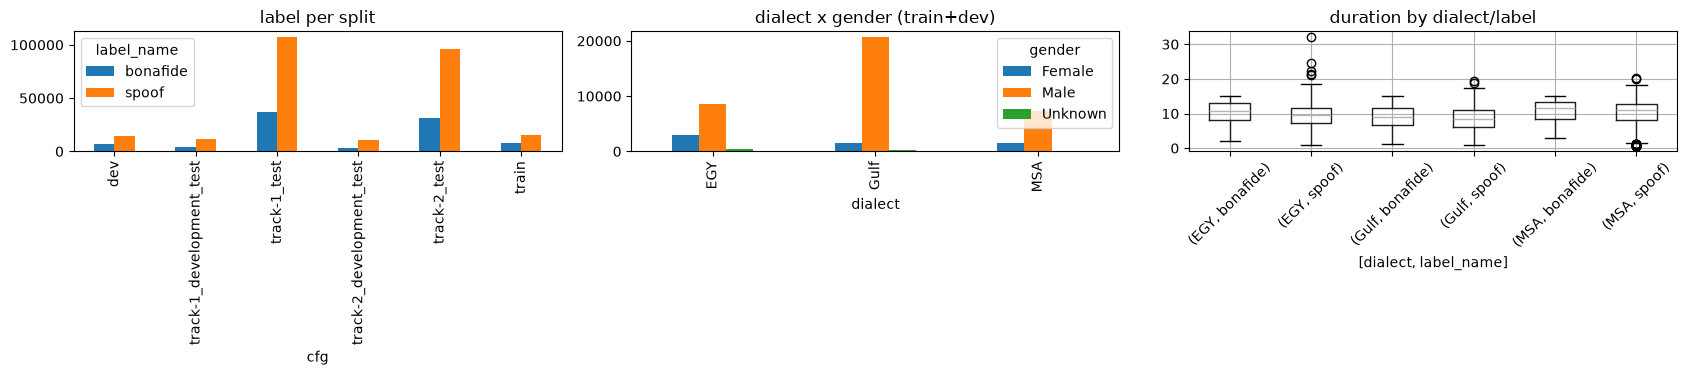

1b_EDA_narrowband_spectrum.png


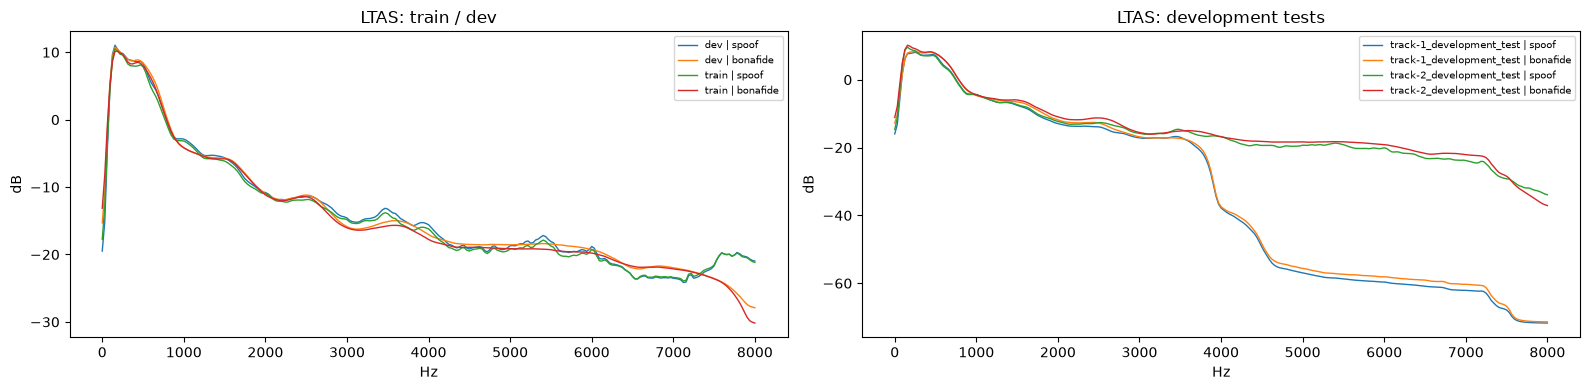

1c_split_statistics_table.png


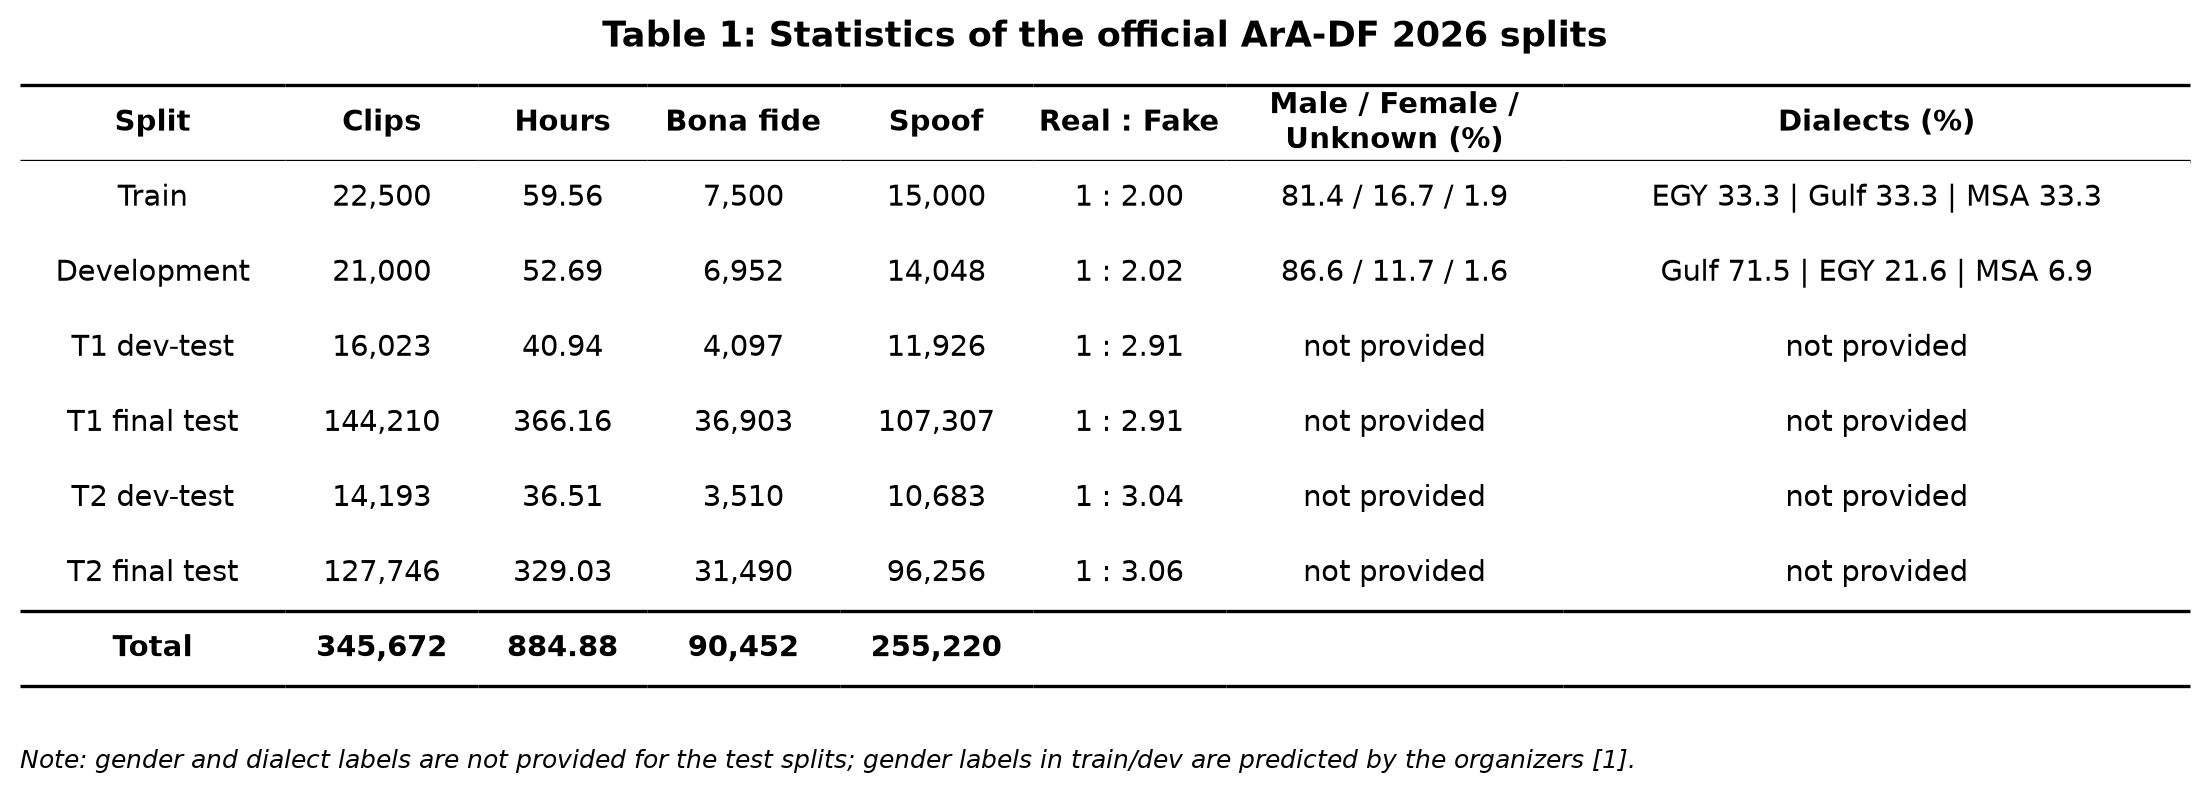

1e_acoustic_features_per_split.png


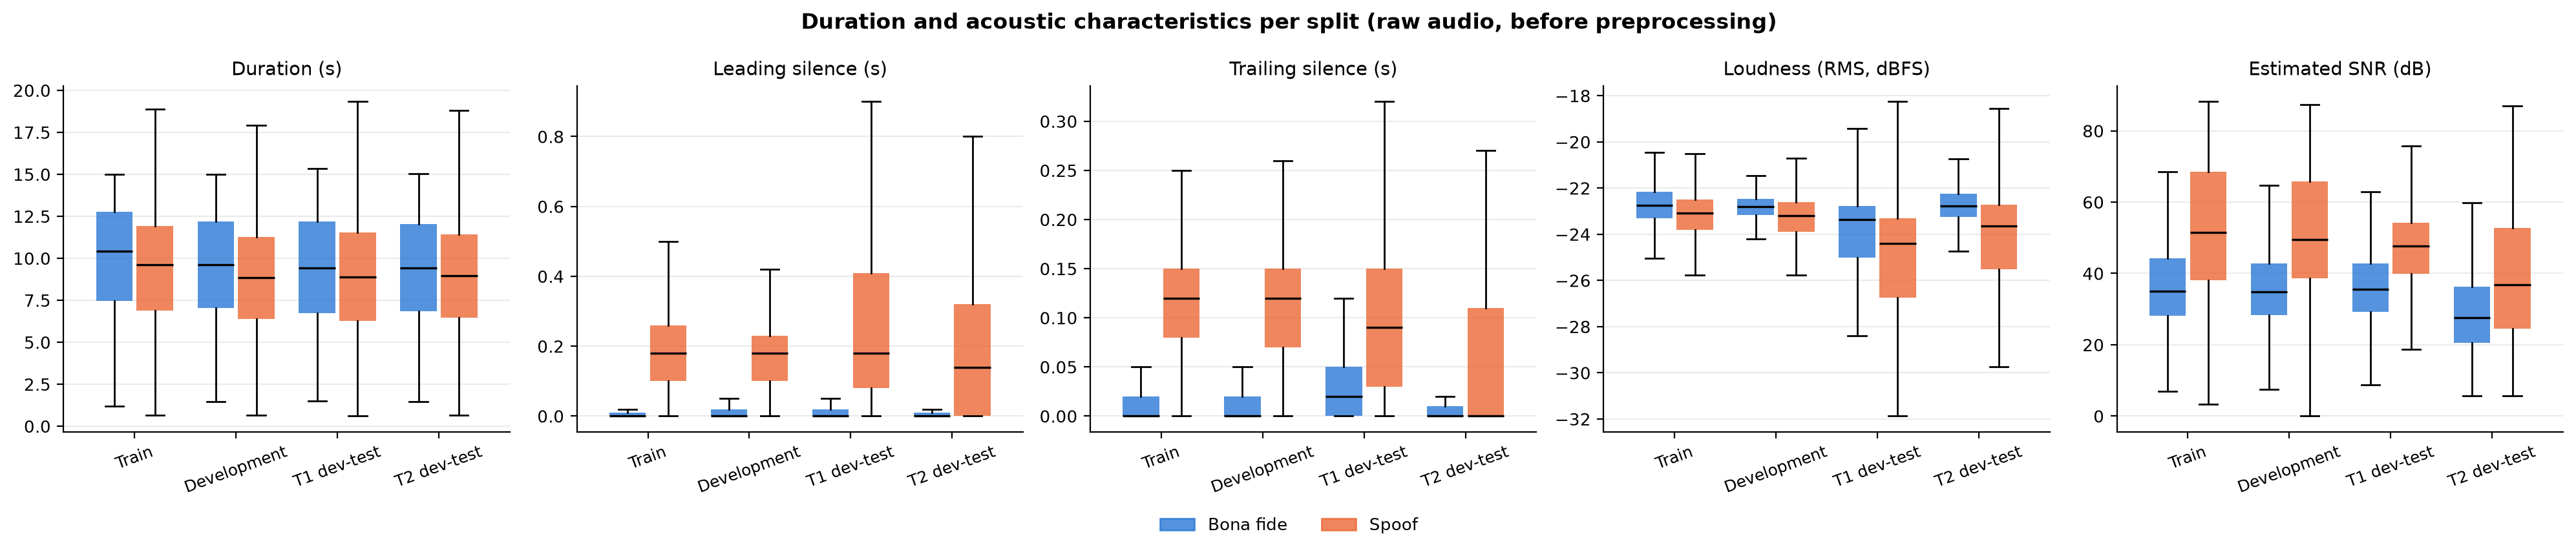

1f_silence_by_dialect_gender.png


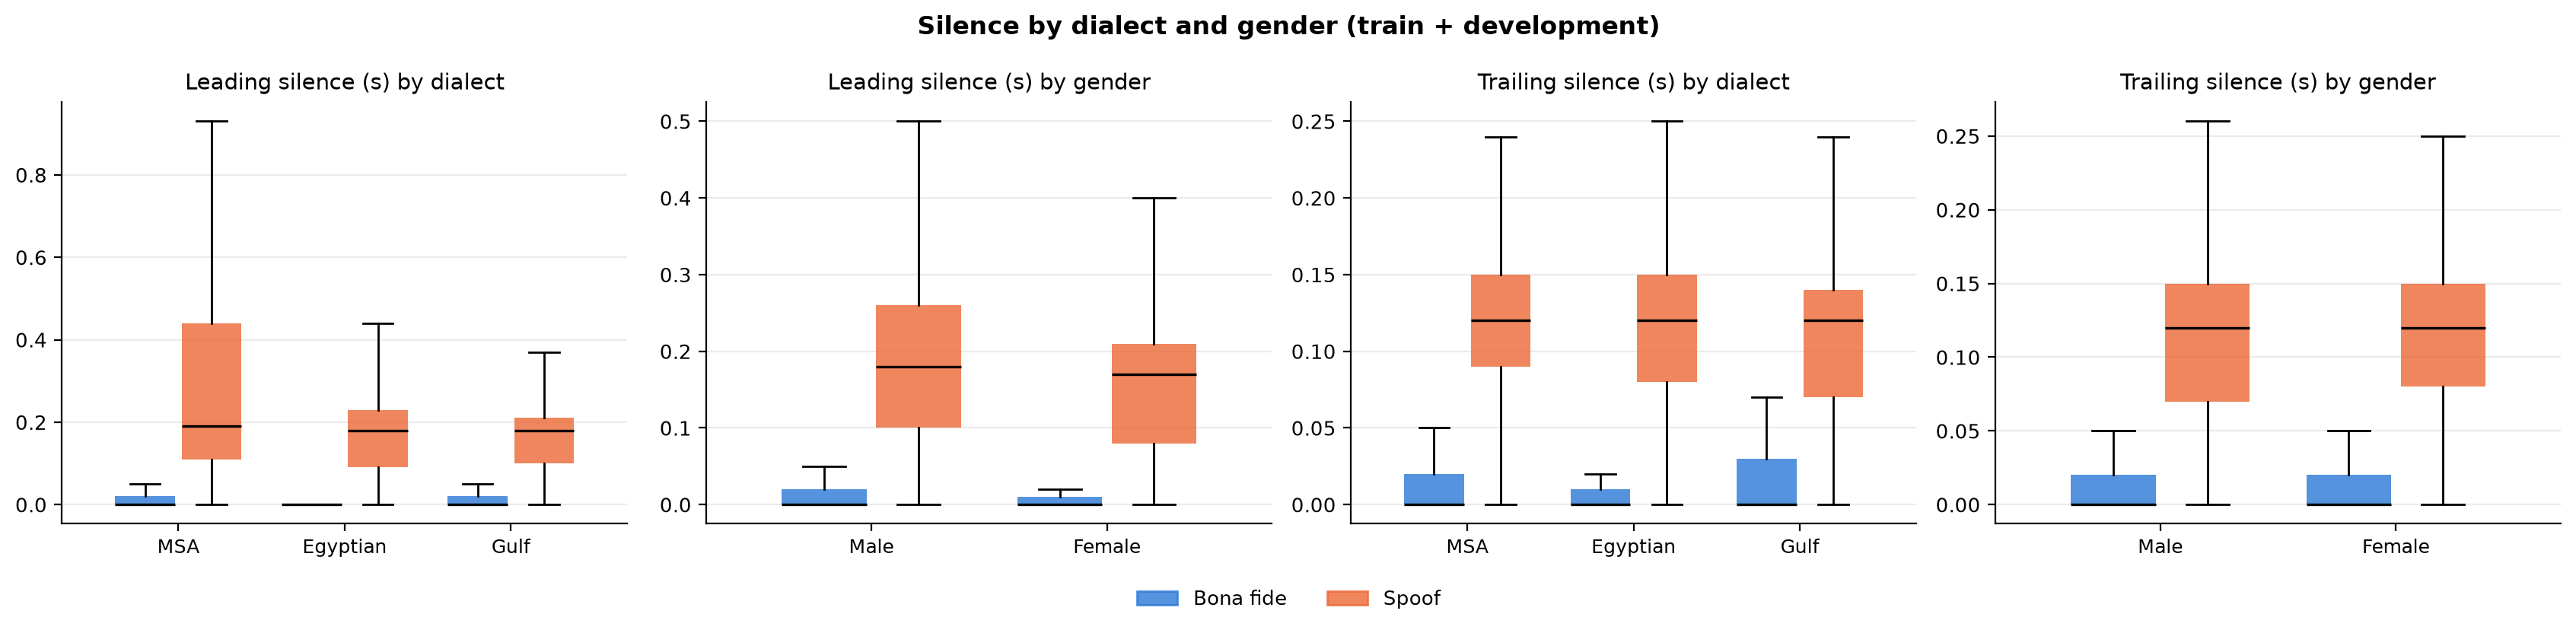

In [23]:
# A. Saved results
print("Clips per split (clean manifests; label 1 = bona fide, 0 = spoof)")
rows = []
for s in ["train", "dev", DT, "track-2_development_test", TEST, "track-2_test"]:
    p = os.path.join(ART, "manifests", f"{s}.csv")
    if not os.path.exists(p): continue
    m = manifest(s)
    rows.append(dict(split=s, clips=len(m), bona_fide=int(m.label.sum()), spoof=int((m.label == 0).sum()),
                     spoof_pct=round(100 * (m.label == 0).mean(), 1), hours=round(m.duration_sec.sum() / 3600, 2)))
display(pd.DataFrame(rows))
for name, title in [("split_statistics.csv", "Split statistics (before cleaning)"),
                    ("manifest_summary.csv", "Cleaning: rows, dropped and kept clips"),
                    ("shortcut_audit.csv", "Shortcut audit: EER (%) of one simple feature on its own (50 = no shortcut)"),
                    ("silence_by_dialect_gender.csv", "Leading / trailing silence by dialect and gender")]:
    d = read_csv(name, ART)
    if d is not None:
        print("\n" + title); display(d)
iss = read_csv("data_issues.csv", ART)
if iss is not None:
    print("\nData issues (drop = removed from train/dev; test splits are only flagged)")
    display(iss.groupby(["cfg", "reason", "drop"]).size().unstack("drop", fill_value=0))
af = read_csv("acoustic_features.csv", ART)
if af is not None:
    print("\nAcoustic features, median per split and label (1 = bona fide)")
    display(af.groupby(["split", "label"])[["duration", "rms_db", "lead_sil", "trail_sil", "snr_est"]].median().round(2))
for f in ["1a_EDA_labels_dialect_gender_duration.png", "1b_EDA_narrowband_spectrum.png", "1c_split_statistics_table.png",
          "1e_acoustic_features_per_split.png", "1f_silence_by_dialect_gender.png"]:
    show_png(f)

---
# B. WPT training
- Learning-rate search on XLS-R 300M (1e-4, 1e-5, 1e-6), then WavLM Large with the chosen lr.
- Recipe: Adam, weight decay 1e-4, ExponentialLR 0.9, batch 32, up to 20 epochs, patience 5, class weights [0.3, 0.7].
- The epoch is chosen on dev EER. T1 dev-test gives the threshold.

In [24]:
# B0. Training jobs
WPT_JOBS = [("xlsr300m", 1e-4), ("xlsr300m", 1e-5), ("xlsr300m", 1e-6), ("wavlm_large", 1e-4)]
JOB = WPT_JOBS[0]

In [25]:
%%step RUN_TRAINING
# B1. Environment
import sys, os, json, time, math, platform, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "transformers==5.18.0",
                    "huggingface-hub==1.33.0", "codecarbon==3.3.2", "soundfile"], check=True)
    from google.colab import drive
    drive.mount("/content/drive")

import numpy as np, pandas as pd, torch, transformers, huggingface_hub
assert torch.cuda.is_available(), "No GPU: Runtime > Change runtime type > L4"
if transformers.__version__ != "5.18.0":
    print("WARNING: transformers", transformers.__version__, "is loaded. Restart the session (Runtime > Restart session) and run cell 1 again.")
GPU_NAME = torch.cuda.get_device_name(0)
GPU_GB = torch.cuda.get_device_properties(0).total_memory / 2**30

print("Python", platform.python_version(), "| torch", torch.__version__, "| transformers", transformers.__version__,
      "| huggingface_hub", huggingface_hub.__version__)
print(f"GPU: {GPU_NAME} | {GPU_GB:.1f} GB | bf16: {torch.cuda.is_bf16_supported()} | CPU cores: {os.cpu_count()}")

skipped (RUN_TRAINING = False)


In [26]:
%%step RUN_TRAINING --name wpt_settings
# B2. Settings
MODEL, LR = JOB
QUICK_TEST = False
FINAL_TEST_IN_TRAINING = False

HF_MODELS = {"xlsr300m": "facebook/wav2vec2-xls-r-300m", "wavlm_large": "microsoft/wavlm-large"}
REPO_ID = "ArabicSpeech/ArA-DF-2026"
REVISION = "2b1f042dc166b1d372841cb0d7110661ea5b2a93"
SEED = 42
DEVTEST = "track-1_development_test"

if IN_COLAB:
    PROJECT_ROOT = "/content/drive/MyDrive/nabra"
    AUDIO_ROOT = "/content/aradf_audio"
    RUNS_ROOT = os.path.join(PROJECT_ROOT, "runs")
else:
    PROJECT_ROOT = r"C:\Users\Aisha\OneDrive\سطح المكتب\vss\Grad"
    AUDIO_ROOT = r"C:\Users\Aisha\nabra_data\aradf_audio"
    RUNS_ROOT = r"C:\Users\Aisha\nabra_runs"
ART_DIR = os.path.join(PROJECT_ROOT, "artifacts", "aradf_eda")
RUN_DIR = os.path.join(RUNS_ROOT, f"{MODEL}__wpt__ftrecipe__lr{LR:g}__seed{SEED}" + ("__quicktest" if QUICK_TEST else ""))

CFG = dict(
    protocol="phase 1: WPT with the training recipe of the earlier full fine-tuning runs (no augmentation, selection on dev)",
    method="wavelet_prompt_tuning", model=MODEL, hf_model=HF_MODELS[MODEL], dataset=REPO_ID, revision=REVISION,
    seed=SEED,
    sample_rate=16000, max_len=64600,
    trim_silence=True, rms_dbfs=-23.0,
    augmentation=None,
    trainable="prompts + wavelet projection + AASIST + output layer; SSL encoder frozen",
    n_prompts=6, n_wavelet_prompts=4,
    wavelet="Haar, 1 level, along the feature dimension; Proj = Linear(d, d) shared by all layers",
    prompt_init="xavier uniform, bound sqrt(6 / 2d)",
    prompt_dropout=0.1,
    backbone_mode="eval",
    optimizer="adam", betas=(0.9, 0.999), lr=LR, weight_decay=1e-4,
    scheduler="exponential", gamma=0.9,
    batch_size=32, max_epochs=20, patience=5,
    monitor="dev EER, centre crop, min; stop after 5 epochs without improvement (as the full FT runs)",
    also_logged="T1 development-test EER, centre crop, every epoch (not used for selection)",
    same_as="wavlm_large__fullft / xlsr300m__fullft: Adam, wd 1e-4, ExponentialLR 0.9 per epoch, batch 32, "
            "max 20 epochs, patience 5, selection on dev EER, class weights [0.3, 0.7], no augmentation; only lr differs",
    class_weights=[0.3, 0.7],
    aasist=dict(filts=[70, [1, 32], [32, 32], [32, 64], [64, 64]], gat_dims=[64, 32],
                pool_ratios=[0.5, 0.7, 0.5, 0.5], temperatures=[2.0, 2.0, 100.0, 100.0]),
    score="logit_bonafide - logit_spoof",
    eval_in_training="one centre crop of 64,600 samples (dev and T1 dev-test)",
    final_eval="whole clip, consecutive 64,600-sample windows, mean score",
    threshold="EER threshold on T1 dev-test (whole clip), computed after training",
    precision="bf16 autocast",
    gradient_checkpointing=False,
    spec_augment=False,
)
if QUICK_TEST:
    CFG["max_epochs"] = 1
os.makedirs(RUN_DIR, exist_ok=True)

import random
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.benchmark = False
set_seed(CFG["seed"])
print("model:", CFG["hf_model"], "| run folder:", RUN_DIR, "| final test: part D")

skipped (RUN_TRAINING = False)


In [27]:
%%step RUN_TRAINING
# B3. Data
import tarfile
from huggingface_hub import HfApi, hf_hub_download
HF_TOKEN = os.environ.get("HF_TOKEN")

assert os.path.isdir(os.path.join(ART_DIR, "manifests")), f"No manifests in {ART_DIR}."
with open(os.path.join(ART_DIR, "preprocessing_config.json"), encoding="utf-8") as f:
    PREP = json.load(f)
assert PREP["revision"] == REVISION, "Manifests were made from a different dataset version"
assert os.path.exists(os.path.join(ART_DIR, "manifests", f"{DEVTEST}.csv")), \
    f"Copy {DEVTEST}.csv into {os.path.join(ART_DIR, 'manifests')}"

def load_manifest(split):
    m = pd.read_csv(os.path.join(ART_DIR, "manifests", f"{split}.csv"), low_memory=False)
    return m[m["keep"].astype(bool)].reset_index(drop=True)

MAN = {s: load_manifest(s) for s in ["train", "dev", DEVTEST, "track-1_test"]}
for s, m in MAN.items():
    print(f"{s:25s} {len(m):7,d} clips | bona fide {int(m.label.sum()):6,d} | spoof {int((m.label == 0).sum()):7,d}")
assert [len(MAN[s]) for s in MAN] == [22482, 20998, 16023, 144210]
if QUICK_TEST:
    for s in ["train", "dev", DEVTEST]:
        MAN[s] = MAN[s].sample(64, random_state=CFG["seed"]).reset_index(drop=True)

def extract_split(split, ids):
    os.makedirs(os.path.join(AUDIO_ROOT, split), exist_ok=True)
    want = {i for i in ids if not os.path.exists(os.path.join(AUDIO_ROOT, split, f"{i}.flac"))}
    if not want:
        print(f"{split}: all {len(ids):,} clips already on disk"); return
    files = HfApi().list_repo_files(REPO_ID, repo_type="dataset", revision=REVISION, token=HF_TOKEN)
    tars = sorted(f for f in files if f.startswith(f"data/{split}/") and f.endswith(".tar"))
    t0 = time.time()
    for t in tars:
        local = hf_hub_download(REPO_ID, t, repo_type="dataset", revision=REVISION, token=HF_TOKEN)
        with tarfile.open(local) as tf:
            for mem in tf:
                if mem.isfile() and mem.name.endswith(".flac"):
                    cid = os.path.basename(mem.name)[:-5]
                    if cid in want:
                        with open(os.path.join(AUDIO_ROOT, split, f"{cid}.flac"), "wb") as f:
                            f.write(tf.extractfile(mem).read())
        print(f"  {t} | {time.time() - t0:.0f}s")
    missing = [i for i in ids if not os.path.exists(os.path.join(AUDIO_ROOT, split, f"{i}.flac"))]
    assert not missing, f"{split}: {len(missing)} clips missing after extraction"
    print(f"{split}: {len(ids):,} clips ready")

for s in ["train", "dev", DEVTEST]:
    extract_split(s, MAN[s]["id"].tolist())

skipped (RUN_TRAINING = False)


In [28]:
%%step RUN_TRAINING
# B4. Preprocessing and loaders
import soundfile as sf
SR, N = CFG["sample_rate"], CFG["max_len"]

def load_wave(path):
    x, sr = sf.read(path, dtype="float32", always_2d=False)
    if x.ndim > 1: x = x.mean(1)
    assert sr == SR, f"{path}: sr={sr}"
    return x

def trim_silence(x, top_db=40.0, frame=400, hop=160):
    if len(x) < frame: return x
    nf = 1 + (len(x) - frame) // hop
    idx = np.arange(frame)[None, :] + hop * np.arange(nf)[:, None]
    e = 10 * np.log10((x[idx] ** 2).mean(1) + 1e-10)
    v = np.flatnonzero(e > e.max() - top_db)
    return x[v[0] * hop: v[-1] * hop + frame] if len(v) else x

def rms_normalize(x, target_dbfs=-23.0):
    rms = np.sqrt(np.mean(x ** 2) + 1e-12)
    return np.clip(x * (10 ** (target_dbfs / 20) / rms), -1, 1).astype(np.float32)

def clean_wave(x):
    if CFG["trim_silence"]: x = trim_silence(x)
    return rms_normalize(x, CFG["rms_dbfs"])

def crop_or_pad(x, n, mode, rng=None):
    if len(x) == 0: return np.zeros(n, np.float32)
    if len(x) < n: x = np.tile(x, int(np.ceil(n / len(x))))
    if len(x) == n: return x
    if mode == "random": start = rng.randint(0, len(x) - n + 1)
    elif mode == "center": start = (len(x) - n) // 2
    else: start = 0
    return x[start:start + n]

def make_windows(x, n):
    if len(x) <= n: return crop_or_pad(x, n, "start")[None, :]
    starts = list(range(0, len(x) - n + 1, n))
    if starts[-1] + n < len(x): starts.append(len(x) - n)
    return np.stack([x[s:s + n] for s in starts])

class AraDF(torch.utils.data.Dataset):
    def __init__(self, manifest, mode):
        self.ids = manifest["id"].tolist(); self.labels = manifest["label"].astype(int).tolist()
        self.paths = manifest["path"].tolist(); self.mode = mode
        self.rng = np.random.RandomState(CFG["seed"])
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        x = clean_wave(load_wave(os.path.join(AUDIO_ROOT, self.paths[i])))
        w = make_windows(x, N) if self.mode == "windows" else crop_or_pad(x, N, self.mode, self.rng)[None, :]
        return torch.from_numpy(np.ascontiguousarray(w, dtype=np.float32)), self.labels[i], self.ids[i]

def seed_worker(worker_id):
    info = torch.utils.data.get_worker_info()
    info.dataset.rng = np.random.RandomState(torch.initial_seed() % 2**32)

def collate(batch):
    waves = torch.cat([b[0] for b in batch])
    return waves, torch.tensor([b[1] for b in batch]), [b[2] for b in batch], [b[0].shape[0] for b in batch]

NUM_WORKERS = min(8, os.cpu_count() or 1) if IN_COLAB else 0
def make_loader(ds, batch_size, shuffle, epoch=0):
    g = torch.Generator(); g.manual_seed(CFG["seed"] + epoch)
    if NUM_WORKERS == 0: ds.rng = np.random.RandomState(CFG["seed"] + epoch)
    return torch.utils.data.DataLoader(ds, batch_size=batch_size, shuffle=shuffle, drop_last=shuffle,
                                       num_workers=NUM_WORKERS, worker_init_fn=seed_worker if NUM_WORKERS else None,
                                       generator=g, collate_fn=collate, pin_memory=True)

ds_train = AraDF(MAN["train"], "random")
ds_dev, ds_devtest = AraDF(MAN["dev"], "center"), AraDF(MAN[DEVTEST], "center")

t0, n_b = time.time(), 0
for xb, yb, _, _ in make_loader(ds_train, CFG["batch_size"], shuffle=True):
    n_b += 1
    if n_b == 12: break
LOAD_S = (time.time() - t0) / n_b
print("train batch:", tuple(xb.shape), "| bona fide share:", round(float(yb.float().mean()), 2),
      f"| data loading: {LOAD_S:.2f}s per batch ({NUM_WORKERS} workers, includes start-up)")
xd, _, _, cd = next(iter(make_loader(ds_devtest, 8, shuffle=False)))
print("T1 dev-test batch (centre crop):", tuple(xd.shape), "| windows per clip:", cd)
del xb, yb, xd

skipped (RUN_TRAINING = False)


In [29]:
%%step RUN_TRAINING or RUN_FINAL_TEST or RUN_XAI --name aasist
# B5. AASIST back end
# Adapted from DeepFense (Apache License 2.0): github.com/Yaselley/deepfense-framework
import random
from typing import Union
import torch.nn as nn
import torch.nn.functional as F
from torch import Tensor

class GraphAttentionLayer(nn.Module):
    def __init__(self, in_dim, out_dim, **kwargs):
        super().__init__()

        self.att_proj = nn.Linear(in_dim, out_dim)
        self.att_weight = self._init_new_params(out_dim, 1)

        self.proj_with_att = nn.Linear(in_dim, out_dim)
        self.proj_without_att = nn.Linear(in_dim, out_dim)

        self.bn = nn.BatchNorm1d(out_dim)

        self.input_drop = nn.Dropout(p=0.2)

        self.act = nn.SELU(inplace=True)

        self.temp = 1.0
        if "temperature" in kwargs:
            self.temp = kwargs["temperature"]

    def forward(self, x):
        x = self.input_drop(x)

        att_map = self._derive_att_map(x)

        x = self._project(x, att_map)

        x = self._apply_BN(x)
        x = self.act(x)
        return x

    def _pairwise_mul_nodes(self, x):

        nb_nodes = x.size(1)
        x = x.unsqueeze(2).expand(-1, -1, nb_nodes, -1)
        x_mirror = x.transpose(1, 2)

        return x * x_mirror

    def _derive_att_map(self, x):
        att_map = self._pairwise_mul_nodes(x)
        att_map = torch.tanh(self.att_proj(att_map))
        att_map = torch.matmul(att_map, self.att_weight)

        att_map = att_map / self.temp

        att_map = F.softmax(att_map, dim=-2)

        return att_map

    def _project(self, x, att_map):
        x1 = self.proj_with_att(torch.matmul(att_map.squeeze(-1), x))
        x2 = self.proj_without_att(x)

        return x1 + x2

    def _apply_BN(self, x):
        org_size = x.size()
        x = x.view(-1, org_size[-1])
        x = self.bn(x)
        x = x.view(org_size)

        return x

    def _init_new_params(self, *size):
        out = nn.Parameter(torch.FloatTensor(*size))
        nn.init.xavier_normal_(out)
        return out

class HtrgGraphAttentionLayer(nn.Module):
    def __init__(self, in_dim, out_dim, **kwargs):
        super().__init__()

        self.proj_type1 = nn.Linear(in_dim, in_dim)
        self.proj_type2 = nn.Linear(in_dim, in_dim)

        self.att_proj = nn.Linear(in_dim, out_dim)
        self.att_projM = nn.Linear(in_dim, out_dim)

        self.att_weight11 = self._init_new_params(out_dim, 1)
        self.att_weight22 = self._init_new_params(out_dim, 1)
        self.att_weight12 = self._init_new_params(out_dim, 1)
        self.att_weightM = self._init_new_params(out_dim, 1)

        self.proj_with_att = nn.Linear(in_dim, out_dim)
        self.proj_without_att = nn.Linear(in_dim, out_dim)

        self.proj_with_attM = nn.Linear(in_dim, out_dim)
        self.proj_without_attM = nn.Linear(in_dim, out_dim)

        self.bn = nn.BatchNorm1d(out_dim)

        self.input_drop = nn.Dropout(p=0.2)

        self.act = nn.SELU(inplace=True)

        self.temp = 1.0
        if "temperature" in kwargs:
            self.temp = kwargs["temperature"]

    def forward(self, x1, x2, master=None):
        num_type1 = x1.size(1)
        num_type2 = x2.size(1)

        x1 = self.proj_type1(x1)
        x2 = self.proj_type2(x2)

        x = torch.cat([x1, x2], dim=1)

        if master is None:
            master = torch.mean(x, dim=1, keepdim=True)

        x = self.input_drop(x)

        att_map = self._derive_att_map(x, num_type1, num_type2)

        master = self._update_master(x, master)

        x = self._project(x, att_map)

        x = self._apply_BN(x)
        x = self.act(x)

        x1 = x.narrow(1, 0, num_type1)
        x2 = x.narrow(1, num_type1, num_type2)

        return x1, x2, master

    def _update_master(self, x, master):
        att_map = self._derive_att_map_master(x, master)
        master = self._project_master(x, master, att_map)

        return master

    def _pairwise_mul_nodes(self, x):

        nb_nodes = x.size(1)
        x = x.unsqueeze(2).expand(-1, -1, nb_nodes, -1)
        x_mirror = x.transpose(1, 2)

        return x * x_mirror

    def _derive_att_map_master(self, x, master):
        att_map = x * master
        att_map = torch.tanh(self.att_projM(att_map))

        att_map = torch.matmul(att_map, self.att_weightM)

        att_map = att_map / self.temp

        att_map = F.softmax(att_map, dim=-2)

        return att_map

    def _derive_att_map(self, x, num_type1, num_type2):
        att_map = self._pairwise_mul_nodes(x)
        att_map = torch.tanh(self.att_proj(att_map))

        att_board = torch.zeros_like(att_map[:, :, :, 0]).unsqueeze(-1)

        att_board[:, :num_type1, :num_type1, :] = torch.matmul(
            att_map[:, :num_type1, :num_type1, :], self.att_weight11
        )
        att_board[:, num_type1:, num_type1:, :] = torch.matmul(
            att_map[:, num_type1:, num_type1:, :], self.att_weight22
        )
        att_board[:, :num_type1, num_type1:, :] = torch.matmul(
            att_map[:, :num_type1, num_type1:, :], self.att_weight12
        )
        att_board[:, num_type1:, :num_type1, :] = torch.matmul(
            att_map[:, num_type1:, :num_type1, :], self.att_weight12
        )

        att_map = att_board

        att_map = att_map / self.temp

        att_map = F.softmax(att_map, dim=-2)

        return att_map

    def _project(self, x, att_map):
        x1 = self.proj_with_att(torch.matmul(att_map.squeeze(-1), x))
        x2 = self.proj_without_att(x)

        return x1 + x2

    def _project_master(self, x, master, att_map):
        x1 = self.proj_with_attM(torch.matmul(att_map.squeeze(-1).unsqueeze(1), x))
        x2 = self.proj_without_attM(master)

        return x1 + x2

    def _apply_BN(self, x):
        org_size = x.size()
        x = x.view(-1, org_size[-1])
        x = self.bn(x)
        x = x.view(org_size)

        return x

    def _init_new_params(self, *size):
        out = nn.Parameter(torch.FloatTensor(*size))
        nn.init.xavier_normal_(out)
        return out

class GraphPool(nn.Module):
    def __init__(self, k: float, in_dim: int, p: Union[float, int]):
        super().__init__()
        self.k = k
        self.sigmoid = nn.Sigmoid()
        self.proj = nn.Linear(in_dim, 1)
        self.drop = nn.Dropout(p=p) if p > 0 else nn.Identity()
        self.in_dim = in_dim

    def forward(self, h):
        Z = self.drop(h)
        weights = self.proj(Z)
        scores = self.sigmoid(weights)
        new_h = self.top_k_graph(scores, h, self.k)

        return new_h

    def top_k_graph(self, scores, h, k):
        _, n_nodes, n_feat = h.size()
        n_nodes = max(int(n_nodes * k), 1)
        _, idx = torch.topk(scores, n_nodes, dim=1)
        idx = idx.expand(-1, -1, n_feat)

        h = h * scores
        h = torch.gather(h, 1, idx)

        return h

class Residual_block(nn.Module):
    def __init__(self, nb_filts, pool=(1, 3), first=False):
        super().__init__()
        self.first = first

        if not self.first:
            self.bn1 = nn.BatchNorm2d(num_features=nb_filts[0])
        self.conv1 = nn.Conv2d(
            in_channels=nb_filts[0],
            out_channels=nb_filts[1],
            kernel_size=(2, 3),
            padding=(1, 1),
            stride=1,
        )
        self.selu = nn.SELU(inplace=True)

        self.bn2 = nn.BatchNorm2d(num_features=nb_filts[1])
        self.conv2 = nn.Conv2d(
            in_channels=nb_filts[1],
            out_channels=nb_filts[1],
            kernel_size=(2, 3),
            padding=(0, 1),
            stride=1,
        )

        if nb_filts[0] != nb_filts[1]:
            self.downsample = True
            self.conv_downsample = nn.Conv2d(
                in_channels=nb_filts[0],
                out_channels=nb_filts[1],
                padding=(0, 1),
                kernel_size=(1, 3),
                stride=1,
            )

        else:
            self.downsample = False
        self.mp = nn.MaxPool2d(pool)

    def forward(self, x):
        identity = x
        if not self.first:
            out = self.bn1(x)
            out = self.selu(out)
        else:
            out = x
        out = self.conv1(x)
        out = self.bn2(out)
        out = self.selu(out)
        out = self.conv2(out)

        if self.downsample:
            identity = self.conv_downsample(identity)

        out += identity
        return out

class AASIST(nn.Module):
    def __init__(self, input_dim=1024, filts=(70, [1, 32], [32, 32], [32, 64], [64, 64]), gat_dims=(64, 32),
                 pool_ratios=(0.5, 0.7, 0.5, 0.5), temperatures=(2.0, 2.0, 100.0, 100.0)):
        super().__init__()
        self.LL = nn.Linear(input_dim, 128)

        self.first_bn = nn.BatchNorm2d(num_features=1)
        self.first_bn1 = nn.BatchNorm2d(num_features=64)
        self.drop = nn.Dropout(0.5, inplace=True)
        self.drop_way = nn.Dropout(0.2, inplace=True)
        self.selu = nn.SELU(inplace=True)

        self.encoder = nn.Sequential(
            nn.Sequential(Residual_block(nb_filts=filts[1], first=True)),
            nn.Sequential(Residual_block(nb_filts=filts[2])),
            nn.Sequential(Residual_block(nb_filts=filts[3])),
            nn.Sequential(Residual_block(nb_filts=filts[4])),
            nn.Sequential(Residual_block(nb_filts=filts[4])),
            nn.Sequential(Residual_block(nb_filts=filts[4])),
        )

        self.attention = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=(1, 1)),
            nn.SELU(inplace=True),
            nn.BatchNorm2d(128),
            nn.Conv2d(128, 64, kernel_size=(1, 1)),
        )
        self.pos_S = nn.Parameter(torch.randn(1, 42, filts[-1][-1]))

        self.master1 = nn.Parameter(torch.randn(1, 1, gat_dims[0]))
        self.master2 = nn.Parameter(torch.randn(1, 1, gat_dims[0]))

        self.GAT_layer_S = GraphAttentionLayer(
            filts[-1][-1], gat_dims[0], temperature=temperatures[0]
        )
        self.GAT_layer_T = GraphAttentionLayer(
            filts[-1][-1], gat_dims[0], temperature=temperatures[1]
        )
        self.HtrgGAT_layer_ST11 = HtrgGraphAttentionLayer(
            gat_dims[0], gat_dims[1], temperature=temperatures[2]
        )
        self.HtrgGAT_layer_ST12 = HtrgGraphAttentionLayer(
            gat_dims[1], gat_dims[1], temperature=temperatures[2]
        )
        self.HtrgGAT_layer_ST21 = HtrgGraphAttentionLayer(
            gat_dims[0], gat_dims[1], temperature=temperatures[2]
        )
        self.HtrgGAT_layer_ST22 = HtrgGraphAttentionLayer(
            gat_dims[1], gat_dims[1], temperature=temperatures[2]
        )

        self.pool_S = GraphPool(pool_ratios[0], gat_dims[0], 0.3)
        self.pool_T = GraphPool(pool_ratios[1], gat_dims[0], 0.3)
        self.pool_hS1 = GraphPool(pool_ratios[2], gat_dims[1], 0.3)
        self.pool_hT1 = GraphPool(pool_ratios[2], gat_dims[1], 0.3)

        self.pool_hS2 = GraphPool(pool_ratios[2], gat_dims[1], 0.3)
        self.pool_hT2 = GraphPool(pool_ratios[2], gat_dims[1], 0.3)

    def forward(self, x):
        x = self.LL(x)
        x = x.transpose(1, 2)
        x = x.unsqueeze(dim=1)
        x = F.max_pool2d(x, (3, 3))
        x = self.first_bn(x)
        x = self.selu(x)

        x = self.encoder(x)
        x = self.first_bn1(x)
        x = self.selu(x)

        w = self.attention(x)

        w1 = F.softmax(w, dim=-1)
        m = torch.sum(x * w1, dim=-1)
        e_S = m.transpose(1, 2) + self.pos_S

        gat_S = self.GAT_layer_S(e_S)
        out_S = self.pool_S(gat_S)

        w2 = F.softmax(w, dim=-2)
        m1 = torch.sum(x * w2, dim=-2)

        e_T = m1.transpose(1, 2)

        gat_T = self.GAT_layer_T(e_T)
        out_T = self.pool_T(gat_T)

        master1 = self.master1.expand(x.size(0), -1, -1)
        master2 = self.master2.expand(x.size(0), -1, -1)

        out_T1, out_S1, master1 = self.HtrgGAT_layer_ST11(
            out_T, out_S, master=self.master1
        )

        out_S1 = self.pool_hS1(out_S1)
        out_T1 = self.pool_hT1(out_T1)

        out_T_aug, out_S_aug, master_aug = self.HtrgGAT_layer_ST12(
            out_T1, out_S1, master=master1
        )
        out_T1 = out_T1 + out_T_aug
        out_S1 = out_S1 + out_S_aug
        master1 = master1 + master_aug

        out_T2, out_S2, master2 = self.HtrgGAT_layer_ST21(
            out_T, out_S, master=self.master2
        )
        out_S2 = self.pool_hS2(out_S2)
        out_T2 = self.pool_hT2(out_T2)

        out_T_aug, out_S_aug, master_aug = self.HtrgGAT_layer_ST22(
            out_T2, out_S2, master=master2
        )
        out_T2 = out_T2 + out_T_aug
        out_S2 = out_S2 + out_S_aug
        master2 = master2 + master_aug

        out_T1 = self.drop_way(out_T1)
        out_T2 = self.drop_way(out_T2)
        out_S1 = self.drop_way(out_S1)
        out_S2 = self.drop_way(out_S2)
        master1 = self.drop_way(master1)
        master2 = self.drop_way(master2)

        out_T = torch.max(out_T1, out_T2)
        out_S = torch.max(out_S1, out_S2)
        master = torch.max(master1, master2)

        T_max, _ = torch.max(torch.abs(out_T), dim=1)
        T_avg = torch.mean(out_T, dim=1)

        S_max, _ = torch.max(torch.abs(out_S), dim=1)
        S_avg = torch.mean(out_S, dim=1)

        last_hidden = torch.cat([T_max, T_avg, S_max, S_avg, master.squeeze(1)], dim=1)

        last_hidden = self.drop(last_hidden)

        return last_hidden

_t = AASIST(input_dim=1024, **CFG['aasist']).eval()
with torch.no_grad():
    _o = _t(torch.randn(2, 201, 1024))
print('AASIST output:', tuple(_o.shape), '(expected (2, 160)) | parameters:', sum(p.numel() for p in _t.parameters()))
assert tuple(_o.shape) == (2, 160)
del _t, _o

skipped (RUN_TRAINING or RUN_FINAL_TEST or RUN_XAI = False)


In [30]:
%%step RUN_TRAINING --name wpt_model
# B6. WPT model
from transformers import AutoConfig, AutoModel, AutoFeatureExtractor
from torch.utils.checkpoint import checkpoint

def haar_dwt(q):
    even, odd = q[..., 0::2], q[..., 1::2]
    return (even + odd) / math.sqrt(2), (even - odd) / math.sqrt(2)

class WPTEncoder(nn.Module):
    def __init__(self, hf_name):
        super().__init__()
        conf = AutoConfig.from_pretrained(hf_name)
        conf.apply_spec_augment = CFG["spec_augment"]
        self.ssl = AutoModel.from_pretrained(hf_name, config=conf)
        self.ssl.requires_grad_(False)
        self.is_wavlm = conf.model_type == "wavlm"
        self.pre_ln = bool(conf.do_stable_layer_norm)
        L, d = conf.num_hidden_layers, conf.hidden_size
        assert d % 2 == 0
        self.n_p, self.n_w = CFG["n_prompts"], CFG["n_wavelet_prompts"]
        bound = math.sqrt(6.0 / (2 * d))
        self.P = nn.Parameter(torch.empty(L, self.n_p, d).uniform_(-bound, bound))
        self.Q = nn.Parameter(torch.empty(L, self.n_w, d).uniform_(-bound, bound))
        self.proj = nn.Linear(d, d)
        self.drop = nn.Dropout(CFG["prompt_dropout"])

    def train(self, mode=True):
        super().train(mode)
        self.ssl.eval()
        return self

    def forward(self, wav, use_prompts=True):
        B, enc = wav.shape[0], self.ssl.encoder
        with torch.no_grad():
            f = self.ssl.feature_extractor(wav).transpose(1, 2)
            h, _ = self.ssl.feature_projection(f)
            h = h + enc.pos_conv_embed(h)
            if not self.pre_ln:
                h = enc.layer_norm(h)
            h = enc.dropout(h)
        n = self.n_w + self.n_p if use_prompts else 0
        bias = None
        for i, layer in enumerate(enc.layers):
            if use_prompts:
                A, D = haar_dwt(self.Q[i])
                wp = self.drop(self.proj(torch.cat([A, D], -1)).expand(B, -1, -1))
                p = self.drop(self.P[i].expand(B, -1, -1))
                x = torch.cat([wp.to(h.dtype), p.to(h.dtype), h], 1)
            else:
                x = h
            if self.is_wavlm:
                run = lambda x, bias, layer=layer, i=i: layer(x, position_bias=bias, index=i)
            else:
                run = lambda x, bias, layer=layer: (layer(x), None)
            if CFG["gradient_checkpointing"] and self.training:
                x, bias = checkpoint(run, x, bias, use_reentrant=False)
            else:
                x, bias = run(x, bias)
            h = x[:, n:]
        if self.pre_ln:
            h = enc.layer_norm(h)
        return h

class Detector(nn.Module):
    def __init__(self, hf_name):
        super().__init__()
        self.enc = WPTEncoder(hf_name)
        self.do_normalize = bool(getattr(AutoFeatureExtractor.from_pretrained(hf_name), "do_normalize", False))
        self.backend = AASIST(input_dim=self.enc.ssl.config.hidden_size, **CFG["aasist"])
        self.fc = nn.Linear(5 * CFG["aasist"]["gat_dims"][1], 2)

    def forward(self, wav):
        if self.do_normalize:
            with torch.autocast("cuda", enabled=False):
                wav = wav.float()
                wav = (wav - wav.mean(1, keepdim=True)) / torch.sqrt(wav.var(1, keepdim=True, unbiased=False) + 1e-7)
        return self.fc(self.backend(self.enc(wav)))

def score_of(logits):
    return (logits[:, 1] - logits[:, 0]).float()

set_seed(CFG["seed"])
model = Detector(CFG["hf_model"]).cuda()
n_all = sum(p.numel() for p in model.parameters()); n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
n_prompt = model.enc.P.numel() + model.enc.Q.numel() + sum(p.numel() for p in model.enc.proj.parameters())
print(f"parameters: {n_all / 1e6:.1f}M | trainable: {n_train / 1e6:.2f}M ({100 * n_train / n_all:.2f}%) "
      f"| prompts + projection: {n_prompt / 1e6:.2f}M | input normalization: {model.do_normalize}")
assert all(not p.requires_grad for p in model.enc.ssl.parameters())

model.eval()
with torch.no_grad():
    w = 0.05 * torch.randn(2, CFG["max_len"], device="cuda")
    ref = model.enc.ssl(w).last_hidden_state
    diff = (model.enc(w, use_prompts=False) - ref).abs().max().item()
print(f"layer loop vs Hugging Face forward (no prompts): max difference {diff:.2e}")
assert diff < 1e-3
del w, ref

skipped (RUN_TRAINING = False)


In [31]:
%%step RUN_TRAINING --name wpt_microbatch
# B7. Micro-batch size
AMP = dict(device_type="cuda", dtype=torch.bfloat16)
W = torch.tensor(CFG["class_weights"], device="cuda")
crit_sum = nn.CrossEntropyLoss(weight=W, reduction="sum")
TRAINABLE = [p for p in model.parameters() if p.requires_grad]

state0 = {k: v.detach().clone() for k, v in model.state_dict().items()}
def probe(micro):
    opt = torch.optim.Adam(TRAINABLE, lr=CFG["lr"], betas=CFG["betas"], weight_decay=CFG["weight_decay"])
    x = 0.05 * torch.randn(micro, N, device="cuda"); y = torch.randint(0, 2, (micro,), device="cuda")
    model.train(); torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize(); t = time.time()
    with torch.autocast(**AMP):
        loss = crit_sum(model(x), y) / W[y].sum()
    loss.backward(); opt.step(); opt.zero_grad(set_to_none=True); torch.cuda.synchronize()
    dt, mem = time.time() - t, torch.cuda.max_memory_allocated() / 2**30
    del opt, x, y, loss
    return dt, mem

MICRO = None
for micro in [32, 16, 8, 4, 2, 1]:
    try:
        probe(micro); dt, mem = probe(micro)
        if mem < 0.9 * GPU_GB:
            MICRO = micro; break
    except torch.OutOfMemoryError:
        pass
    model.zero_grad(set_to_none=True); torch.cuda.empty_cache()
model.load_state_dict(state0); model.zero_grad(set_to_none=True); del state0; torch.cuda.empty_cache()
assert MICRO, "Not enough GPU memory even for one clip"
ACCUM = CFG["batch_size"] // MICRO
steps = len(MAN["train"]) // CFG["batch_size"]
print(f"micro-batch {MICRO} x accumulation {ACCUM} = batch {MICRO * ACCUM} | peak memory {mem:.1f} / {GPU_GB:.1f} GB")
print(f"{dt:.2f}s per micro-batch -> about {steps * ACCUM * dt / 60:.0f} min of GPU time per epoch for training (plus data loading and dev evaluation)")

skipped (RUN_TRAINING = False)


In [32]:
%%step RUN_TRAINING --name wpt_train
# B8. Training
from sklearn.metrics import roc_curve
from codecarbon import OfflineEmissionsTracker

def compute_eer(labels, scores):
    fpr, tpr, _ = roc_curve(np.asarray(labels), np.asarray(scores), pos_label=1)
    fnr = 1 - tpr; i = np.nanargmin(np.abs(fnr - fpr))
    return float(100 * (fpr[i] + fnr[i]) / 2)

@torch.no_grad()
def predict(ds, clips_per_batch, chunk=64):
    model.eval(); ids, labels, scores = [], [], []
    for waves, y, cid, counts in make_loader(ds, clips_per_batch, shuffle=False):
        out = []
        for part in waves.split(chunk):
            with torch.autocast(**AMP):
                out.append(score_of(model(part.cuda(non_blocking=True))).cpu())
        s = torch.cat(out)
        scores += [float(v.mean()) for v in s.split(counts)]; ids += cid; labels += y.tolist()
    return ids, labels, scores

LAST, BEST = os.path.join(RUN_DIR, "last.pt"), os.path.join(RUN_DIR, "best.pt")
DONE, LOG = os.path.join(RUN_DIR, "train_done.json"), os.path.join(RUN_DIR, "train_log.csv")

with open(os.path.join(RUN_DIR, "config.json"), "w", encoding="utf-8") as f:
    json.dump({**CFG, "micro_batch": MICRO, "grad_accumulation": ACCUM, "gpu": GPU_NAME,
               "torch": torch.__version__, "transformers": transformers.__version__,
               "train_clips": len(MAN["train"]), "dev_clips": len(MAN["dev"]), "devtest_clips": len(MAN[DEVTEST]),
               "trainable_parameters": n_train, "total_parameters": n_all}, f, indent=2)

optimizer = torch.optim.Adam(TRAINABLE, lr=CFG["lr"], betas=CFG["betas"], weight_decay=CFG["weight_decay"])
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=CFG["gamma"])
start_epoch, best_eer, bad, history = 1, math.inf, 0, []
if os.path.exists(LAST) and not os.path.exists(DONE):
    ck = torch.load(LAST, map_location="cuda", weights_only=False)
    model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"]); scheduler.load_state_dict(ck["scheduler"])
    torch.set_rng_state(ck["rng_cpu"].cpu()); torch.cuda.set_rng_state_all([r.cpu() for r in ck["rng_cuda"]])
    start_epoch, best_eer, bad, history = ck["epoch"] + 1, ck["best_eer"], ck["bad"], ck["history"]
    del ck
    print(f"resuming after epoch {start_epoch - 1} | best dev EER so far {best_eer:.3f}%")

if os.path.exists(DONE):
    print("Training already finished:", json.load(open(DONE)))
else:
    tracker = OfflineEmissionsTracker(country_iso_code="SAU", output_dir=RUN_DIR, output_file="emissions_train.csv",
                                      project_name=f"{MODEL}__wpt__ftrecipe__train", tracking_mode="machine", gpu_ids=[0],
                                      measure_power_secs=5, pue=1.0, log_level="error", allow_multiple_runs=True)
    tracker.start()
    try:
        for epoch in range(start_epoch, CFG["max_epochs"] + 1):
            model.train(); t0 = time.time(); total, weight = 0.0, 0.0
            for xb, yb, _, _ in make_loader(ds_train, CFG["batch_size"], shuffle=True, epoch=epoch):
                xb, yb = xb.cuda(non_blocking=True), yb.cuda(non_blocking=True)
                w_batch = W[yb].sum()
                optimizer.zero_grad(set_to_none=True)
                for xm, ym in zip(xb.split(MICRO), yb.split(MICRO)):
                    with torch.autocast(**AMP):
                        loss = crit_sum(model(xm), ym) / w_batch
                    loss.backward(); total += float(loss.detach()) * float(w_batch)
                weight += float(w_batch)
                optimizer.step()
            lr = optimizer.param_groups[0]["lr"]; scheduler.step()
            t_train = time.time() - t0
            dev_eer = compute_eer(*predict(ds_dev, 64)[1:])
            devtest_eer = compute_eer(*predict(ds_devtest, 64)[1:])
            improved = dev_eer < best_eer
            if improved:
                best_eer, bad = dev_eer, 0
                torch.save({"model": model.state_dict(), "epoch": epoch, "devtest_eer": devtest_eer, "dev_eer": dev_eer,
                            "cfg": CFG}, BEST + ".tmp")
                os.replace(BEST + ".tmp", BEST)
            else:
                bad += 1
            history.append(dict(epoch=epoch, lr=lr, train_loss=total / weight, dev_eer=dev_eer, devtest_eer=devtest_eer,
                                best=improved, train_min=t_train / 60, total_min=(time.time() - t0) / 60))
            pd.DataFrame(history).to_csv(LOG, index=False)
            torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(),
                        "epoch": epoch, "best_eer": best_eer, "bad": bad, "history": history,
                        "rng_cpu": torch.get_rng_state(), "rng_cuda": torch.cuda.get_rng_state_all()}, LAST + ".tmp")
            os.replace(LAST + ".tmp", LAST)
            stop = bad >= CFG["patience"]
            print(f"epoch {epoch:2d} | loss {total / weight:.4f} | dev EER {dev_eer:.3f}% | T1 dev-test EER {devtest_eer:.3f}% "
                  f"{'(best on dev) ' if improved else ''}| {(time.time() - t0) / 60:.1f} min" + (" | early stop" if stop else ""))
            if stop:
                break
        best_epoch = max(h["epoch"] for h in history if h["best"])
        devtest_at_best = next(h["devtest_eer"] for h in history if h["epoch"] == best_epoch)
        summary = dict(best_epoch=best_epoch, best_dev_eer_centre_crop=best_eer,
                       devtest_eer_centre_crop_at_best_epoch=devtest_at_best, epochs_run=history[-1]["epoch"])
        json.dump(summary, open(DONE, "w"), indent=2)
        os.remove(LAST)
        print("training finished:", summary)
    finally:
        tracker.stop()

skipped (RUN_TRAINING = False)


In [33]:
%%step RUN_TRAINING --name wpt_eval
# B9. Evaluation
from sklearn.metrics import roc_auc_score
ck = torch.load(BEST, map_location="cuda", weights_only=False)
model.load_state_dict(ck["model"])
print(f"best checkpoint (chosen on dev): epoch {ck['epoch']} | dev EER {ck['dev_eer']:.3f}% | "
      f"T1 dev-test EER {ck['devtest_eer']:.3f}% (centre crop)")

def eer_thr(y, s):
    fpr, tpr, thr = roc_curve(y, s, drop_intermediate=False)
    i = np.nanargmin(np.abs(1 - tpr - fpr))
    return float(100 * (fpr[i] + 1 - tpr[i]) / 2), float(thr[i])

splits = ["dev", DEVTEST] + (["track-1_test"] if FINAL_TEST_IN_TRAINING else [])
if FINAL_TEST_IN_TRAINING:
    extract_split("track-1_test", MAN["track-1_test"]["id"].tolist())
tracker = OfflineEmissionsTracker(country_iso_code="SAU", output_dir=RUN_DIR, output_file="emissions_eval.csv",
                                  project_name=f"{MODEL}__wpt__ftrecipe__eval", tracking_mode="machine", gpu_ids=[0],
                                  measure_power_secs=5, pue=1.0, log_level="error", allow_multiple_runs=True)
tracker.start()
metrics = dict(model=MODEL, method="wavelet_prompt_tuning", recipe="full FT recipe, no augmentation", lr=CFG["lr"],
               best_epoch=ck["epoch"], selected_on="dev EER", dev_eer_centre_crop=ck["dev_eer"],
               devtest_eer_centre_crop=ck["devtest_eer"])
try:
    for split in splits:
        t0 = time.time()
        ids, labels, scores = predict(AraDF(MAN[split], "windows"), 16)
        pd.DataFrame({"id": ids, "score": scores}).to_csv(os.path.join(RUN_DIR, f"{split}_scores.csv"), index=False)
        eer, thr = eer_thr(labels, scores)
        metrics[f"{split}_eer_whole_clip"] = eer
        metrics[f"{split}_auc"] = 100 * roc_auc_score(labels, scores)
        if split == DEVTEST:
            metrics["threshold_from_devtest"] = thr
        if split == "track-1_test":
            pred = (np.asarray(scores) >= metrics["threshold_from_devtest"]).astype(int); y = np.asarray(labels)
            metrics["track-1_test_accuracy_at_devtest_threshold"] = 100 * float((pred == y).mean())
            metrics["track-1_test_frr_at_devtest_threshold"] = 100 * float((pred[y == 1] == 0).mean())
            metrics["track-1_test_far_at_devtest_threshold"] = 100 * float((pred[y == 0] == 1).mean())
        print(f"{split}: EER {eer:.3f}% | {len(ids):,} clips | {(time.time() - t0) / 60:.1f} min")
finally:
    tracker.stop()
json.dump(metrics, open(os.path.join(RUN_DIR, "metrics.json"), "w"), indent=2)
print(json.dumps(metrics, indent=2))
print("Files in", RUN_DIR, ":", sorted(os.listdir(RUN_DIR)))

skipped (RUN_TRAINING = False)


In [34]:
%%step RUN_TRAINING
# B10. Remaining WPT jobs
import gc
for JOB in WPT_JOBS[1:]:
    print("\n==========", JOB)
    for v in ["model", "optimizer", "scheduler", "TRAINABLE", "ck"]:
        globals().pop(v, None)
    gc.collect(); torch.cuda.empty_cache()
    rerun("wpt_settings", "wpt_model", "wpt_microbatch", "wpt_train", "wpt_eval")

skipped (RUN_TRAINING = False)


Learning-rate search (chosen: lr 1e-4)


,lr,best_epoch,dev_EER,devtest_EER,devtest_AUC,threshold
0,1e-4,18,0.057,6.06,98.51,10.46
1,1e-5,20,0.633,7.45,97.78,6.64
2,1e-6,20,12.340,20.25,87.21,0.71


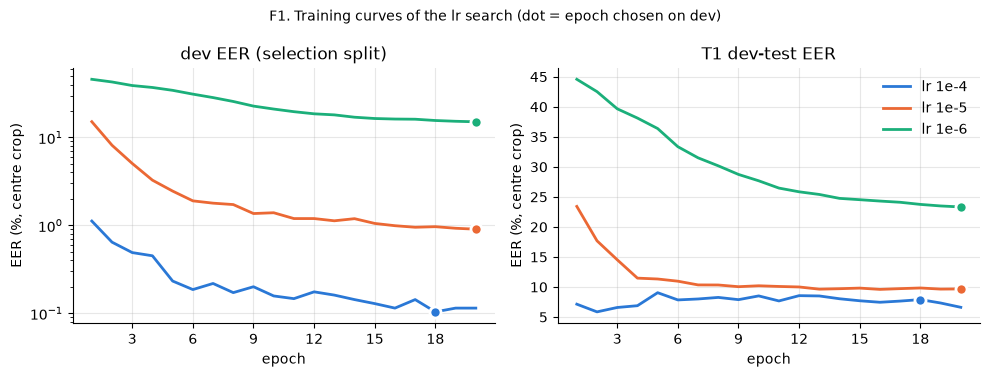

Encoder comparison (Full FT trained with lr 1e-6)


,system,best_epoch,devtest_EER,devtest_AUC
0,XLS-R WPT,18,6.06,98.51
1,WavLM WPT,20,6.44,98.25
2,XLS-R Full FT,20,16.51,90.41
3,WavLM Full FT,19,20.00,88.18


In [35]:
# B. Saved results
from matplotlib.ticker import MaxNLocator
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2})
HP = {"1e-4": "xlsr300m__wpt__ftrecipe__lr0.0001__seed42", "1e-5": "xlsr300m__wpt__ftrecipe__lr1e-05__seed42",
      "1e-6": "xlsr300m__wpt__ftrecipe__lr1e-06__seed42"}
rows, logs = [], {}
for lr, run in HP.items():
    m = metrics_of(run)
    if m is None: print("[not found]", run); continue
    logs[lr] = pd.read_csv(os.path.join(RUNS, run, "train_log.csv"))
    rows.append(dict(lr=lr, best_epoch=m["best_epoch"], dev_EER=round(m["dev_eer_whole_clip"], 3),
                     devtest_EER=round(m[f"{DT}_eer_whole_clip"], 2), devtest_AUC=round(m[f"{DT}_auc"], 2),
                     threshold=round(m["threshold_from_devtest"], 2)))
print("Learning-rate search (chosen: lr 1e-4)"); display(pd.DataFrame(rows))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True)
for c, (lr, log) in zip(COLORS, logs.items()):
    for a, col in zip(ax, ["dev_eer", "devtest_eer"]):
        a.plot(log.epoch, log[col], color=c, label=f"lr {lr}")
        b = log[log.best.astype(bool)].epoch.max()
        a.plot(b, log.loc[log.epoch == b, col], "o", color=c, ms=8, mec="white", mew=2)
ax[0].set(title="dev EER (selection split)", xlabel="epoch", ylabel="EER (%, centre crop)", yscale="log")
ax[1].set(title="T1 dev-test EER", xlabel="epoch", ylabel="EER (%, centre crop)")
for a in ax: a.xaxis.set_major_locator(MaxNLocator(integer=True))
ax[1].legend(frameon=False); fig.suptitle("F1. Training curves of the lr search (dot = epoch chosen on dev)", fontsize=10)
fig.tight_layout(); fig.savefig(os.path.join(OUT_ROOT, "F1_lr_search_curves.png"), dpi=200, bbox_inches="tight"); plt.show()

ENC = {"XLS-R WPT": "xlsr300m__wpt__ftrecipe__lr0.0001__seed42", "WavLM WPT": "wavlm_large__wpt__ftrecipe__lr0.0001__seed42",
       "XLS-R Full FT": "xlsr300m__fullft", "WavLM Full FT": "wavlm_large__fullft"}
rows = []
for name, run in ENC.items():
    m = metrics_of(run); p = os.path.join(RUNS, run, "devtest_metrics.json")
    if m is not None and f"{DT}_eer_whole_clip" in m:
        rows.append(dict(system=name, best_epoch=m["best_epoch"], devtest_EER=m[f"{DT}_eer_whole_clip"], devtest_AUC=m[f"{DT}_auc"]))
    elif m is not None and os.path.exists(p):
        d = json.load(open(p)); rows.append(dict(system=name, best_epoch=m["best_epoch"], devtest_EER=d["devtest_eer_whole_clip"],
                                                 devtest_AUC=d["devtest_auc"]))
print("Encoder comparison (Full FT trained with lr 1e-6)")
display(pd.DataFrame(rows).round(2))

In [36]:
# Bootstrap 95% CIs on T1 dev-test
def bootstrap_ci(systems, pairs, seed=42):
    ref = manifest(DT)[["id", "label"]].astype({"label": int})
    S = {}
    for name, run in systems.items():
        p = os.path.join(RUNS, run, f"{DT}_scores.csv")
        if not os.path.exists(p): print("[not found]", p); continue
        m = ref.merge(pd.read_csv(p), on="id", how="left", validate="one_to_one")
        assert m["score"].notna().all(), f"{name}: clips without a score"
        S[name] = m["score"].to_numpy()
    y = ref["label"].to_numpy(); rng = np.random.default_rng(seed)
    pos, neg = np.flatnonzero(y == 1), np.flatnonzero(y == 0)
    B = {n: np.empty(N_BOOT) for n in S}
    for b in range(N_BOOT):
        idx = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
        for n, s in S.items():
            fpr, tpr, _ = roc_curve(y[idx], s[idx]); i = np.nanargmin(np.abs(1 - tpr - fpr))
            B[n][b] = 100 * (fpr[i] + 1 - tpr[i]) / 2
    ci = pd.DataFrame([dict(system=n, eer=eer_pct(y, s), ci_low=np.percentile(B[n], 2.5), ci_high=np.percentile(B[n], 97.5))
                       for n, s in S.items()])
    diffs = []
    for a, b_ in pairs:
        if a not in S or b_ not in S: continue
        d = B[a] - B[b_]; lo, hi = np.percentile(d, [2.5, 97.5])
        diffs.append(dict(comparison=f"{a} - {b_}", eer_diff=eer_pct(y, S[a]) - eer_pct(y, S[b_]), ci_low=lo, ci_high=hi,
                          ci_excludes_0=bool(hi < 0 or lo > 0)))
    return ci, pd.DataFrame(diffs)

t0 = time.time()
CI_ENC, DIFF_ENC = bootstrap_ci(ENC, [("XLS-R WPT", "WavLM WPT"), ("XLS-R WPT", "XLS-R Full FT"), ("WavLM WPT", "WavLM Full FT")])
RATIO = {"Head": "xlsr300m__head__ftrecipe__lr0.0001__seed42", "WPT": "xlsr300m__wpt__ftrecipe__lr0.0001__seed42",
         "LoRA": "xlsr300m__lora_r8__ftrecipe__lr0.0001__seed42",
         "Partial": "xlsr300m__partial6__ftrecipe__lr0.0001_enc1e-05__seed42", "Full FT": "xlsr300m__fullft"}
CI_RATIO, DIFF_RATIO = bootstrap_ci(RATIO, [("Partial", "WPT"), ("Head", "WPT"), ("LoRA", "WPT"), ("Full FT", "WPT")])
print(f"{N_BOOT} resamples | {(time.time() - t0) / 60:.1f} min | negative difference = first system better\n")
for t in [CI_ENC, DIFF_ENC, CI_RATIO, DIFF_RATIO]:
    display(t.round(2))
for t, f in [(CI_ENC, "devtest_eer_ci.csv"), (DIFF_ENC, "devtest_eer_diff_ci.csv"),
             (CI_RATIO, "ratio_devtest_eer_ci.csv"), (DIFF_RATIO, "ratio_devtest_eer_diff_ci.csv")]:
    t.to_csv(os.path.join(OUT_ROOT, f), index=False)

2000 resamples | 1.0 min | negative difference = first system better



,system,eer,ci_low,ci_high
0,XLS-R WPT,6.06,5.64,6.46
1,WavLM WPT,6.44,5.98,6.85
2,XLS-R Full FT,16.51,15.80,17.26
3,WavLM Full FT,20.00,19.23,20.85


,comparison,eer_diff,ci_low,ci_high,ci_excludes_0
0,XLS-R WPT - WavLM WPT,-0.38,-0.84,0.11,False
1,XLS-R WPT - XLS-R Full FT,-10.46,-11.26,-9.72,True
2,WavLM WPT - WavLM Full FT,-13.56,-14.47,-12.76,True


,system,eer,ci_low,ci_high
0,Head,6.49,6.00,6.94
1,WPT,6.06,5.64,6.46
2,LoRA,13.70,13.15,14.27
3,Partial,5.95,5.53,6.36
4,Full FT,16.51,15.80,17.26


,comparison,eer_diff,ci_low,ci_high,ci_excludes_0
0,Partial - WPT,-0.11,-0.56,0.36,False
1,Head - WPT,0.43,-0.09,0.98,False
2,LoRA - WPT,7.64,7.13,8.18,True
3,Full FT - WPT,10.46,9.72,11.26,True


---
# C. Trainable parameters
Head, LoRA r=8 and Partial (last 6 layers, encoder lr 1e-5) on XLS-R 300M, with the recipe of part B. Then full fine-tuning (all weights, lr 1e-6) on XLS-R 300M and WavLM Large.

In [37]:
# C0. Training jobs
RATIO_JOBS = ["head", "lora", "partial"]
JOB_STRATEGY = RATIO_JOBS[0]

In [38]:
%%step RUN_TRAINING
# C1. Free GPU memory
import gc
for v in ['model', 'optimizer', 'scheduler', 'TRAINABLE', 'ck']:
    globals().pop(v, None)
gc.collect(); torch.cuda.empty_cache()

skipped (RUN_TRAINING = False)


In [39]:
%%step RUN_TRAINING --name ratio_settings
# C2. Settings
STRATEGY = JOB_STRATEGY
MODEL = "xlsr300m"
LR = 1e-4
LR_ENCODER = 1e-5
N_UNFROZEN = 6
QUICK_TEST = False
FINAL_TEST_IN_TRAINING = False

HF_MODELS = {"xlsr300m": "facebook/wav2vec2-xls-r-300m", "wavlm_large": "microsoft/wavlm-large"}
REPO_ID = "ArabicSpeech/ArA-DF-2026"
REVISION = "2b1f042dc166b1d372841cb0d7110661ea5b2a93"
SEED = 42
DEVTEST = "track-1_development_test"

if IN_COLAB:
    PROJECT_ROOT = "/content/drive/MyDrive/nabra"
    AUDIO_ROOT = "/content/aradf_audio"
    RUNS_ROOT = os.path.join(PROJECT_ROOT, "runs")
else:
    PROJECT_ROOT = r"C:\Users\Aisha\OneDrive\سطح المكتب\vss\Grad"
    AUDIO_ROOT = r"C:\Users\Aisha\nabra_data\aradf_audio"
    RUNS_ROOT = r"C:\Users\Aisha\nabra_runs"
ART_DIR = os.path.join(PROJECT_ROOT, "artifacts", "aradf_eda")
assert STRATEGY in ("head", "lora", "partial"), STRATEGY
TAG = {"head": "head", "lora": "lora_r8", "partial": f"partial{N_UNFROZEN}"}[STRATEGY]
LR_TAG = f"lr{LR:g}" + (f"_enc{LR_ENCODER:g}" if STRATEGY == "partial" else "")
RUN_DIR = os.path.join(RUNS_ROOT, f"{MODEL}__{TAG}__ftrecipe__{LR_TAG}__seed{SEED}" + ("__quicktest" if QUICK_TEST else ""))

CFG = dict(
    protocol="phase 1: % trainable parameters, training recipe of the earlier full fine-tuning runs (no augmentation, selection on dev)",
    method={"head": "head_only", "lora": "lora", "partial": "partial_finetuning"}[STRATEGY], model=MODEL, hf_model=HF_MODELS[MODEL], dataset=REPO_ID, revision=REVISION,
    seed=SEED,
    sample_rate=16000, max_len=64600,
    trim_silence=True, rms_dbfs=-23.0,
    augmentation=None,
    trainable={"head": "AASIST + output layer; SSL encoder frozen",
               "lora": "LoRA on q/k/v/out projections of all layers + AASIST + output layer; SSL encoder frozen",
               "partial": f"last {N_UNFROZEN} transformer layers + final encoder LayerNorm + AASIST + output layer"}[STRATEGY],
    lora=dict(r=8, alpha=32, dropout=0.1, targets=["q_proj", "k_proj", "v_proj", "out_proj"]) if STRATEGY == "lora" else None,
    n_unfrozen_layers=N_UNFROZEN if STRATEGY == "partial" else 0,
    backbone_mode="frozen parts in eval mode; unfrozen layers (partial) in train mode",
    lr_encoder=LR_ENCODER if STRATEGY == "partial" else None,
    optimizer="adam", betas=(0.9, 0.999), lr=LR, weight_decay=1e-4,
    scheduler="exponential", gamma=0.9,
    batch_size=32, max_epochs=20, patience=5,
    monitor="dev EER, centre crop, min; stop after 5 epochs without improvement (as the full FT runs)",
    also_logged="T1 development-test EER, centre crop, every epoch (not used for selection)",
    same_as="wavlm_large__fullft / xlsr300m__fullft: Adam, wd 1e-4, ExponentialLR 0.9 per epoch, batch 32, "
            "max 20 epochs, patience 5, selection on dev EER, class weights [0.3, 0.7], no augmentation; only lr differs",
    class_weights=[0.3, 0.7],
    aasist=dict(filts=[70, [1, 32], [32, 32], [32, 64], [64, 64]], gat_dims=[64, 32],
                pool_ratios=[0.5, 0.7, 0.5, 0.5], temperatures=[2.0, 2.0, 100.0, 100.0]),
    score="logit_bonafide - logit_spoof",
    eval_in_training="one centre crop of 64,600 samples (dev and T1 dev-test)",
    final_eval="whole clip, consecutive 64,600-sample windows, mean score",
    threshold="EER threshold on T1 dev-test (whole clip), computed after training",
    precision="bf16 autocast",
    gradient_checkpointing=False,
    spec_augment=False,
)
if QUICK_TEST:
    CFG["max_epochs"] = 1
os.makedirs(RUN_DIR, exist_ok=True)

import random
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.benchmark = False
set_seed(CFG["seed"])
print("model:", CFG["hf_model"], "| run folder:", RUN_DIR, "| final test: part D")

skipped (RUN_TRAINING = False)


In [40]:
%%step RUN_TRAINING --name ratio_model
# C3. Model: Head / LoRA / Partial
from transformers import AutoConfig, AutoModel, AutoFeatureExtractor

class LoRALinear(nn.Module):
    def __init__(self, base, r, alpha, dropout):
        super().__init__()
        self.base = base
        self.lora_A = nn.Linear(base.in_features, r, bias=False)
        self.lora_B = nn.Linear(r, base.out_features, bias=False)
        nn.init.kaiming_uniform_(self.lora_A.weight, a=math.sqrt(5)); nn.init.zeros_(self.lora_B.weight)
        self.drop, self.scale = nn.Dropout(dropout), alpha / r

    def forward(self, x):
        return self.base(x) + self.lora_B(self.lora_A(self.drop(x))) * self.scale

class Detector(nn.Module):
    def __init__(self, hf_name):
        super().__init__()
        conf = AutoConfig.from_pretrained(hf_name)
        conf.apply_spec_augment = CFG["spec_augment"]
        self.ssl = AutoModel.from_pretrained(hf_name, config=conf)
        self.ssl.requires_grad_(False)
        self.train_layers = []
        if STRATEGY == "lora":
            lc = CFG["lora"]
            for layer in self.ssl.encoder.layers:
                for name in lc["targets"]:
                    setattr(layer.attention, name, LoRALinear(getattr(layer.attention, name), lc["r"], lc["alpha"], lc["dropout"]))
        elif STRATEGY == "partial":
            self.train_layers = list(self.ssl.encoder.layers[-N_UNFROZEN:])
            for layer in self.train_layers:
                layer.requires_grad_(True)
            self.ssl.encoder.layer_norm.requires_grad_(True)
        self.do_normalize = bool(getattr(AutoFeatureExtractor.from_pretrained(hf_name), "do_normalize", False))
        self.backend = AASIST(input_dim=conf.hidden_size, **CFG["aasist"])
        self.fc = nn.Linear(5 * CFG["aasist"]["gat_dims"][1], 2)

    def train(self, mode=True):
        super().train(mode)
        self.ssl.eval()
        for layer in self.train_layers:
            layer.train(mode)
        if STRATEGY == "lora":
            for m in self.ssl.modules():
                if isinstance(m, LoRALinear):
                    m.drop.train(mode)
        return self

    def forward(self, wav):
        if self.do_normalize:
            with torch.autocast("cuda", enabled=False):
                wav = wav.float()
                wav = (wav - wav.mean(1, keepdim=True)) / torch.sqrt(wav.var(1, keepdim=True, unbiased=False) + 1e-7)
        return self.fc(self.backend(self.ssl(wav).last_hidden_state))

def score_of(logits):
    return (logits[:, 1] - logits[:, 0]).float()

set_seed(CFG["seed"])
model = Detector(CFG["hf_model"]).cuda()
NEW = [p for n, p in model.named_parameters() if p.requires_grad and (not n.startswith("ssl.") or ".lora_" in n)]
PRE = [p for n, p in model.named_parameters() if p.requires_grad and n.startswith("ssl.") and ".lora_" not in n]
PARAM_GROUPS = [{"params": NEW, "lr": LR}] + ([{"params": PRE, "lr": LR_ENCODER}] if PRE else [])
n_all = sum(p.numel() for p in model.parameters()); n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
n_new, n_pre = sum(p.numel() for p in NEW), sum(p.numel() for p in PRE)
print(f"strategy: {STRATEGY} | parameters: {n_all / 1e6:.1f}M | trainable: {n_train / 1e6:.2f}M ({100 * n_train / n_all:.2f}%) "
      f"| new (lr {LR:g}): {n_new / 1e6:.2f}M | pretrained (lr {LR_ENCODER:g}): {n_pre / 1e6:.2f}M | input normalization: {model.do_normalize}")
assert n_new + n_pre == n_train
assert (n_pre > 0) == (STRATEGY == "partial")
if STRATEGY == "lora":
    model.eval()
    with torch.no_grad():
        w = 0.05 * torch.randn(2, CFG["max_len"], device="cuda")
        ref = AutoModel.from_pretrained(CFG["hf_model"]).cuda().eval()(w).last_hidden_state
        diff = (model.ssl(w).last_hidden_state - ref).abs().max().item()
    print(f"LoRA at initialisation vs original encoder: max difference {diff:.2e} (B = 0, so it must be ~0)")
    assert diff < 1e-3
    del w, ref; torch.cuda.empty_cache()

skipped (RUN_TRAINING = False)


In [41]:
%%step RUN_TRAINING --name ratio_microbatch
# C4. Micro-batch size
AMP = dict(device_type="cuda", dtype=torch.bfloat16)
W = torch.tensor(CFG["class_weights"], device="cuda")
crit_sum = nn.CrossEntropyLoss(weight=W, reduction="sum")
TRAINABLE = [p for p in model.parameters() if p.requires_grad]

state0 = {k: v.detach().clone() for k, v in model.state_dict().items()}
def probe(micro):
    opt = torch.optim.Adam(PARAM_GROUPS, lr=CFG["lr"], betas=CFG["betas"], weight_decay=CFG["weight_decay"])
    x = 0.05 * torch.randn(micro, N, device="cuda"); y = torch.randint(0, 2, (micro,), device="cuda")
    model.train(); torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize(); t = time.time()
    with torch.autocast(**AMP):
        loss = crit_sum(model(x), y) / W[y].sum()
    loss.backward(); opt.step(); opt.zero_grad(set_to_none=True); torch.cuda.synchronize()
    dt, mem = time.time() - t, torch.cuda.max_memory_allocated() / 2**30
    del opt, x, y, loss
    return dt, mem

MICRO = None
for micro in [32, 16, 8, 4, 2, 1]:
    try:
        probe(micro); dt, mem = probe(micro)
        if mem < 0.9 * GPU_GB:
            MICRO = micro; break
    except torch.OutOfMemoryError:
        pass
    model.zero_grad(set_to_none=True); torch.cuda.empty_cache()
model.load_state_dict(state0); model.zero_grad(set_to_none=True); del state0; torch.cuda.empty_cache()
assert MICRO, "Not enough GPU memory even for one clip"
ACCUM = CFG["batch_size"] // MICRO
steps = len(MAN["train"]) // CFG["batch_size"]
print(f"micro-batch {MICRO} x accumulation {ACCUM} = batch {MICRO * ACCUM} | peak memory {mem:.1f} / {GPU_GB:.1f} GB")
print(f"{dt:.2f}s per micro-batch -> about {steps * ACCUM * dt / 60:.0f} min of GPU time per epoch for training (plus data loading and dev evaluation)")

skipped (RUN_TRAINING = False)


In [42]:
%%step RUN_TRAINING --name ratio_train
# C5. Training
from sklearn.metrics import roc_curve
from codecarbon import OfflineEmissionsTracker

def compute_eer(labels, scores):
    fpr, tpr, _ = roc_curve(np.asarray(labels), np.asarray(scores), pos_label=1)
    fnr = 1 - tpr; i = np.nanargmin(np.abs(fnr - fpr))
    return float(100 * (fpr[i] + fnr[i]) / 2)

@torch.no_grad()
def predict(ds, clips_per_batch, chunk=64):
    model.eval(); ids, labels, scores = [], [], []
    for waves, y, cid, counts in make_loader(ds, clips_per_batch, shuffle=False):
        out = []
        for part in waves.split(chunk):
            with torch.autocast(**AMP):
                out.append(score_of(model(part.cuda(non_blocking=True))).cpu())
        s = torch.cat(out)
        scores += [float(v.mean()) for v in s.split(counts)]; ids += cid; labels += y.tolist()
    return ids, labels, scores

LAST, BEST = os.path.join(RUN_DIR, "last.pt"), os.path.join(RUN_DIR, "best.pt")
DONE, LOG = os.path.join(RUN_DIR, "train_done.json"), os.path.join(RUN_DIR, "train_log.csv")

with open(os.path.join(RUN_DIR, "config.json"), "w", encoding="utf-8") as f:
    json.dump({**CFG, "micro_batch": MICRO, "grad_accumulation": ACCUM, "gpu": GPU_NAME,
               "torch": torch.__version__, "transformers": transformers.__version__,
               "train_clips": len(MAN["train"]), "dev_clips": len(MAN["dev"]), "devtest_clips": len(MAN[DEVTEST]),
               "trainable_parameters": n_train, "total_parameters": n_all,
               "trainable_new_parameters": n_new, "trainable_pretrained_parameters": n_pre}, f, indent=2)

optimizer = torch.optim.Adam(PARAM_GROUPS, lr=CFG["lr"], betas=CFG["betas"], weight_decay=CFG["weight_decay"])
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=CFG["gamma"])
start_epoch, best_eer, bad, history = 1, math.inf, 0, []
if os.path.exists(LAST) and not os.path.exists(DONE):
    ck = torch.load(LAST, map_location="cuda", weights_only=False)
    model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"]); scheduler.load_state_dict(ck["scheduler"])
    torch.set_rng_state(ck["rng_cpu"].cpu()); torch.cuda.set_rng_state_all([r.cpu() for r in ck["rng_cuda"]])
    start_epoch, best_eer, bad, history = ck["epoch"] + 1, ck["best_eer"], ck["bad"], ck["history"]
    del ck
    print(f"resuming after epoch {start_epoch - 1} | best dev EER so far {best_eer:.3f}%")

if os.path.exists(DONE):
    print("Training already finished:", json.load(open(DONE)))
else:
    tracker = OfflineEmissionsTracker(country_iso_code="SAU", output_dir=RUN_DIR, output_file="emissions_train.csv",
                                      project_name=f"{MODEL}__{TAG}__ftrecipe__train", tracking_mode="machine", gpu_ids=[0],
                                      measure_power_secs=5, pue=1.0, log_level="error", allow_multiple_runs=True)
    tracker.start()
    try:
        for epoch in range(start_epoch, CFG["max_epochs"] + 1):
            model.train(); t0 = time.time(); total, weight = 0.0, 0.0
            for xb, yb, _, _ in make_loader(ds_train, CFG["batch_size"], shuffle=True, epoch=epoch):
                xb, yb = xb.cuda(non_blocking=True), yb.cuda(non_blocking=True)
                w_batch = W[yb].sum()
                optimizer.zero_grad(set_to_none=True)
                for xm, ym in zip(xb.split(MICRO), yb.split(MICRO)):
                    with torch.autocast(**AMP):
                        loss = crit_sum(model(xm), ym) / w_batch
                    loss.backward(); total += float(loss.detach()) * float(w_batch)
                weight += float(w_batch)
                optimizer.step()
            lr = optimizer.param_groups[0]["lr"]; lr_enc = optimizer.param_groups[-1]["lr"] if PRE else None; scheduler.step()
            t_train = time.time() - t0
            dev_eer = compute_eer(*predict(ds_dev, 64)[1:])
            devtest_eer = compute_eer(*predict(ds_devtest, 64)[1:])
            improved = dev_eer < best_eer
            if improved:
                best_eer, bad = dev_eer, 0
                torch.save({"model": model.state_dict(), "epoch": epoch, "devtest_eer": devtest_eer, "dev_eer": dev_eer,
                            "cfg": CFG}, BEST + ".tmp")
                os.replace(BEST + ".tmp", BEST)
            else:
                bad += 1
            history.append(dict(epoch=epoch, lr=lr, lr_encoder=lr_enc, train_loss=total / weight, dev_eer=dev_eer, devtest_eer=devtest_eer,
                                best=improved, train_min=t_train / 60, total_min=(time.time() - t0) / 60))
            pd.DataFrame(history).to_csv(LOG, index=False)
            torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(),
                        "epoch": epoch, "best_eer": best_eer, "bad": bad, "history": history,
                        "rng_cpu": torch.get_rng_state(), "rng_cuda": torch.cuda.get_rng_state_all()}, LAST + ".tmp")
            os.replace(LAST + ".tmp", LAST)
            stop = bad >= CFG["patience"]
            print(f"epoch {epoch:2d} | loss {total / weight:.4f} | dev EER {dev_eer:.3f}% | T1 dev-test EER {devtest_eer:.3f}% "
                  f"{'(best on dev) ' if improved else ''}| {(time.time() - t0) / 60:.1f} min" + (" | early stop" if stop else ""))
            if stop:
                break
        best_epoch = max(h["epoch"] for h in history if h["best"])
        devtest_at_best = next(h["devtest_eer"] for h in history if h["epoch"] == best_epoch)
        summary = dict(best_epoch=best_epoch, best_dev_eer_centre_crop=best_eer,
                       devtest_eer_centre_crop_at_best_epoch=devtest_at_best, epochs_run=history[-1]["epoch"])
        json.dump(summary, open(DONE, "w"), indent=2)
        os.remove(LAST)
        print("training finished:", summary)
    finally:
        tracker.stop()

skipped (RUN_TRAINING = False)


In [43]:
%%step RUN_TRAINING --name ratio_eval
# C6. Evaluation
from sklearn.metrics import roc_auc_score
ck = torch.load(BEST, map_location="cuda", weights_only=False)
model.load_state_dict(ck["model"])
print(f"best checkpoint (chosen on dev): epoch {ck['epoch']} | dev EER {ck['dev_eer']:.3f}% | "
      f"T1 dev-test EER {ck['devtest_eer']:.3f}% (centre crop)")

def eer_thr(y, s):
    fpr, tpr, thr = roc_curve(y, s, drop_intermediate=False)
    i = np.nanargmin(np.abs(1 - tpr - fpr))
    return float(100 * (fpr[i] + 1 - tpr[i]) / 2), float(thr[i])

splits = ["dev", DEVTEST] + (["track-1_test"] if FINAL_TEST_IN_TRAINING else [])
if FINAL_TEST_IN_TRAINING:
    extract_split("track-1_test", MAN["track-1_test"]["id"].tolist())
tracker = OfflineEmissionsTracker(country_iso_code="SAU", output_dir=RUN_DIR, output_file="emissions_eval.csv",
                                  project_name=f"{MODEL}__{TAG}__ftrecipe__eval", tracking_mode="machine", gpu_ids=[0],
                                  measure_power_secs=5, pue=1.0, log_level="error", allow_multiple_runs=True)
tracker.start()
metrics = dict(model=MODEL, method=CFG["method"], recipe="full FT recipe, no augmentation", lr=CFG["lr"],
               lr_encoder=CFG["lr_encoder"], trainable_parameters=n_train, total_parameters=n_all,
               trainable_percent=100 * n_train / n_all,
               best_epoch=ck["epoch"], selected_on="dev EER", dev_eer_centre_crop=ck["dev_eer"],
               devtest_eer_centre_crop=ck["devtest_eer"])
try:
    for split in splits:
        t0 = time.time()
        ids, labels, scores = predict(AraDF(MAN[split], "windows"), 16)
        pd.DataFrame({"id": ids, "score": scores}).to_csv(os.path.join(RUN_DIR, f"{split}_scores.csv"), index=False)
        eer, thr = eer_thr(labels, scores)
        metrics[f"{split}_eer_whole_clip"] = eer
        metrics[f"{split}_auc"] = 100 * roc_auc_score(labels, scores)
        if split == DEVTEST:
            metrics["threshold_from_devtest"] = thr
        if split == "track-1_test":
            pred = (np.asarray(scores) >= metrics["threshold_from_devtest"]).astype(int); y = np.asarray(labels)
            metrics["track-1_test_accuracy_at_devtest_threshold"] = 100 * float((pred == y).mean())
            metrics["track-1_test_frr_at_devtest_threshold"] = 100 * float((pred[y == 1] == 0).mean())
            metrics["track-1_test_far_at_devtest_threshold"] = 100 * float((pred[y == 0] == 1).mean())
        print(f"{split}: EER {eer:.3f}% | {len(ids):,} clips | {(time.time() - t0) / 60:.1f} min")
finally:
    tracker.stop()
json.dump(metrics, open(os.path.join(RUN_DIR, "metrics.json"), "w"), indent=2)
print(json.dumps(metrics, indent=2))
print("Files in", RUN_DIR, ":", sorted(os.listdir(RUN_DIR)))

skipped (RUN_TRAINING = False)


In [44]:
%%step RUN_TRAINING
# C7. Remaining jobs
for JOB_STRATEGY in RATIO_JOBS[1:]:
    print("\n==========", JOB_STRATEGY)
    for v in ["model", "optimizer", "scheduler", "TRAINABLE", "ck"]:
        globals().pop(v, None)
    gc.collect(); torch.cuda.empty_cache()
    rerun("ratio_settings", "ratio_model", "ratio_microbatch", "ratio_train", "ratio_eval")

skipped (RUN_TRAINING = False)


### Full fine-tuning
All weights trained, lr 1e-6, on XLS-R 300M and WavLM Large.

In [45]:
# C8. Full FT jobs
FT_JOBS = ["xlsr300m", "wavlm_large"]
FT_MODEL = FT_JOBS[0]

In [46]:
%%step RUN_TRAINING
# C9. Free GPU memory
for v in ['model', 'optimizer', 'scheduler', 'TRAINABLE', 'ck']:
    globals().pop(v, None)
gc.collect(); torch.cuda.empty_cache()

skipped (RUN_TRAINING = False)


In [47]:
%%step RUN_TRAINING --name ft_settings
# C10. Full FT settings
MODEL = FT_MODEL
QUICK_TEST = False

HF_MODELS = {"xlsr300m": "facebook/wav2vec2-xls-r-300m", "wavlm_large": "microsoft/wavlm-large"}
REPO_ID = "ArabicSpeech/ArA-DF-2026"
REVISION = "2b1f042dc166b1d372841cb0d7110661ea5b2a93"

if IN_COLAB:
    PROJECT_ROOT = "/content/drive/MyDrive/nabra"
    AUDIO_ROOT = "/content/aradf_audio"
else:
    PROJECT_ROOT = r"C:\Users\Aisha\OneDrive\سطح المكتب\vss\Grad"
    AUDIO_ROOT = r"C:\Users\Aisha\nabra_data\aradf_audio"
ART_DIR = os.path.join(PROJECT_ROOT, "artifacts", "aradf_eda")
RUN_DIR = os.path.join(PROJECT_ROOT, "runs", f"{MODEL}__fullft" + ("__quicktest" if QUICK_TEST else ""))

CFG = dict(
    method="full_finetuning", model=MODEL, hf_model=HF_MODELS[MODEL], dataset=REPO_ID, revision=REVISION,
    seed=42,
    sample_rate=16000, max_len=64600,
    trim_silence=True, rms_dbfs=-23.0,
    augmentation=None,
    trainable="all",
    optimizer="adam", lr=1e-6, weight_decay=1e-4,
    scheduler="exponential", gamma=0.9,
    batch_size=32,
    max_epochs=20, patience=5,
    monitor="dev EER, min",
    class_weights=[0.3, 0.7],
    aasist=dict(filts=[70, [1, 32], [32, 32], [32, 64], [64, 64]], gat_dims=[64, 32],
                pool_ratios=[0.5, 0.7, 0.5, 0.5], temperatures=[2.0, 2.0, 100.0, 100.0]),
    score="logit_bonafide - logit_spoof",
    dev_eval_in_training="one centre crop of 64,600 samples",
    final_eval="whole clip, consecutive 64,600-sample windows, mean score",
    precision="bf16 autocast",
    gradient_checkpointing=True,
    spec_augment=False,
)
if QUICK_TEST:
    CFG["max_epochs"] = 1
EVAL_SPLITS = ["dev"] if QUICK_TEST else ["dev", "track-1_test"]
os.makedirs(RUN_DIR, exist_ok=True)

import random
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.benchmark = False
set_seed(CFG["seed"])
print("model:", CFG["hf_model"], "| run folder:", RUN_DIR)

skipped (RUN_TRAINING = False)


In [48]:
%%step RUN_TRAINING
# C11. Data
import tarfile
from huggingface_hub import HfApi, hf_hub_download
HF_TOKEN = os.environ.get("HF_TOKEN")

assert os.path.isdir(os.path.join(ART_DIR, "manifests")), f"No manifests in {ART_DIR}. Run section 10b or add the shared folder to My Drive."
with open(os.path.join(ART_DIR, "preprocessing_config.json"), encoding="utf-8") as f:
    PREP = json.load(f)
assert PREP["revision"] == REVISION, "Manifests were made from a different dataset version"

def load_manifest(split):
    m = pd.read_csv(os.path.join(ART_DIR, "manifests", f"{split}.csv"))
    return m[m["keep"].astype(bool)].reset_index(drop=True)

MAN = {s: load_manifest(s) for s in ["train", "dev", "track-1_test"]}
for s, m in MAN.items():
    print(f"{s:13s} {len(m):7,d} clips | bona fide {int(m.label.sum()):6,d} | spoof {int((m.label == 0).sum()):7,d}")
assert (len(MAN["train"]), len(MAN["dev"]), len(MAN["track-1_test"])) == (22482, 20998, 144210)
if QUICK_TEST:
    for s in ["train", "dev"]:
        MAN[s] = MAN[s].sample(64, random_state=CFG["seed"]).reset_index(drop=True)

def extract_split(split, ids):
    """Download the split's tar shards (pinned revision) and write AUDIO_ROOT/<split>/<id>.flac for the given ids."""
    os.makedirs(os.path.join(AUDIO_ROOT, split), exist_ok=True)
    want = {i for i in ids if not os.path.exists(os.path.join(AUDIO_ROOT, split, f"{i}.flac"))}
    if not want:
        print(f"{split}: all {len(ids):,} clips already on disk"); return
    files = HfApi().list_repo_files(REPO_ID, repo_type="dataset", revision=REVISION, token=HF_TOKEN)
    tars = sorted(f for f in files if f.startswith(f"data/{split}/") and f.endswith(".tar"))
    t0 = time.time()
    for t in tars:
        local = hf_hub_download(REPO_ID, t, repo_type="dataset", revision=REVISION, token=HF_TOKEN)
        with tarfile.open(local) as tf:
            for mem in tf:
                if mem.isfile() and mem.name.endswith(".flac"):
                    cid = os.path.basename(mem.name)[:-5]
                    if cid in want:
                        with open(os.path.join(AUDIO_ROOT, split, f"{cid}.flac"), "wb") as f:
                            f.write(tf.extractfile(mem).read())
        print(f"  {t} | {time.time() - t0:.0f}s")
    missing = [i for i in ids if not os.path.exists(os.path.join(AUDIO_ROOT, split, f"{i}.flac"))]
    assert not missing, f"{split}: {len(missing)} clips missing after extraction"
    print(f"{split}: {len(ids):,} clips ready")

for s in ["train", "dev"]:
    extract_split(s, MAN[s]["id"].tolist())

skipped (RUN_TRAINING = False)


In [49]:
%%step RUN_TRAINING
# C12. Preprocessing and loaders
import soundfile as sf
SR, N = CFG["sample_rate"], CFG["max_len"]

def load_wave(path):
    x, sr = sf.read(path, dtype="float32", always_2d=False)
    if x.ndim > 1: x = x.mean(1)
    assert sr == SR, f"{path}: sr={sr}"
    return x

def trim_silence(x, top_db=40.0, frame=400, hop=160):
    """Remove leading/trailing frames quieter than (max frame energy - top_db)."""
    if len(x) < frame: return x
    nf = 1 + (len(x) - frame) // hop
    idx = np.arange(frame)[None, :] + hop * np.arange(nf)[:, None]
    e = 10 * np.log10((x[idx] ** 2).mean(1) + 1e-10)
    v = np.flatnonzero(e > e.max() - top_db)
    return x[v[0] * hop: v[-1] * hop + frame] if len(v) else x

def rms_normalize(x, target_dbfs=-23.0):
    rms = np.sqrt(np.mean(x ** 2) + 1e-12)
    return np.clip(x * (10 ** (target_dbfs / 20) / rms), -1, 1).astype(np.float32)

def clean_wave(x):
    if CFG["trim_silence"]: x = trim_silence(x)
    return rms_normalize(x, CFG["rms_dbfs"])

def crop_or_pad(x, n, mode, rng=None):
    """Fixed length n; short clips are repeat-padded. mode: 'random' (train), 'center' (dev during training), 'start'.
    CHANGE: 'center' added; section 3 used the start of the clip for evaluation crops."""
    if len(x) == 0: return np.zeros(n, np.float32)
    if len(x) < n: x = np.tile(x, int(np.ceil(n / len(x))))
    if len(x) == n: return x
    if mode == "random": start = rng.randint(0, len(x) - n + 1)
    elif mode == "center": start = (len(x) - n) // 2
    else: start = 0
    return x[start:start + n]

def make_windows(x, n):
    """Cover the WHOLE clip with windows of n samples (final evaluation). Last window is aligned to the clip end."""
    if len(x) <= n: return crop_or_pad(x, n, "start")[None, :]
    starts = list(range(0, len(x) - n + 1, n))
    if starts[-1] + n < len(x): starts.append(len(x) - n)
    return np.stack([x[s:s + n] for s in starts])

class AraDF(torch.utils.data.Dataset):
    """mode 'random': one random window per clip (train); 'center': one centre window; 'windows': all windows.
    CHANGE: no augmentation (official baseline) and no balanced sampler (class weights in the loss instead)."""
    def __init__(self, manifest, mode):
        self.ids = manifest["id"].tolist(); self.labels = manifest["label"].astype(int).tolist()
        self.paths = manifest["path"].tolist(); self.mode = mode
        self.rng = np.random.RandomState(CFG["seed"])
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        x = clean_wave(load_wave(os.path.join(AUDIO_ROOT, self.paths[i])))
        w = make_windows(x, N) if self.mode == "windows" else crop_or_pad(x, N, self.mode, self.rng)[None, :]
        return torch.from_numpy(np.ascontiguousarray(w, dtype=np.float32)), self.labels[i], self.ids[i]

def seed_worker(worker_id):
    """CHANGE: each DataLoader worker gets its own random generator, derived from the loader seed (reproducible crops)."""
    info = torch.utils.data.get_worker_info()
    info.dataset.rng = np.random.RandomState(torch.initial_seed() % 2**32)

def collate(batch):
    """Stack all windows of all clips; counts tells which windows belong to which clip."""
    waves = torch.cat([b[0] for b in batch])
    return waves, torch.tensor([b[1] for b in batch]), [b[2] for b in batch], [b[0].shape[0] for b in batch]

NUM_WORKERS = min(8, os.cpu_count() or 1) if IN_COLAB else 0
def make_loader(ds, batch_size, shuffle, epoch=0):
    g = torch.Generator(); g.manual_seed(CFG["seed"] + epoch)
    if NUM_WORKERS == 0: ds.rng = np.random.RandomState(CFG["seed"] + epoch)
    return torch.utils.data.DataLoader(ds, batch_size=batch_size, shuffle=shuffle, drop_last=shuffle,
                                       num_workers=NUM_WORKERS, worker_init_fn=seed_worker if NUM_WORKERS else None,
                                       generator=g, collate_fn=collate, pin_memory=True)

ds_train, ds_dev = AraDF(MAN["train"], "random"), AraDF(MAN["dev"], "center")
xb, yb, _, _ = next(iter(make_loader(ds_train, CFG["batch_size"], shuffle=True)))
print("train batch:", tuple(xb.shape), "| bona fide share:", round(float(yb.float().mean()), 2))
xd, yd, _, cd = next(iter(make_loader(ds_dev, 8, shuffle=False)))
print("dev batch (centre crop):", tuple(xd.shape), "| windows per clip:", cd)
xw, _, _, cw = next(iter(make_loader(AraDF(MAN["dev"], "windows"), 4, shuffle=False)))
print("final-eval batch (whole clip):", tuple(xw.shape), "| windows per clip:", cw)
del xb, yb, xd, yd, xw

skipped (RUN_TRAINING = False)


In [50]:
%%step RUN_TRAINING
# C13. AASIST back end
rerun("aasist")

skipped (RUN_TRAINING = False)


In [51]:
%%step RUN_TRAINING --name ft_model
# C14. Full FT model
from transformers import AutoConfig, AutoModel, AutoFeatureExtractor

class Detector(nn.Module):
    """Linear(160 -> 2) is the output layer of DeepFense's CrossEntropy loss (deepfense/models/losses/cross_entropy.py)."""
    def __init__(self, hf_name):
        super().__init__()
        conf = AutoConfig.from_pretrained(hf_name)
        conf.apply_spec_augment = CFG["spec_augment"]
        self.ssl = AutoModel.from_pretrained(hf_name, config=conf)
        self.do_normalize = bool(getattr(AutoFeatureExtractor.from_pretrained(hf_name), "do_normalize", False))
        self.backend = AASIST(input_dim=conf.hidden_size, **CFG["aasist"])
        self.fc = nn.Linear(5 * CFG["aasist"]["gat_dims"][1], 2)

    def forward(self, wav):
        if self.do_normalize:
            with torch.autocast("cuda", enabled=False):
                wav = wav.float()
                wav = (wav - wav.mean(1, keepdim=True)) / torch.sqrt(wav.var(1, keepdim=True, unbiased=False) + 1e-7)
        h = self.ssl(wav).last_hidden_state
        return self.fc(self.backend(h))

def score_of(logits):
    return (logits[:, 1] - logits[:, 0]).float()

set_seed(CFG["seed"])
model = Detector(CFG["hf_model"]).cuda()
if CFG["gradient_checkpointing"]:
    model.ssl.gradient_checkpointing_enable()
n_all = sum(p.numel() for p in model.parameters()); n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"parameters: {n_all / 1e6:.1f}M | trainable: {n_train / 1e6:.1f}M | input normalization: {model.do_normalize}")
assert n_all == n_train, "full fine-tuning: every parameter must be trainable"

skipped (RUN_TRAINING = False)


In [52]:
%%step RUN_TRAINING --name ft_microbatch
# C15. Micro-batch size
AMP = dict(device_type="cuda", dtype=torch.bfloat16)
W = torch.tensor(CFG["class_weights"], device="cuda")
crit_sum = nn.CrossEntropyLoss(weight=W, reduction="sum")

state0 = {k: v.detach().clone() for k, v in model.state_dict().items()}
def probe(micro):
    opt = torch.optim.Adam(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    x = 0.05 * torch.randn(micro, N, device="cuda"); y = torch.randint(0, 2, (micro,), device="cuda")
    model.train(); torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize(); t = time.time()
    with torch.autocast(**AMP):
        loss = crit_sum(model(x), y) / W[y].sum()
    loss.backward(); opt.step(); opt.zero_grad(set_to_none=True); torch.cuda.synchronize()
    dt, mem = time.time() - t, torch.cuda.max_memory_allocated() / 2**30
    del opt, x, y, loss
    return dt, mem

MICRO = None
for micro in [32, 16, 8, 4, 2, 1]:
    try:
        probe(micro); dt, mem = probe(micro)
        if mem < 0.9 * GPU_GB:
            MICRO = micro; break
    except torch.OutOfMemoryError:
        pass
    model.zero_grad(set_to_none=True); torch.cuda.empty_cache()
model.load_state_dict(state0); model.zero_grad(set_to_none=True); del state0; torch.cuda.empty_cache()
assert MICRO, "Not enough GPU memory even for one clip"
ACCUM = CFG["batch_size"] // MICRO
steps = len(MAN["train"]) // CFG["batch_size"]
print(f"micro-batch {MICRO} x accumulation {ACCUM} = batch {MICRO * ACCUM} | peak memory {mem:.1f} / {GPU_GB:.1f} GB")
print(f"{dt:.2f}s per micro-batch -> about {steps * ACCUM * dt / 60:.0f} min of GPU time per epoch for training (plus data loading and dev evaluation)")

skipped (RUN_TRAINING = False)


In [53]:
%%step RUN_TRAINING --name ft_train
# C16. Training
from sklearn.metrics import roc_curve
from codecarbon import OfflineEmissionsTracker

def compute_eer(labels, scores):
    """labels 1 = bona fide; scores higher = more bona fide. Returns EER in %."""
    fpr, tpr, _ = roc_curve(np.asarray(labels), np.asarray(scores), pos_label=1)
    fnr = 1 - tpr; i = np.nanargmin(np.abs(fnr - fpr))
    return float(100 * (fpr[i] + fnr[i]) / 2)

@torch.no_grad()
def predict(ds, clips_per_batch, chunk=64):
    """Mean score over each clip's windows."""
    model.eval(); ids, labels, scores = [], [], []
    for waves, y, cid, counts in make_loader(ds, clips_per_batch, shuffle=False):
        out = []
        for part in waves.split(chunk):
            with torch.autocast(**AMP):
                out.append(score_of(model(part.cuda(non_blocking=True))).cpu())
        s = torch.cat(out)
        scores += [float(v.mean()) for v in s.split(counts)]; ids += cid; labels += y.tolist()
    return ids, labels, scores

LAST, BEST = os.path.join(RUN_DIR, "last.pt"), os.path.join(RUN_DIR, "best.pt")
DONE, LOG = os.path.join(RUN_DIR, "train_done.json"), os.path.join(RUN_DIR, "train_log.csv")

with open(os.path.join(RUN_DIR, "config.json"), "w", encoding="utf-8") as f:
    json.dump({**CFG, "micro_batch": MICRO, "grad_accumulation": ACCUM, "gpu": GPU_NAME,
               "torch": torch.__version__, "transformers": transformers.__version__,
               "train_clips": len(MAN["train"]), "dev_clips": len(MAN["dev"])}, f, indent=2)

optimizer = torch.optim.Adam(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=CFG["gamma"])
start_epoch, best_eer, bad, history = 1, math.inf, 0, []
if os.path.exists(LAST) and not os.path.exists(DONE):
    ck = torch.load(LAST, map_location="cuda", weights_only=False)
    model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"]); scheduler.load_state_dict(ck["scheduler"])
    torch.set_rng_state(ck["rng_cpu"].cpu()); torch.cuda.set_rng_state_all([r.cpu() for r in ck["rng_cuda"]])
    start_epoch, best_eer, bad, history = ck["epoch"] + 1, ck["best_eer"], ck["bad"], ck["history"]
    del ck
    print(f"resuming after epoch {start_epoch - 1} | best dev EER so far {best_eer:.3f}%")

if os.path.exists(DONE):
    print("Training already finished:", json.load(open(DONE)))
else:
    tracker = OfflineEmissionsTracker(country_iso_code="SAU", output_dir=RUN_DIR, output_file="emissions_train.csv",
                                      project_name=f"{MODEL}__fullft__train", tracking_mode="machine", gpu_ids=[0],
                                      measure_power_secs=5, pue=1.0, log_level="error", allow_multiple_runs=True)
    tracker.start()
    try:
        for epoch in range(start_epoch, CFG["max_epochs"] + 1):
            model.train(); t0 = time.time(); total, weight = 0.0, 0.0
            for xb, yb, _, _ in make_loader(ds_train, CFG["batch_size"], shuffle=True, epoch=epoch):
                xb, yb = xb.cuda(non_blocking=True), yb.cuda(non_blocking=True)
                w_batch = W[yb].sum()
                optimizer.zero_grad(set_to_none=True)
                for xm, ym in zip(xb.split(MICRO), yb.split(MICRO)):
                    with torch.autocast(**AMP):
                        loss = crit_sum(model(xm), ym) / w_batch
                    loss.backward(); total += float(loss.detach()) * float(w_batch)
                weight += float(w_batch)
                optimizer.step()
            lr = optimizer.param_groups[0]["lr"]; scheduler.step()
            t_train = time.time() - t0
            ids, labels, scores = predict(ds_dev, 64)
            dev_eer = compute_eer(labels, scores)
            improved = dev_eer < best_eer
            if improved:
                best_eer, bad = dev_eer, 0
                torch.save({"model": model.state_dict(), "epoch": epoch, "dev_eer": dev_eer, "cfg": CFG}, BEST + ".tmp")
                os.replace(BEST + ".tmp", BEST)
            else:
                bad += 1
            history.append(dict(epoch=epoch, lr=lr, train_loss=total / weight, dev_eer=dev_eer, best=improved,
                                train_min=t_train / 60, total_min=(time.time() - t0) / 60))
            pd.DataFrame(history).to_csv(LOG, index=False)
            torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(),
                        "epoch": epoch, "best_eer": best_eer, "bad": bad, "history": history,
                        "rng_cpu": torch.get_rng_state(), "rng_cuda": torch.cuda.get_rng_state_all()}, LAST + ".tmp")
            os.replace(LAST + ".tmp", LAST)
            print(f"epoch {epoch:2d} | loss {total / weight:.4f} | dev EER {dev_eer:.3f}% {'(best)' if improved else ''}"
                  f"| {(time.time() - t0) / 60:.1f} min")
            if bad >= CFG["patience"]:
                print(f"early stopping: no improvement for {CFG['patience']} epochs"); break
        best_epoch = max(h["epoch"] for h in history if h["best"])
        summary = dict(best_epoch=best_epoch, best_dev_eer_centre_crop=best_eer, epochs_run=history[-1]["epoch"],
                       stopped_early=bad >= CFG["patience"])
        json.dump(summary, open(DONE, "w"), indent=2)
        os.remove(LAST)
        print("training finished:", summary)
    finally:
        tracker.stop()

skipped (RUN_TRAINING = False)


In [54]:
%%step RUN_TRAINING --name ft_eval
# C17. Evaluation
ck = torch.load(BEST, map_location="cuda", weights_only=False)
model.load_state_dict(ck["model"]); print(f"best checkpoint: epoch {ck['epoch']} | dev EER (centre crop) {ck['dev_eer']:.3f}%")
if "track-1_test" in EVAL_SPLITS:
    extract_split("track-1_test", MAN["track-1_test"]["id"].tolist())

tracker = OfflineEmissionsTracker(country_iso_code="SAU", output_dir=RUN_DIR, output_file="emissions_eval.csv",
                                  project_name=f"{MODEL}__fullft__eval", tracking_mode="machine", gpu_ids=[0],
                                  measure_power_secs=5, pue=1.0, log_level="error", allow_multiple_runs=True)
tracker.start()
metrics = dict(model=MODEL, method="full_finetuning", best_epoch=ck["epoch"], dev_eer_centre_crop=ck["dev_eer"])
try:
    for split in EVAL_SPLITS:
        t0 = time.time()
        ids, labels, scores = predict(AraDF(MAN[split], "windows"), 16)
        name = "dev_scores.csv" if split == "dev" else "final_test_scores.csv"
        pd.DataFrame({"id": ids, "score": scores}).to_csv(os.path.join(RUN_DIR, name), index=False)
        metrics[f"{split}_eer_whole_clip"] = compute_eer(labels, scores)
        print(f"{split}: EER {metrics[f'{split}_eer_whole_clip']:.3f}% | {len(ids):,} clips | {(time.time() - t0) / 60:.1f} min | saved {name}")
finally:
    tracker.stop()
json.dump(metrics, open(os.path.join(RUN_DIR, "metrics.json"), "w"), indent=2)
print(json.dumps(metrics, indent=2))
print("Files in", RUN_DIR, ":", sorted(os.listdir(RUN_DIR)))

skipped (RUN_TRAINING = False)


In [55]:
%%step RUN_TRAINING
# C18. Remaining Full FT jobs
for FT_MODEL in FT_JOBS[1:]:
    print("\n==========", FT_MODEL)
    for v in ["model", "optimizer", "scheduler", "ck"]:
        globals().pop(v, None)
    gc.collect(); torch.cuda.empty_cache()
    rerun("ft_settings", "ft_model", "ft_microbatch", "ft_train", "ft_eval")

skipped (RUN_TRAINING = False)


In [56]:
%%step RUN_TRAINING
# C19. Score T1 dev-test
from sklearn.metrics import roc_auc_score
DEVTEST = "track-1_development_test"
MAN[DEVTEST] = load_manifest(DEVTEST)
extract_split(DEVTEST, MAN[DEVTEST]["id"].tolist())
for m in FT_JOBS:
    d = os.path.join(PROJECT_ROOT, "runs", f"{m}__fullft")
    out = os.path.join(d, "devtest_metrics.json")
    if os.path.exists(out):
        print(f"{m}: already scored"); continue
    globals().pop("model", None); torch.cuda.empty_cache()
    model = Detector(HF_MODELS[m]).cuda()
    model.load_state_dict(torch.load(os.path.join(d, "best.pt"), map_location="cuda", weights_only=False)["model"])
    ids, labels, scores = predict(AraDF(MAN[DEVTEST], "windows"), 16)
    pd.DataFrame({"id": ids, "score": scores}).to_csv(os.path.join(d, f"{DEVTEST}_scores.csv"), index=False)
    fpr, tpr, thr = roc_curve(labels, scores, drop_intermediate=False)
    i = np.nanargmin(np.abs(1 - tpr - fpr))
    res = dict(run=f"{m}__fullft", model=m, method="fullft", devtest_clips=len(ids),
               devtest_eer_whole_clip=float(100 * (fpr[i] + 1 - tpr[i]) / 2),
               devtest_auc=100 * roc_auc_score(labels, scores), threshold_from_devtest=float(thr[i]))
    json.dump(res, open(out, "w"), indent=2)
    print(res)

skipped (RUN_TRAINING = False)


,method,trained,trainable,total,trainable_pct,lr,best_epoch,devtest_EER,devtest_AUC,train_hours,train_kg_CO2,devtest_EER_95CI
0,Head,AASIST + output layer,447242,315885962,0.14,0.000100,19,6.49,98.32,2.5,0.168,"[6.00, 6.94]"
1,WPT,prompts + projection + head,1742602,317181322,0.55,0.000100,18,6.06,98.51,3.6,0.247,"[5.64, 6.46]"
2,LoRA,LoRA r=8 + head,2020106,317458826,0.64,0.000100,17,13.70,94.15,4.0,0.274,"[13.15, 14.27]"
3,Partial,last 6 encoder layers + head,76026634,315885962,24.07,0.000100,20,5.95,98.50,3.3,0.222,"[5.53, 6.36]"
4,Full FT,whole model,315885962,315885962,100.00,0.000001,20,16.51,90.41,6.8,0.417,"[15.80, 17.26]"


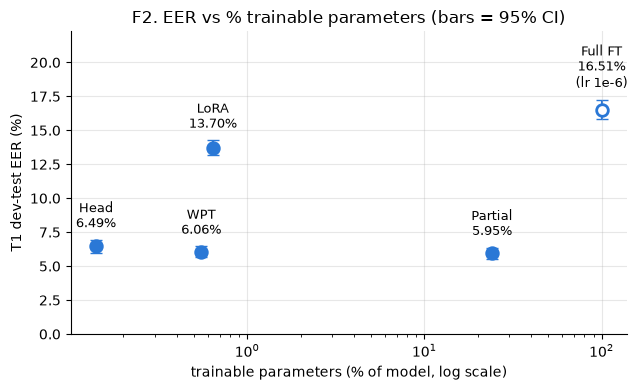

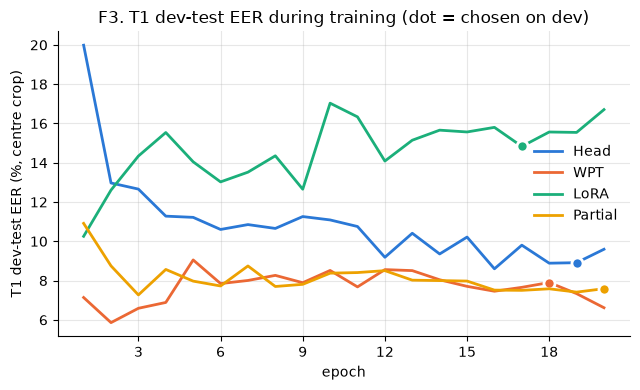

In [57]:
# C. Saved results
WHAT = {"Head": "AASIST + output layer", "WPT": "prompts + projection + head", "LoRA": "LoRA r=8 + head",
        "Partial": "last 6 encoder layers + head", "Full FT": "whole model"}
rows, rlogs = [], {}
for name, run in RATIO.items():
    m = metrics_of(run)
    if m is None: print("[not found]", run); continue
    cfg = json.load(open(os.path.join(RUNS, run, "config.json")))
    tp = m.get("trainable_parameters", cfg.get("trainable_parameters"))
    tot = m.get("total_parameters", cfg.get("total_parameters"))
    if name == "Full FT":
        tp = tot = 315_885_962
        d = json.load(open(os.path.join(RUNS, run, "devtest_metrics.json")))
        eer, auc = d["devtest_eer_whole_clip"], d["devtest_auc"]
    else:
        eer, auc = m[f"{DT}_eer_whole_clip"], m[f"{DT}_auc"]
        rlogs[name] = pd.read_csv(os.path.join(RUNS, run, "train_log.csv"))
    e = os.path.join(RUNS, run, "emissions_train.csv")
    e = pd.read_csv(e) if os.path.exists(e) else None
    rows.append(dict(method=name, trained=WHAT[name], trainable=tp, total=tot, trainable_pct=round(100 * tp / tot, 2),
                     lr=m.get("lr", cfg.get("lr")), best_epoch=m["best_epoch"], devtest_EER=round(eer, 2), devtest_AUC=round(auc, 2),
                     train_hours=round(e["duration"].sum() / 3600, 1) if e is not None else np.nan,
                     train_kg_CO2=round(e["emissions"].sum(), 3) if e is not None else np.nan))
T5 = pd.DataFrame(rows).sort_values("trainable_pct", ignore_index=True)
ci = CI_RATIO.set_index("system")
T5["devtest_EER_95CI"] = [f"[{ci.ci_low[m]:.2f}, {ci.ci_high[m]:.2f}]" if m in ci.index else "" for m in T5.method]
display(T5)

fig, ax = plt.subplots(figsize=(6.5, 4))
for _, r in T5.iterrows():
    other_lr = r.method == "Full FT"; hi = r.devtest_EER
    if r.method in ci.index:
        lo, hi = ci.ci_low[r.method], ci.ci_high[r.method]
        ax.errorbar(r.trainable_pct, r.devtest_EER, yerr=[[r.devtest_EER - lo], [hi - r.devtest_EER]],
                    fmt="none", ecolor=COLORS[0], elinewidth=1.5, capsize=4, zorder=1)
    ax.scatter(r.trainable_pct, r.devtest_EER, s=70, zorder=2, linewidth=2, color="white" if other_lr else COLORS[0], edgecolor=COLORS[0])
    ax.annotate(f"{r.method}\n{r.devtest_EER:.2f}%" + ("\n(lr 1e-6)" if other_lr else ""), (r.trainable_pct, hi),
                textcoords="offset points", xytext=(0, 6), ha="center", va="bottom", fontsize=9)
ax.set(xscale="log", xlabel="trainable parameters (% of model, log scale)", ylabel="T1 dev-test EER (%)",
       title="F2. EER vs % trainable parameters (bars = 95% CI)", ylim=(0, T5.devtest_EER.max() * 1.35))
fig.tight_layout(); fig.savefig(os.path.join(OUT_ROOT, "F2_eer_vs_trainable.png"), dpi=200, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(6.5, 4))
for c, (name, log) in zip(COLORS, rlogs.items()):
    ax.plot(log.epoch, log.devtest_eer, color=c, label=name)
    b = log[log.best.astype(bool)].epoch.max()
    ax.plot(b, log.loc[log.epoch == b, "devtest_eer"], "o", color=c, ms=8, mec="white", mew=2)
ax.set(xlabel="epoch", ylabel="T1 dev-test EER (%, centre crop)", title="F3. T1 dev-test EER during training (dot = chosen on dev)")
ax.xaxis.set_major_locator(MaxNLocator(integer=True)); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(os.path.join(OUT_ROOT, "F3_devtest_per_epoch.png"), dpi=200, bbox_inches="tight"); plt.show()

---
# D. Final test
144,210 clips, scored once. Each run uses its EER threshold from T1 dev-test.

In [58]:
%%step RUN_FINAL_TEST
# D1. Environment
import sys, os, json, time, math, platform, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "transformers==5.18.0",
                    "huggingface-hub==1.33.0", "codecarbon==3.3.2", "soundfile"], check=True)
    from google.colab import drive
    drive.mount("/content/drive")

import numpy as np, pandas as pd, torch, transformers, huggingface_hub
assert torch.cuda.is_available(), "No GPU: Runtime > Change runtime type > L4"
if transformers.__version__ != "5.18.0":
    print("WARNING: transformers", transformers.__version__, "is loaded. Restart the session (Runtime > Restart session) and run cell 1 again.")
GPU_NAME = torch.cuda.get_device_name(0)
GPU_GB = torch.cuda.get_device_properties(0).total_memory / 2**30

print("Python", platform.python_version(), "| torch", torch.__version__, "| transformers", transformers.__version__,
      "| huggingface_hub", huggingface_hub.__version__)
print(f"GPU: {GPU_NAME} | {GPU_GB:.1f} GB | bf16: {torch.cuda.is_bf16_supported()} | CPU cores: {os.cpu_count()}")

skipped (RUN_FINAL_TEST = False)


In [59]:
%%step RUN_FINAL_TEST
# D2. Settings
QUICK_TEST = False
XLSR, WAVLM = "facebook/wav2vec2-xls-r-300m", "microsoft/wavlm-large"
RUNS = {"WPT": ("wpt", "xlsr300m__wpt__ftrecipe__lr0.0001__seed42", XLSR),
        "Head": ("head", "xlsr300m__head__ftrecipe__lr0.0001__seed42", XLSR),
        "LoRA": ("lora", "xlsr300m__lora_r8__ftrecipe__lr0.0001__seed42", XLSR),
        "Partial": ("partial", "xlsr300m__partial6__ftrecipe__lr0.0001_enc1e-05__seed42", XLSR),
        "WavLM WPT": ("wpt", "wavlm_large__wpt__ftrecipe__lr0.0001__seed42", WAVLM)}
N_UNFROZEN = 6
REPO_ID = "ArabicSpeech/ArA-DF-2026"
REVISION = "2b1f042dc166b1d372841cb0d7110661ea5b2a93"
DEVTEST, TEST = "track-1_development_test", "track-1_test"
N_CHECK = 256

if IN_COLAB:
    PROJECT_ROOT = "/content/drive/MyDrive/nabra"
    AUDIO_ROOT = "/content/aradf_audio"
    RUNS_ROOT = os.path.join(PROJECT_ROOT, "runs")
else:
    PROJECT_ROOT = r"C:\Users\Aisha\OneDrive\سطح المكتب\vss\Grad"
    AUDIO_ROOT = r"C:\Users\Aisha\nabra_data\aradf_audio"
    RUNS_ROOT = r"C:\Users\Aisha\nabra_runs"
ART_DIR = os.path.join(PROJECT_ROOT, "artifacts", "aradf_eda")
SUFFIX = "_quicktest" if QUICK_TEST else ""

CFG = dict(seed=42, sample_rate=16000, max_len=64600, trim_silence=True, rms_dbfs=-23.0, spec_augment=False,
           n_prompts=6, n_wavelet_prompts=4, prompt_dropout=0.1, gradient_checkpointing=False,
           lora=dict(r=8, alpha=32, dropout=0.1, targets=["q_proj", "k_proj", "v_proj", "out_proj"]),
           aasist=dict(filts=[70, [1, 32], [32, 32], [32, 64], [64, 64]], gat_dims=[64, 32],
                       pool_ratios=[0.5, 0.7, 0.5, 0.5], temperatures=[2.0, 2.0, 100.0, 100.0]))

import random
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.benchmark = False
for name, (kind, run, hf) in RUNS.items():
    d = os.path.join(RUNS_ROOT, run)
    for f in ["best.pt", "metrics.json", f"{DEVTEST}_scores.csv"]:
        assert os.path.exists(os.path.join(d, f)), f"{name}: {f} missing in {d}"
    m = json.load(open(os.path.join(d, "metrics.json")))
    print(f"{name:9s} {run} | T1 dev-test EER {m[DEVTEST + '_eer_whole_clip']:.2f}% | threshold {m['threshold_from_devtest']:.3f}")

skipped (RUN_FINAL_TEST = False)


In [60]:
%%step RUN_FINAL_TEST
# D3. Data
import tarfile
from huggingface_hub import HfApi, hf_hub_download
HF_TOKEN = os.environ.get("HF_TOKEN")

assert os.path.isdir(os.path.join(ART_DIR, "manifests")), f"No manifests in {ART_DIR}."
with open(os.path.join(ART_DIR, "preprocessing_config.json"), encoding="utf-8") as f:
    PREP = json.load(f)
assert PREP["revision"] == REVISION, "Manifests were made from a different dataset version"
assert os.path.exists(os.path.join(ART_DIR, "manifests", f"{DEVTEST}.csv")), \
    f"Copy {DEVTEST}.csv into {os.path.join(ART_DIR, 'manifests')}"

def load_manifest(split):
    m = pd.read_csv(os.path.join(ART_DIR, "manifests", f"{split}.csv"), low_memory=False)
    return m[m["keep"].astype(bool)].reset_index(drop=True)

MAN = {s: load_manifest(s) for s in [DEVTEST, TEST]}
for s, m in MAN.items():
    print(f"{s:25s} {len(m):7,d} clips | bona fide {int(m.label.sum()):6,d} | spoof {int((m.label == 0).sum()):7,d}")
assert [len(MAN[s]) for s in MAN] == [16023, 144210]
overlap = set(MAN[DEVTEST]["id"]) & set(MAN[TEST]["id"])
assert not overlap, f"{len(overlap)} clip ids are in both T1 dev-test and the final test"
sha = {s: set(load_manifest(s)["sha256"]) for s in ["train", "dev", DEVTEST, TEST]}
for a, b in [("train", TEST), ("dev", TEST), (DEVTEST, TEST), ("train", DEVTEST), ("dev", DEVTEST)]:
    print(f"identical audio files in {a} and {b}: {len(sha[a] & sha[b])}")
if QUICK_TEST:
    MAN[TEST] = MAN[TEST].sample(64, random_state=CFG["seed"]).reset_index(drop=True)

def extract_split(split, ids):
    os.makedirs(os.path.join(AUDIO_ROOT, split), exist_ok=True)
    want = {i for i in ids if not os.path.exists(os.path.join(AUDIO_ROOT, split, f"{i}.flac"))}
    if not want:
        print(f"{split}: all {len(ids):,} clips already on disk"); return
    files = HfApi().list_repo_files(REPO_ID, repo_type="dataset", revision=REVISION, token=HF_TOKEN)
    tars = sorted(f for f in files if f.startswith(f"data/{split}/") and f.endswith(".tar"))
    t0 = time.time()
    for t in tars:
        local = hf_hub_download(REPO_ID, t, repo_type="dataset", revision=REVISION, token=HF_TOKEN)
        with tarfile.open(local) as tf:
            for mem in tf:
                if mem.isfile() and mem.name.endswith(".flac"):
                    cid = os.path.basename(mem.name)[:-5]
                    if cid in want:
                        with open(os.path.join(AUDIO_ROOT, split, f"{cid}.flac"), "wb") as f:
                            f.write(tf.extractfile(mem).read())
        print(f"  {t} | {time.time() - t0:.0f}s")
    missing = [i for i in ids if not os.path.exists(os.path.join(AUDIO_ROOT, split, f"{i}.flac"))]
    assert not missing, f"{split}: {len(missing)} clips missing after extraction"
    print(f"{split}: {len(ids):,} clips ready")

check_man = MAN[DEVTEST].sample(N_CHECK, random_state=CFG["seed"]).reset_index(drop=True)
extract_split(DEVTEST, check_man["id"].tolist())
extract_split(TEST, MAN[TEST]["id"].tolist())

skipped (RUN_FINAL_TEST = False)


In [61]:
%%step RUN_FINAL_TEST or RUN_XAI --name eval_prep
# D4. Preprocessing
import soundfile as sf
SR, N = CFG["sample_rate"], CFG["max_len"]

def load_wave(path):
    x, sr = sf.read(path, dtype="float32", always_2d=False)
    if x.ndim > 1: x = x.mean(1)
    assert sr == SR, f"{path}: sr={sr}"
    return x

def trim_silence(x, top_db=40.0, frame=400, hop=160):
    if len(x) < frame: return x
    nf = 1 + (len(x) - frame) // hop
    idx = np.arange(frame)[None, :] + hop * np.arange(nf)[:, None]
    e = 10 * np.log10((x[idx] ** 2).mean(1) + 1e-10)
    v = np.flatnonzero(e > e.max() - top_db)
    return x[v[0] * hop: v[-1] * hop + frame] if len(v) else x

def rms_normalize(x, target_dbfs=-23.0):
    rms = np.sqrt(np.mean(x ** 2) + 1e-12)
    return np.clip(x * (10 ** (target_dbfs / 20) / rms), -1, 1).astype(np.float32)

def clean_wave(x):
    if CFG["trim_silence"]: x = trim_silence(x)
    return rms_normalize(x, CFG["rms_dbfs"])

def crop_or_pad(x, n, mode, rng=None):
    if len(x) == 0: return np.zeros(n, np.float32)
    if len(x) < n: x = np.tile(x, int(np.ceil(n / len(x))))
    if len(x) == n: return x
    if mode == "random": start = rng.randint(0, len(x) - n + 1)
    elif mode == "center": start = (len(x) - n) // 2
    else: start = 0
    return x[start:start + n]

def make_windows(x, n):
    if len(x) <= n: return crop_or_pad(x, n, "start")[None, :]
    starts = list(range(0, len(x) - n + 1, n))
    if starts[-1] + n < len(x): starts.append(len(x) - n)
    return np.stack([x[s:s + n] for s in starts])

class AraDF(torch.utils.data.Dataset):
    def __init__(self, manifest, mode):
        self.ids = manifest["id"].tolist(); self.labels = manifest["label"].astype(int).tolist()
        self.paths = manifest["path"].tolist(); self.mode = mode
        self.rng = np.random.RandomState(CFG["seed"])
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        x = clean_wave(load_wave(os.path.join(AUDIO_ROOT, self.paths[i])))
        w = make_windows(x, N) if self.mode == "windows" else crop_or_pad(x, N, self.mode, self.rng)[None, :]
        return torch.from_numpy(np.ascontiguousarray(w, dtype=np.float32)), self.labels[i], self.ids[i]

def seed_worker(worker_id):
    info = torch.utils.data.get_worker_info()
    info.dataset.rng = np.random.RandomState(torch.initial_seed() % 2**32)

def collate(batch):
    waves = torch.cat([b[0] for b in batch])
    return waves, torch.tensor([b[1] for b in batch]), [b[2] for b in batch], [b[0].shape[0] for b in batch]

NUM_WORKERS = min(8, os.cpu_count() or 1) if IN_COLAB else 0
def make_loader(ds, batch_size, shuffle, epoch=0):
    g = torch.Generator(); g.manual_seed(CFG["seed"] + epoch)
    if NUM_WORKERS == 0: ds.rng = np.random.RandomState(CFG["seed"] + epoch)
    return torch.utils.data.DataLoader(ds, batch_size=batch_size, shuffle=shuffle, drop_last=shuffle,
                                       num_workers=NUM_WORKERS, worker_init_fn=seed_worker if NUM_WORKERS else None,
                                       generator=g, collate_fn=collate, pin_memory=True)

skipped (RUN_FINAL_TEST or RUN_XAI = False)


In [62]:
%%step RUN_FINAL_TEST
# D5. AASIST back end
rerun("aasist")

skipped (RUN_FINAL_TEST = False)


In [63]:
%%step RUN_FINAL_TEST or RUN_XAI --name models
# D6. Models
from transformers import AutoConfig, AutoModel, AutoFeatureExtractor
from torch.utils.checkpoint import checkpoint

def haar_dwt(q):
    even, odd = q[..., 0::2], q[..., 1::2]
    return (even + odd) / math.sqrt(2), (even - odd) / math.sqrt(2)

class WPTEncoder(nn.Module):
    def __init__(self, hf_name):
        super().__init__()
        conf = AutoConfig.from_pretrained(hf_name)
        conf.apply_spec_augment = CFG["spec_augment"]
        self.ssl = AutoModel.from_pretrained(hf_name, config=conf)
        self.ssl.requires_grad_(False)
        self.is_wavlm = conf.model_type == "wavlm"
        self.pre_ln = bool(conf.do_stable_layer_norm)
        L, d = conf.num_hidden_layers, conf.hidden_size
        assert d % 2 == 0
        self.n_p, self.n_w = CFG["n_prompts"], CFG["n_wavelet_prompts"]
        bound = math.sqrt(6.0 / (2 * d))
        self.P = nn.Parameter(torch.empty(L, self.n_p, d).uniform_(-bound, bound))
        self.Q = nn.Parameter(torch.empty(L, self.n_w, d).uniform_(-bound, bound))
        self.proj = nn.Linear(d, d)
        self.drop = nn.Dropout(CFG["prompt_dropout"])

    def train(self, mode=True):
        super().train(mode)
        self.ssl.eval()
        return self

    def forward(self, wav, use_prompts=True):
        B, enc = wav.shape[0], self.ssl.encoder
        with torch.no_grad():
            f = self.ssl.feature_extractor(wav).transpose(1, 2)
            h, _ = self.ssl.feature_projection(f)
            h = h + enc.pos_conv_embed(h)
            if not self.pre_ln:
                h = enc.layer_norm(h)
            h = enc.dropout(h)
        n = self.n_w + self.n_p if use_prompts else 0
        bias = None
        for i, layer in enumerate(enc.layers):
            if use_prompts:
                A, D = haar_dwt(self.Q[i])
                wp = self.drop(self.proj(torch.cat([A, D], -1)).expand(B, -1, -1))
                p = self.drop(self.P[i].expand(B, -1, -1))
                x = torch.cat([wp.to(h.dtype), p.to(h.dtype), h], 1)
            else:
                x = h
            if self.is_wavlm:
                run = lambda x, bias, layer=layer, i=i: layer(x, position_bias=bias, index=i)
            else:
                run = lambda x, bias, layer=layer: (layer(x), None)
            if CFG["gradient_checkpointing"] and self.training:
                x, bias = checkpoint(run, x, bias, use_reentrant=False)
            else:
                x, bias = run(x, bias)
            h = x[:, n:]
        if self.pre_ln:
            h = enc.layer_norm(h)
        return h

class WPTDetector(nn.Module):
    def __init__(self, hf_name):
        super().__init__()
        self.enc = WPTEncoder(hf_name)
        self.do_normalize = bool(getattr(AutoFeatureExtractor.from_pretrained(hf_name), "do_normalize", False))
        self.backend = AASIST(input_dim=self.enc.ssl.config.hidden_size, **CFG["aasist"])
        self.fc = nn.Linear(5 * CFG["aasist"]["gat_dims"][1], 2)

    def forward(self, wav):
        if self.do_normalize:
            with torch.autocast("cuda", enabled=False):
                wav = wav.float()
                wav = (wav - wav.mean(1, keepdim=True)) / torch.sqrt(wav.var(1, keepdim=True, unbiased=False) + 1e-7)
        return self.fc(self.backend(self.enc(wav)))

class LoRALinear(nn.Module):
    def __init__(self, base, r, alpha, dropout):
        super().__init__()
        self.base = base
        self.lora_A = nn.Linear(base.in_features, r, bias=False)
        self.lora_B = nn.Linear(r, base.out_features, bias=False)
        nn.init.kaiming_uniform_(self.lora_A.weight, a=math.sqrt(5)); nn.init.zeros_(self.lora_B.weight)
        self.drop, self.scale = nn.Dropout(dropout), alpha / r

    def forward(self, x):
        return self.base(x) + self.lora_B(self.lora_A(self.drop(x))) * self.scale

class RatioDetector(nn.Module):
    def __init__(self, hf_name):
        super().__init__()
        conf = AutoConfig.from_pretrained(hf_name)
        conf.apply_spec_augment = CFG["spec_augment"]
        self.ssl = AutoModel.from_pretrained(hf_name, config=conf)
        self.ssl.requires_grad_(False)
        self.train_layers = []
        if STRATEGY == "lora":
            lc = CFG["lora"]
            for layer in self.ssl.encoder.layers:
                for name in lc["targets"]:
                    setattr(layer.attention, name, LoRALinear(getattr(layer.attention, name), lc["r"], lc["alpha"], lc["dropout"]))
        elif STRATEGY == "partial":
            self.train_layers = list(self.ssl.encoder.layers[-N_UNFROZEN:])
            for layer in self.train_layers:
                layer.requires_grad_(True)
            self.ssl.encoder.layer_norm.requires_grad_(True)
        self.do_normalize = bool(getattr(AutoFeatureExtractor.from_pretrained(hf_name), "do_normalize", False))
        self.backend = AASIST(input_dim=conf.hidden_size, **CFG["aasist"])
        self.fc = nn.Linear(5 * CFG["aasist"]["gat_dims"][1], 2)

    def train(self, mode=True):
        super().train(mode)
        self.ssl.eval()
        for layer in self.train_layers:
            layer.train(mode)
        if STRATEGY == "lora":
            for m in self.ssl.modules():
                if isinstance(m, LoRALinear):
                    m.drop.train(mode)
        return self

    def forward(self, wav):
        if self.do_normalize:
            with torch.autocast("cuda", enabled=False):
                wav = wav.float()
                wav = (wav - wav.mean(1, keepdim=True)) / torch.sqrt(wav.var(1, keepdim=True, unbiased=False) + 1e-7)
        return self.fc(self.backend(self.ssl(wav).last_hidden_state))

def score_of(logits):
    return (logits[:, 1] - logits[:, 0]).float()

def build(kind, hf_name):
    global STRATEGY
    set_seed(CFG["seed"])
    if kind == "wpt":
        return WPTDetector(hf_name).cuda().eval()
    STRATEGY = kind
    return RatioDetector(hf_name).cuda().eval()

skipped (RUN_FINAL_TEST or RUN_XAI = False)


In [64]:
%%step RUN_FINAL_TEST
# D7. Final test
from sklearn.metrics import roc_curve, roc_auc_score
from codecarbon import OfflineEmissionsTracker
AMP = dict(device_type="cuda", dtype=torch.bfloat16)

@torch.no_grad()
def predict(model, ds, clips_per_batch, chunk=64):
    model.eval(); ids, labels, scores = [], [], []
    for waves, y, cid, counts in make_loader(ds, clips_per_batch, shuffle=False):
        out = []
        for part in waves.split(chunk):
            with torch.autocast(**AMP):
                out.append(score_of(model(part.cuda(non_blocking=True))).cpu())
        s = torch.cat(out)
        scores += [float(v.mean()) for v in s.split(counts)]; ids += cid; labels += y.tolist()
    return ids, labels, scores

def eer_pct(y, s):
    fpr, tpr, _ = roc_curve(y, s, drop_intermediate=False)
    i = np.nanargmin(np.abs(1 - tpr - fpr))
    return float(100 * (fpr[i] + 1 - tpr[i]) / 2)

ref_test = MAN[TEST][["id", "label"]].astype({"label": int})
for name, (kind, run, hf) in RUNS.items():
    d = os.path.join(RUNS_ROOT, run)
    out_scores = os.path.join(d, f"{TEST}_scores{SUFFIX}.csv")
    out_metrics = os.path.join(d, f"final_test_metrics{SUFFIX}.json")
    if os.path.exists(out_metrics):
        print(f"{name}: already done ({out_metrics})"); continue
    m = json.load(open(os.path.join(d, "metrics.json")))
    thr = m["threshold_from_devtest"]
    model = build(kind, hf)
    ck = torch.load(os.path.join(d, "best.pt"), map_location="cuda", weights_only=False)
    model.load_state_dict(ck["model"]); model.eval()
    n_all = sum(p.numel() for p in model.parameters())
    print(f"\n{name} ({hf}): best epoch {ck['epoch']} (chosen on dev) | {n_all / 1e6:.1f}M parameters | threshold {thr:.3f}")
    del ck

    ids, _, s = predict(model, AraDF(check_man, "windows"), 16)
    saved = pd.read_csv(os.path.join(d, f"{DEVTEST}_scores.csv")).set_index("id").loc[ids, "score"].to_numpy()
    s = np.asarray(s); corr = float(np.corrcoef(s, saved)[0, 1]); same = float(((s >= thr) == (saved >= thr)).mean())
    print(f"  check on {N_CHECK} T1 dev-test clips: correlation with saved scores {corr:.4f} | "
          f"max |difference| {np.abs(s - saved).max():.3f} | same decision {100 * same:.1f}%")
    assert corr > 0.99, f"{name}: checkpoint does not reproduce the saved T1 dev-test scores"

    tracker = OfflineEmissionsTracker(country_iso_code="SAU", output_dir=d, output_file=f"emissions_final_test{SUFFIX}.csv",
                                      project_name=f"{run}__final_test", tracking_mode="machine", gpu_ids=[0],
                                      measure_power_secs=5, pue=1.0, log_level="error", allow_multiple_runs=True)
    tracker.start(); t0 = time.time()
    try:
        ids, labels, scores = predict(model, AraDF(MAN[TEST], "windows"), 16)
    finally:
        tracker.stop()
    sc = pd.DataFrame({"id": ids, "score": scores})
    sc.to_csv(out_scores, index=False)
    mm = ref_test.merge(sc, on="id", how="left", validate="one_to_one")
    assert mm["score"].notna().all() and len(mm) == len(MAN[TEST])
    y, s = mm["label"].to_numpy(), mm["score"].to_numpy(); pred = (s >= thr).astype(int)
    res = dict(method=name, run=run, best_epoch=m["best_epoch"], clips=len(y),
               threshold_from_devtest=thr, devtest_eer_whole_clip=m[f"{DEVTEST}_eer_whole_clip"],
               test_eer_whole_clip=eer_pct(y, s), test_auc=100 * roc_auc_score(y, s),
               test_accuracy_at_devtest_threshold=100 * float((pred == y).mean()),
               test_frr_at_devtest_threshold=100 * float((pred[y == 1] == 0).mean()),
               test_far_at_devtest_threshold=100 * float((pred[y == 0] == 1).mean()),
               check_corr_devtest=corr, minutes=(time.time() - t0) / 60, quick_test=QUICK_TEST)
    json.dump(res, open(out_metrics, "w"), indent=2)
    print(f"  final test: EER {res['test_eer_whole_clip']:.2f}% | AUC {res['test_auc']:.2f} | "
          f"accuracy {res['test_accuracy_at_devtest_threshold']:.2f}% | FRR {res['test_frr_at_devtest_threshold']:.2f}% | "
          f"FAR {res['test_far_at_devtest_threshold']:.2f}% | {res['minutes']:.0f} min")
    del model; torch.cuda.empty_cache()

skipped (RUN_FINAL_TEST = False)


In [65]:
%%step RUN_FINAL_TEST
# D8. Summary table
rows = []
for name, (kind, run, hf) in RUNS.items():
    f = os.path.join(RUNS_ROOT, run, f"final_test_metrics{SUFFIX}.json")
    if os.path.exists(f):
        rows.append(dict(json.load(open(f)), encoder=hf.split("/")[-1]))
summary = pd.DataFrame(rows)[["method", "encoder", "best_epoch", "devtest_eer_whole_clip", "test_eer_whole_clip", "test_auc",
                               "threshold_from_devtest", "test_accuracy_at_devtest_threshold",
                               "test_frr_at_devtest_threshold", "test_far_at_devtest_threshold"]]
print(summary.round(2).to_string(index=False))
print("Full FT (lr 1e-6): final-test EER XLS-R 16.73%, WavLM 20.27%")
summary.to_csv(os.path.join(RUNS_ROOT, f"final_test_summary{SUFFIX}.csv"), index=False)
print("saved:", os.path.join(RUNS_ROOT, f"final_test_summary{SUFFIX}.csv"))

skipped (RUN_FINAL_TEST = False)


In [66]:
# D. Saved results
FINAL = {"WPT (main)": "xlsr300m__wpt__ftrecipe__lr0.0001__seed42", "Head": "xlsr300m__head__ftrecipe__lr0.0001__seed42",
         "LoRA": "xlsr300m__lora_r8__ftrecipe__lr0.0001__seed42",
         "Partial": "xlsr300m__partial6__ftrecipe__lr0.0001_enc1e-05__seed42",
         "WavLM WPT": "wavlm_large__wpt__ftrecipe__lr0.0001__seed42"}
ref_test = manifest(TEST)[["id", "label"]].astype({"label": int})
rows = []
for name, run in FINAL.items():
    d = os.path.join(RUNS, run); mj = os.path.join(d, "final_test_metrics.json"); sc = os.path.join(d, f"{TEST}_scores.csv")
    if not os.path.exists(mj):
        print(f"[not found] {name}: final_test_metrics.json"); continue
    saved = json.load(open(mj)); thr = saved["threshold_from_devtest"]
    r = dict(method=name, devtest_EER=saved["devtest_eer_whole_clip"], threshold=thr, test_EER_saved=saved["test_eer_whole_clip"])
    if os.path.exists(sc):
        mm = ref_test.merge(pd.read_csv(sc), on="id", how="left", validate="one_to_one")
        assert mm["score"].notna().all() and len(mm) == 144210
        y, s = mm["label"].to_numpy(), mm["score"].to_numpy(); pred = (s >= thr).astype(int)
        r.update(test_EER=eer_pct(y, s), test_AUC=100 * roc_auc_score(y, s), accuracy=100 * (pred == y).mean(),
                 FRR=100 * (pred[y == 1] == 0).mean(), FAR=100 * (pred[y == 0] == 1).mean())
        assert abs(r["test_EER"] - r["test_EER_saved"]) < 1e-6, f"{name}: EER does not match the saved result"
    else:
        r.update(test_EER=np.nan, test_AUC=saved["test_auc"], accuracy=saved["test_accuracy_at_devtest_threshold"],
                 FRR=saved["test_frr_at_devtest_threshold"], FAR=saved["test_far_at_devtest_threshold"])
        print(f"{name}: scores file not here, values from final_test_metrics.json")
    rows.append(r)
FT = pd.DataFrame(rows); display(FT.round(2))
print("Full FT (lr 1e-6): final-test EER XLS-R",
      f"{metrics_of('xlsr300m__fullft')['track-1_test_eer_whole_clip']:.2f}%" if metrics_of("xlsr300m__fullft") else "n/a")
FT.to_csv(os.path.join(OUT_ROOT, "final_test_summary.csv"), index=False)

[not found] WavLM WPT: final_test_metrics.json


,method,devtest_EER,threshold,test_EER_saved,test_EER,test_AUC,accuracy,FRR,FAR
0,WPT (main),6.06,10.46,5.93,5.93,98.59,94.15,6.08,5.77
1,Head,6.49,4.98,6.59,6.59,98.24,93.49,6.72,6.44
2,LoRA,13.70,7.71,13.68,13.68,94.02,86.36,13.77,13.59
3,Partial,5.95,10.92,5.92,5.92,98.50,94.13,6.05,5.81


Full FT (lr 1e-6): final-test EER XLS-R 16.73%


---
# E. Error analysis
From the saved scores. The test set has no dialect or gender labels, so it is analysed by duration. Dialect and gender are checked on dev.

In [67]:
# E1. Load scores and check the EER
import os, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
from IPython.display import display

RUN = MAIN
RUN_DIR = os.path.join(RUNS, RUN)
MAN = os.path.join(ART, "manifests")
OUT = os.path.join(OUT_ROOT, "error_analysis"); os.makedirs(OUT, exist_ok=True)
SEED = 42

THR = json.load(open(os.path.join(RUN_DIR, "metrics.json")))["threshold_from_devtest"]

def eer_pct(y, s):
    fpr, tpr, _ = roc_curve(y, s, drop_intermediate=False)
    i = np.nanargmin(np.abs(1 - tpr - fpr))
    return float(100 * (fpr[i] + 1 - tpr[i]) / 2)

def joined(split, scores_file):
    m = pd.read_csv(os.path.join(MAN, f"{split}.csv"), low_memory=False)
    m = m[m["keep"].astype(bool)]
    s = pd.read_csv(os.path.join(RUN_DIR, scores_file))
    d = m.merge(s, on="id", how="inner", validate="one_to_one")
    assert len(d) == len(m) == len(s), f"{split}: {len(m)} clips in the manifest, {len(s)} scores, {len(d)} matched"
    d["label"] = d["label"].astype(int)
    d["accepted"] = d["score"] >= THR
    return d

test = joined("track-1_test", "track-1_test_scores.csv")
print(f"final test: {len(test):,} clips | bona fide {test.label.sum():,} | spoof {(test.label == 0).sum():,} | threshold {THR:.2f}")
print("dialect values:", test.dialect.unique(), "| gender values:", test.gender.unique())
print(f"EER {eer_pct(test.label, test.score):.2f}% (saved result: 5.93%) | AUC {100 * roc_auc_score(test.label, test.score):.2f}%")

final test: 144,210 clips | bona fide 36,903 | spoof 107,307 | threshold 10.46
dialect values: <ArrowStringArray>
['unknown']
Length: 1, dtype: str | gender values: <ArrowStringArray>
['unknown']
Length: 1, dtype: str
EER 5.93% (saved result: 5.93%) | AUC 98.59%


### Errors by duration

In [68]:
# E2. Errors by duration
EDGES = [0, 64600 / 16000, 6, 8, 10, 12, 17.5, np.inf]
NAMES = ["<= 4.04 s", "4.04-6 s", "6-8 s", "8-10 s", "10-12 s", "12-17.5 s", "> 17.5 s"]
test["duration_bin"] = pd.cut(test.duration_sec, EDGES, labels=NAMES)
rng = np.random.default_rng(SEED)

def ci(values):
    v = np.asarray(values, float); v = v[~np.isnan(v)]
    return (np.percentile(v, 2.5), np.percentile(v, 97.5)) if len(v) else (np.nan, np.nan)

rows = []
for name, g in test.groupby("duration_bin", observed=True):
    bona, spoof = g[g.label == 1], g[g.label == 0]
    has_both = len(bona) > 0 and len(spoof) > 0
    frr = 100 * (~bona.accepted).mean() if len(bona) else np.nan
    far = 100 * spoof.accepted.mean()
    b_eer, b_frr, b_far = [], [], []
    for _ in range(N_BOOT):
        bi = bona.iloc[rng.integers(0, len(bona), len(bona))] if len(bona) else bona
        si = spoof.iloc[rng.integers(0, len(spoof), len(spoof))]
        if has_both:
            b = pd.concat([bi, si]); b_eer.append(eer_pct(b.label, b.score)); b_frr.append(100 * (~bi.accepted).mean())
        b_far.append(100 * si.accepted.mean())
    rows.append(dict(duration=name, clips=len(g), bona_fide=len(bona), spoof=len(spoof),
                     EER=round(eer_pct(g.label, g.score), 2) if has_both else np.nan, EER_95CI=ci(b_eer),
                     FRR=round(frr, 2), FRR_95CI=ci(b_frr), FAR=round(far, 2), FAR_95CI=ci(b_far)))
by_dur = pd.DataFrame(rows)
for c in ["EER_95CI", "FRR_95CI", "FAR_95CI"]:
    by_dur[c] = [f"[{a:.2f}, {b:.2f}]" if not np.isnan(a) else "" for a, b in by_dur[c]]
by_dur.to_csv(os.path.join(OUT, "test_by_duration.csv"), index=False)
display(by_dur)
print("No bona fide clip is longer than 17.5 s, so that bin has no EER or FRR; only FAR.")

,duration,clips,bona_fide,spoof,EER,EER_95CI,FRR,FRR_95CI,FAR,FAR_95CI
0,<= 4.04 s,11488,2084,9404,11.67,"[10.92, 12.41]",22.46,"[20.68, 24.28]",5.51,"[5.07, 5.94]"
1,4.04-6 s,20156,4765,15391,6.68,"[6.25, 7.16]",6.55,"[5.81, 7.24]",7.00,"[6.60, 7.40]"
2,6-8 s,26515,6421,20094,5.66,"[5.33, 6.00]",5.28,"[4.72, 5.81]",6.03,"[5.69, 6.36]"
3,8-10 s,28162,7103,21059,5.25,"[4.93, 5.55]",5.22,"[4.74, 5.74]",5.32,"[5.00, 5.62]"
4,10-12 s,27080,6800,20280,4.97,"[4.67, 5.32]",4.87,"[4.37, 5.41]",5.16,"[4.87, 5.47]"
5,12-17.5 s,29702,9730,19972,5.06,"[4.80, 5.38]",4.33,"[3.92, 4.73]",6.06,"[5.72, 6.40]"
6,> 17.5 s,1107,0,1107,NaN,,NaN,,0.99,"[0.45, 1.63]"


No bona fide clip is longer than 17.5 s, so that bin has no EER or FRR; only FAR.


### Is duration a shortcut?
No bona fide test clip is longer than 17.5 s, while spoof clips reach 106 s. This checks whether length alone separates the classes.

In [69]:
# E3. Is duration a shortcut?
rows = []
for split, d in [("final test", test)]:
    for sign, how in [(1, "longer = bona fide"), (-1, "shorter = bona fide")]:
        rows.append(dict(split=split, score="duration only", direction=how,
                         EER=round(eer_pct(d.label, sign * d.duration_sec), 2)))
short = pd.DataFrame(rows); display(short)

for lab, name in [(1, "bona fide"), (0, "spoof")]:
    g = test[test.label == lab]
    r = np.corrcoef(g.score, g.duration_sec)[0, 1]
    rs = g[["score", "duration_sec"]].rank().corr().iloc[0, 1]
    print(f"{name}: correlation of model score with duration  Pearson {r:.3f} | Spearman {rs:.3f}")
g = test[test.duration_sec <= 17.5]
print(f"\nmodel EER on clips <= 17.5 s only (the range where both classes exist): {eer_pct(g.label, g.score):.2f}% "
      f"({len(g):,} clips) | all clips: {eer_pct(test.label, test.score):.2f}%")
short.to_csv(os.path.join(OUT, "duration_shortcut_check.csv"), index=False)

,split,score,direction,EER
0,final test,duration only,longer = bona fide,46.91
1,final test,duration only,shorter = bona fide,53.09


bona fide: correlation of model score with duration  Pearson 0.097 | Spearman 0.053
spoof: correlation of model score with duration  Pearson 0.033 | Spearman 0.048

model EER on clips <= 17.5 s only (the range where both classes exist): 5.95% (143,103 clips) | all clips: 5.93%


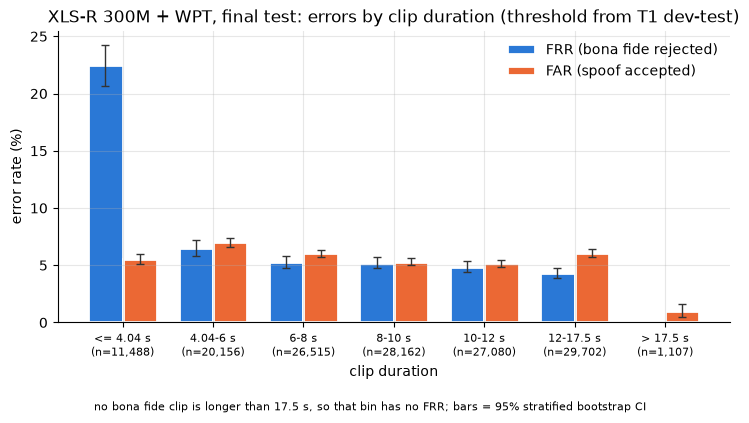

In [70]:
# E4. Figure
def parse(s):
    return [float(x) for x in s.strip("[]").split(",")] if s else [np.nan, np.nan]

plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "savefig.dpi": 200})
x = np.arange(len(by_dur)); w = 0.38
fig, ax = plt.subplots(figsize=(7.5, 4))
for off, col, ci_col, color, label in [(-w / 2, "FRR", "FRR_95CI", "#2a78d6", "FRR (bona fide rejected)"),
                                       (w / 2, "FAR", "FAR_95CI", "#eb6834", "FAR (spoof accepted)")]:
    v = by_dur[col].to_numpy(float)
    lo_hi = np.array([parse(s) for s in by_dur[ci_col]])
    err = np.vstack([v - lo_hi[:, 0], lo_hi[:, 1] - v])
    ax.bar(x + off, np.nan_to_num(v), w, color=color, label=label, edgecolor="white", linewidth=2)
    ax.errorbar(x + off, v, yerr=err, fmt="none", ecolor="#333333", elinewidth=1, capsize=3)
ax.set_xticks(x, [f"{d}\n(n={n:,})" for d, n in zip(by_dur.duration, by_dur.clips)], fontsize=8)
ax.set(ylabel="error rate (%)", xlabel="clip duration",
       title="XLS-R 300M + WPT, final test: errors by clip duration (threshold from T1 dev-test)")
ax.legend(frameon=False)
fig.text(0.5, -0.04, "no bona fide clip is longer than 17.5 s, so that bin has no FRR; bars = 95% stratified bootstrap CI",
         ha="center", fontsize=8)
fig.tight_layout(); fig.savefig(os.path.join(OUT, "F4_test_errors_by_duration.png"), bbox_inches="tight"); plt.show()

### Dev: dialect and gender
Dev is in-domain (EER about 0.06%), so this is only a side check.

In [71]:
# E5. Dev by dialect and gender
dev = joined("dev", "dev_scores.csv")
print(f"dev: {len(dev):,} clips | EER {eer_pct(dev.label, dev.score):.3f}%")
rows = []
for col in ["dialect", "gender"]:
    for name, g in dev.groupby(col):
        bona, spoof = g[g.label == 1], g[g.label == 0]
        both = len(bona) > 0 and len(spoof) > 0
        rows.append(dict(by=col, group=name, clips=len(g), bona_fide=len(bona), spoof=len(spoof),
                         EER=round(eer_pct(g.label, g.score), 3) if both else np.nan,
                         spoof_errors_at_EER=int(round(eer_pct(g.label, g.score) / 100 * len(spoof))) if both else np.nan,
                         FRR=round(100 * (~bona.accepted).mean(), 2) if len(bona) else np.nan,
                         FAR=round(100 * spoof.accepted.mean(), 2) if len(spoof) else np.nan))
dev_groups = pd.DataFrame(rows)
dev_groups.to_csv(os.path.join(OUT, "dev_by_dialect_gender.csv"), index=False)
display(dev_groups)
print("\nsaved in", OUT, ":", sorted(os.listdir(OUT)))

dev: 20,998 clips | EER 0.057%


,by,group,clips,bona_fide,spoof,EER,spoof_errors_at_EER,FRR,FAR
0,dialect,EGY,4529,1452,3077,0.000,0,17.63,0.0
1,dialect,Gulf,15012,5015,9997,0.080,8,25.26,0.0
2,dialect,MSA,1457,485,972,0.000,0,16.08,0.0
3,gender,Female,2460,804,1656,0.000,0,31.34,0.0
4,gender,Male,18194,6025,12169,0.050,6,21.79,0.0
5,gender,Unknown,344,123,221,0.633,1,29.27,0.0



saved in C:/Users/Aisha/OneDrive/سطح المكتب/vss/Grad\full_pipeline_outputs\error_analysis : ['F4_test_errors_by_duration.png', 'dev_by_dialect_gender.csv', 'duration_shortcut_check.csv', 'test_by_duration.csv']


---
# F. GATR
GATR (Grinberg et al., 2025) adapted to the WPT prompts, on 200 bona fide and 200 spoof clips from dev and from the final test (seed 42).

In [72]:
%%step RUN_XAI
# F1. Environment
import sys, os, json, time, math, platform, subprocess, types
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "transformers==5.18.0",
                    "huggingface-hub==1.33.0", "soundfile"], check=True)
    from google.colab import drive
    drive.mount("/content/drive")
else:
    os.environ.setdefault("HF_HUB_OFFLINE", "1")

import numpy as np, pandas as pd, torch, transformers
print("Python", platform.python_version(), "| torch", torch.__version__, "| transformers", transformers.__version__)
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)} | {torch.cuda.get_device_properties(0).total_memory / 2**30:.1f} GB")
else:
    print("no GPU: run only cells 1-3 now (audio download); cells 4 onwards need the L4")

skipped (RUN_XAI = False)


In [73]:
%%step RUN_XAI
# F2. Settings and protocol
QUICK = False
N_PER_CLASS = 10 if QUICK else 200
RUN = "xlsr300m__wpt__ftrecipe__lr0.0001__seed42"
HF_NAME = "facebook/wav2vec2-xls-r-300m"
REPO_ID, REVISION = "ArabicSpeech/ArA-DF-2026", "2b1f042dc166b1d372841cb0d7110661ea5b2a93"
DEVTEST, TEST = "track-1_development_test", "track-1_test"

if IN_COLAB:
    PROJECT_ROOT = "/content/drive/MyDrive/nabra"
    AUDIO_ROOT = os.path.join(PROJECT_ROOT, "xai_audio")
    RUN_DIR = os.path.join(PROJECT_ROOT, "runs", RUN)
else:
    PROJECT_ROOT = r"C:\Users\Aisha\OneDrive\سطح المكتب\vss\Grad"
    AUDIO_ROOT = r"C:\Users\Aisha\nabra_data\aradf_audio"
    RUN_DIR = os.path.join(r"C:\Users\Aisha\nabra_runs", RUN)
ART_DIR = os.path.join(PROJECT_ROOT, "artifacts", "aradf_eda")
XDIR = os.path.join(RUN_DIR, "xai_gatr_quick" if QUICK else "xai_gatr"); os.makedirs(XDIR, exist_ok=True)

CFG = dict(seed=42, sample_rate=16000, max_len=64600, trim_silence=True, rms_dbfs=-23.0, spec_augment=False,
           n_prompts=6, n_wavelet_prompts=4, prompt_dropout=0.1, gradient_checkpointing=False,
           lora=dict(r=8, alpha=32, dropout=0.1, targets=["q_proj", "k_proj", "v_proj", "out_proj"]),
           aasist=dict(filts=[70, [1, 32], [32, 32], [32, 64], [64, 64]], gat_dims=[64, 32],
                       pool_ratios=[0.5, 0.7, 0.5, 0.5], temperatures=[2.0, 2.0, 100.0, 100.0]))
run_cfg = json.load(open(os.path.join(RUN_DIR, "config.json")))
for k in ["seed", "sample_rate", "max_len", "trim_silence", "rms_dbfs", "n_prompts", "n_wavelet_prompts", "prompt_dropout", "aasist"]:
    assert run_cfg[k] == CFG[k], f"{k}: notebook {CFG[k]} vs run {run_cfg[k]}"
METRICS = json.load(open(os.path.join(RUN_DIR, "metrics.json")))
THR = METRICS["threshold_from_devtest"]

import random
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.benchmark = False

PROTOCOL = dict(
    method="GATR (Grinberg et al., ICASSP 2025, arXiv:2501.13887), Eq. 1-2, adapted to the WPT prompt tokens",
    adaptation=("prompt tokens are inserted before every layer and dropped after it, so they carry no audio relevance; "
                "the relevancy rollout is computed on the audio-frame block; row weights use the full row of mean_h grad(A_last); "
                "the identity is subtracted before averaging (as in the paper)"),
    model=f"XLS-R 300M + WPT + AASIST ({RUN}), best.pt (epoch chosen on dev)",
    resolution="one value per encoder frame (20 ms = 320 samples)",
    target="ground-truth class (as in the paper); examples: predicted class at the T1 dev-test threshold",
    threshold=f"{THR:.4f}, EER threshold on T1 dev-test (fixed before the final test)",
    samples=(f"dev {N_PER_CLASS} bona fide + {N_PER_CLASS} spoof (in-domain), track-1_test {N_PER_CLASS} + {N_PER_CLASS} "
             "(unseen conditions), drawn with seed 42"),
    window="centre window of 64,600 samples; examples: whole clip, same windows as the final evaluation",
    perturbation=("paper Sec. II-C b: replace the n% most (positive test) or least (negative test) relevant frames with Gaussian "
                  "noise (zero mean, variance of the input), n = 10..90%, area under the EER curve; baseline: random frame order; 2 noise seeds"),
    map_metrics=("paper Sec. II-C a: peak-normalized map multiplied with the waveform; confidence = softmax probability of the target "
                 "class; AD (Average Drop, lower is better), AI (Average Increase), AG (Average Gain), Fid-In (% of clips whose "
                 "decision at the threshold is unchanged); baseline: random maps (2 seeds)"),
    bootstrap="paired over clips, stratified by label, 2000 resamples, 95% percentile CI",
    decision_rule=("GATR is called more faithful than random only if the 95% CI of the AUC difference excludes 0 in GATR's "
                   "favour for both the positive and the negative test, on both dev and test; otherwise this is reported as not shown"),
    sanity=("cascading randomization (Adebayo et al., 2018) on 50 dev clips: head, + prompts, + top 12 layers, all; "
            "fails if the median Spearman with the original map stays >= 0.5 after all trained parameters are randomized"),
    limits=("window-edge test (first and last 0.1 s vs two random 0.1 s blocks); speech vs non-speech RCQ (paper Eq. 3-4) with an "
            "energy VAD instead of WebRTC VAD; silence was trimmed in preprocessing (top_db 40), so edges are speech onsets"),
    written="before running this notebook",
)
json.dump(PROTOCOL, open(os.path.join(XDIR, "protocol.json"), "w"), indent=2)
print(f"run: {RUN_DIR}\nresults: {XDIR}\nthreshold (T1 dev-test): {THR:.3f} | clips per class and split: {N_PER_CLASS}")

skipped (RUN_XAI = False)


In [74]:
%%step RUN_XAI
# F3. Data
import tarfile
def load_manifest(split):
    m = pd.read_csv(os.path.join(ART_DIR, "manifests", f"{split}.csv"), low_memory=False)
    return m[m["keep"].astype(bool)].reset_index(drop=True)
MAN = {s: load_manifest(s) for s in ["dev", DEVTEST, TEST]}

def extract_split(split, ids):
    os.makedirs(os.path.join(AUDIO_ROOT, split), exist_ok=True)
    want = {i for i in ids if not os.path.exists(os.path.join(AUDIO_ROOT, split, f"{i}.flac"))}
    if not want:
        print(f"{split}: all {len(ids):,} clips already on disk"); return
    from huggingface_hub import HfApi, hf_hub_download
    tok = os.environ.get("HF_TOKEN")
    files = HfApi().list_repo_files(REPO_ID, repo_type="dataset", revision=REVISION, token=tok)
    for t in sorted(f for f in files if f.startswith(f"data/{split}/") and f.endswith(".tar")):
        with tarfile.open(hf_hub_download(REPO_ID, t, repo_type="dataset", revision=REVISION, token=tok)) as tf:
            for mem in tf:
                cid = os.path.basename(mem.name)[:-5]
                if mem.isfile() and mem.name.endswith(".flac") and cid in want:
                    with open(os.path.join(AUDIO_ROOT, split, f"{cid}.flac"), "wb") as f: f.write(tf.extractfile(mem).read())
                    want.discard(cid)
        if not want: break
    assert not want, f"{split}: {len(want)} clips missing"
    print(f"{split}: {len(ids):,} clips ready")

def balanced(m):
    return pd.concat([m[m.label == 1].sample(N_PER_CLASS, random_state=CFG["seed"]),
                      m[m.label == 0].sample(N_PER_CLASS, random_state=CFG["seed"])]).reset_index(drop=True)
S = {"dev": balanced(MAN["dev"]), "test": balanced(MAN[TEST])}
check_man = MAN[DEVTEST].sample(32, random_state=CFG["seed"]).reset_index(drop=True)
extract_split("dev", S["dev"].id.tolist()); extract_split(TEST, S["test"].id.tolist()); extract_split(DEVTEST, check_man.id.tolist())

skipped (RUN_XAI = False)


In [75]:
%%step RUN_XAI
# F4. Preprocessing and models
rerun("eval_prep", "aasist", "models")

skipped (RUN_XAI = False)


In [76]:
%%step RUN_XAI
# F5. Load the checkpoint
assert torch.cuda.is_available(), "No GPU: Runtime > Change runtime type > L4, then run all cells"
AMP = dict(device_type="cuda", dtype=torch.bfloat16)
model = build("wpt", HF_NAME)
ck = torch.load(os.path.join(RUN_DIR, "best.pt"), map_location="cuda", weights_only=False)
model.load_state_dict(ck["model"]); model.eval()
print(f"best checkpoint: epoch {ck['epoch']} (chosen on dev) | saved T1 dev-test EER {METRICS[DEVTEST + '_eer_whole_clip']:.2f}%"); del ck

@torch.no_grad()
def whole_clip_score(x):
    W = torch.from_numpy(np.ascontiguousarray(make_windows(clean_wave(x), N)))
    with torch.autocast(**AMP):
        return float(score_of(model(W.cuda())).mean())
s = np.array([whole_clip_score(load_wave(os.path.join(AUDIO_ROOT, p))) for p in check_man.path])
saved = pd.read_csv(os.path.join(RUN_DIR, f"{DEVTEST}_scores.csv")).set_index("id").loc[check_man.id, "score"].to_numpy()
corr = np.corrcoef(s, saved)[0, 1]
print(f"check on {len(s)} T1 dev-test clips: correlation with saved scores {corr:.4f} | max |difference| {np.abs(s - saved).max():.3f} | "
      f"same decision {100 * ((s >= THR) == (saved >= THR)).mean():.1f}%")
assert corr > 0.99, "the checkpoint does not reproduce the saved scores"

skipped (RUN_XAI = False)


In [77]:
%%step RUN_XAI
# F6. GATR
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
torch.backends.cuda.matmul.allow_tf32 = False; torch.backends.cudnn.allow_tf32 = False
HOP = 320
LAYERS = model.enc.ssl.encoder.layers
ATTN_FWD = type(LAYERS[0].attention).forward
ATT = {"keep": False, "A": []}
def attn_keep(self, hidden_states, key_value_states=None, attention_mask=None, output_attentions=False, **kw):
    if not ATT["keep"]: return ATTN_FWD(self, hidden_states, key_value_states, attention_mask, output_attentions, **kw)
    assert key_value_states is None and attention_mask is None
    B, T, _ = hidden_states.shape; H, hd = self.num_heads, self.head_dim
    q, k, v = [p(hidden_states).view(B, T, H, hd).transpose(1, 2) for p in (self.q_proj, self.k_proj, self.v_proj)]
    A = torch.softmax((q @ k.transpose(-1, -2)) * self.scaling, dim=-1)
    A.retain_grad(); ATT["A"].append(A)
    return self.out_proj((A @ v).transpose(1, 2).reshape(B, T, H * hd)), A
for layer in LAYERS:
    layer.attention.forward = types.MethodType(attn_keep, layer.attention)

def gatr_from(As, n):
    T = As[0].shape[-1] - n; I = torch.eye(T, device=As[0].device); R = I.clone()
    for A in As:
        R = R + (A.grad * A).clamp(min=0).mean(1)[0, n:, n:] @ R
    W = As[-1].grad.mean(1)[0, n:].norm(dim=1)
    return ((W[:, None] * (R - I)).sum(0) / W.sum()).detach().float().cpu().numpy()

def gatr_window(x, target):
    model.zero_grad(set_to_none=True); ATT.update(keep=True, A=[])
    try:
        with torch.enable_grad():
            logits = model(torch.as_tensor(np.asarray(x, np.float32)).reshape(1, -1).cuda())
            logits[0, int(target)].backward()
        return gatr_from(ATT["A"], model.enc.n_w + model.enc.n_p), logits.detach().float().cpu().numpy()[0]
    finally:
        ATT.update(keep=False, A=[])

@torch.no_grad()
def window_scores(W):
    with torch.autocast(**AMP):
        return np.concatenate([score_of(model(torch.from_numpy(np.ascontiguousarray(b)).cuda())).float().cpu().numpy()
                               for b in np.array_split(W, int(np.ceil(len(W) / 16)))])

def explain_clip(x, target=None):
    x = clean_wave(np.asarray(x, np.float32))
    W = make_windows(x, N)
    starts = [0] if len(x) <= N else sorted(set(range(0, len(x) - N + 1, N)) | {len(x) - N})
    score = float(window_scores(W).mean())
    c = (1 if score >= THR else 0) if target is None else int(target)
    nf = int(np.ceil(len(x) / HOP)); acc, cnt = np.zeros(nf), np.zeros(nf)
    for st, w in zip(starts, W):
        r, _ = gatr_window(w, c); o = int(round(st / HOP)); k = min(len(r), nf - o)
        acc[o:o + k] += r[:k]; cnt[o:o + k] += 1
    rel = np.clip(acc / np.maximum(cnt, 1), 0, None)
    return dict(score=score, cls=c, pred="bona fide" if c == 1 else "spoof", frames=rel, flat=bool(rel.max() <= 0), wave=x)

def top_segments(rel, k=3, width=25):
    if rel.max() <= 0: return []
    s, out = np.convolve(rel, np.ones(width), "same"), []
    for _ in range(k):
        i = int(s.argmax())
        if not np.isfinite(s[i]) or s[i] <= 0: break
        a, b = max(0, i - width // 2), min(len(rel), i + width // 2 + 1)
        out.append((a * HOP / SR, b * HOP / SR)); s[max(0, a - width // 2): b + width // 2] = -np.inf
    return sorted(out)

def plot_explanation(e, title=""):
    x, rel = e["wave"], e["frames"]; fig, ax = plt.subplots(figsize=(12, 3))
    ax.plot(np.arange(len(x)) / SR, x, lw=.4, color="0.6")
    if not e["flat"]:
        ax2 = ax.twinx(); tc = (np.arange(len(rel)) + .5) * HOP / SR
        ax2.fill_between(tc, rel / rel.max(), color="tab:red", alpha=.35, step="mid"); ax2.set_ylim(0, 1.05); ax2.set_yticks([])
        for a, b in top_segments(rel): ax.axvspan(a, b, color="tab:orange", alpha=.2)
    ax.set_xlabel("time (s)")
    ax.set_title(f"{title} prediction: {e['pred']} (score {e['score']:.2f}, threshold {THR:.2f})"
                 + (" | no localized evidence" if e["flat"] else ""))
    plt.tight_layout(); return fig

x_chk = 0.05 * np.random.RandomState(0).randn(N).astype(np.float32)
with torch.no_grad(): lg_ref = model(torch.from_numpy(x_chk)[None].cuda()).float().cpu().numpy()[0]
r_chk, lg = gatr_window(x_chk, 1)
print(f"check (fp32): attention with kept maps vs original, max logit difference {np.abs(lg - lg_ref).max():.2e} | "
      f"map length {len(r_chk)} frames | {len(LAYERS)} layers")
assert np.abs(lg - lg_ref).max() < 1e-3

skipped (RUN_XAI = False)


In [78]:
%%step RUN_XAI
# F7. Maps
WIN, MAPS = {}, {}
for name, smp in S.items():
    split = "dev" if name == "dev" else TEST
    WIN[name] = np.stack([crop_or_pad(clean_wave(load_wave(os.path.join(AUDIO_ROOT, p))), N, "center") for p in smp.path])
    out = os.path.join(XDIR, f"maps_{name}.npz")
    if os.path.exists(out):
        z = np.load(out, allow_pickle=True); assert (z["ids"].astype(str) == smp.id.astype(str).values).all()
        MAPS[name] = z["gatr"]; smp["score"] = z["score"]; print(f"{name}: maps loaded from {out}"); continue
    t0, maps, scores = time.time(), [], []
    for i, x in enumerate(WIN[name]):
        r, lg = gatr_window(x, int(smp.label[i])); maps.append(r); scores.append(float(lg[1] - lg[0]))
        if i == 9: print(f"{name}: {(time.time() - t0) / 10:.2f} s per clip")
    MAPS[name] = np.stack(maps).astype(np.float32); smp["score"] = np.array(scores)
    np.savez_compressed(out, ids=smp.id.astype(str).values, label=smp.label.values, gatr=MAPS[name], score=smp["score"].values)
    acc = 100 * ((smp.score >= THR).astype(int) == smp.label).mean()
    print(f"{name}: {len(smp)} maps | {time.time() - t0:.0f} s | centre-window accuracy at the threshold {acc:.1f}% | saved {out}")
NF = MAPS["dev"].shape[1]

skipped (RUN_XAI = False)


In [79]:
%%step RUN_XAI
# F8. Perturbation test
EF, SEEDS, NBOOT = 5, range(2), 2000
FRS = np.round(np.arange(0.1, 0.91, 0.1), 2)
FRAME = np.minimum(np.arange(N) // HOP, NF - 1)
EDGE = np.r_[0:EF, NF - EF:NF]

@torch.no_grad()
def scores_of(batch, chunk=16):
    xb = torch.from_numpy(np.stack(batch))
    return torch.cat([score_of(model(b.cuda())).cpu() for b in xb.split(chunk)]).numpy()

def eer_pct(y, s):
    from sklearn.metrics import roc_curve
    fpr, tpr, _ = roc_curve(np.asarray(y), np.asarray(s), drop_intermediate=False)
    i = np.nanargmin(np.abs((1 - tpr) - fpr)); return 100 * (fpr[i] + 1 - tpr[i]) / 2

def run_perturbation(name):
    out, smp = os.path.join(XDIR, f"perturbation_{name}.csv"), S[name]
    done = set(pd.read_csv(out).id.astype(str)) if os.path.exists(out) else set()
    buf, t0, n_new = [], time.time(), 0
    for i in range(len(smp)):
        cid = str(smp.id[i])
        if cid in done: continue
        x, batch, meta = WIN[name][i], [], []
        for k in SEEDS:
            rs = np.random.RandomState(CFG["seed"] + (0 if name == "dev" else 1_000_000) + 1000 * k + i)
            noise = (rs.randn(N) * x.std()).astype(np.float32)
            orders = {"gatr": np.lexsort((rs.rand(NF), -MAPS[name][i])), "random": rs.permutation(NF)}
            for m, o in orders.items():
                for f in FRS:
                    kk = int(round(f * NF))
                    for test, fr in [("pos", o[:kk]), ("neg", o[NF - kk:])]:
                        batch.append(np.where(np.isin(FRAME, fr), noise, x)); meta.append((k, m, test, f))
            a = rs.randint(EF, NF - 3 * EF + 1); b = rs.randint(a + EF, NF - 2 * EF + 1)
            for m, fr in [("edges", EDGE), ("random_blocks", np.r_[a:a + EF, b:b + EF])]:
                batch.append(np.where(np.isin(FRAME, fr), noise, x)); meta.append((k, m, "edge", np.nan))
        sc = scores_of(batch)
        buf += [dict(id=cid, label=int(smp.label[i]), seed=k, method=m, test=t, frac=f, score=float(s))
                for (k, m, t, f), s in zip(meta, sc)]
        n_new += 1
        if n_new == 5:
            per = (time.time() - t0) / 5
            print(f"{name}: {per:.1f} s per clip | about {per * (len(smp) - len(done) - n_new) / 60:.0f} min left")
        if n_new % 25 == 0:
            pd.DataFrame(buf).to_csv(out, mode="a", header=not os.path.exists(out), index=False); buf = []
    if buf: pd.DataFrame(buf).to_csv(out, mode="a", header=not os.path.exists(out), index=False)
    print(f"{name}: perturbation scores ready ({(time.time() - t0) / 60:.1f} min this run)")

def eer_fast(M, y):
    o = np.argsort(M, axis=1, kind="stable"); ys = y[o]; r = np.arange(len(M))
    fnr = np.c_[np.zeros(len(M)), np.cumsum(ys, 1) / y.sum()]
    fpr = np.c_[np.ones(len(M)), 1 - np.cumsum(1 - ys, 1) / (1 - y).sum()]
    i = np.abs(fnr - fpr).argmin(1); return 100 * (fnr[r, i] + fpr[r, i]) / 2

RESULTS, CURVES = {}, {}
for name in ["dev", "test"]:
    run_perturbation(name)
    d = pd.read_csv(os.path.join(XDIR, f"perturbation_{name}.csv")); d["id"] = d.id.astype(str)
    ids, y = S[name].id.astype(str).values, S[name].label.values.astype(int)
    p = d[d.test != "edge"].assign(frac=lambda t: t.frac.round(2))
    piv = p.pivot_table(index=["seed", "method", "test", "frac"], columns="id", values="score", aggfunc="first").reindex(columns=ids)
    keys = [(k, m, t, f) for k in SEEDS for m in ["gatr", "random"] for t in ["pos", "neg"] for f in FRS]
    M = piv.loc[keys].values; assert not np.isnan(M).any(), "missing perturbation scores"
    shape = (len(SEEDS), 2, 2, len(FRS))
    E = eer_fast(M, y).reshape(shape); CURVES[name] = E.mean(0)
    chk = max(abs(E.reshape(-1)[j] - eer_pct(y, M[j])) for j in range(0, len(M), 7))
    A = np.trapezoid(E, FRS, axis=-1)
    rs = np.random.RandomState(CFG["seed"] + 7); ib, isp = np.where(y == 1)[0], np.where(y == 0)[0]
    yb = np.r_[np.ones(len(ib)), np.zeros(len(isp))].astype(int); B = np.empty((NBOOT, 2, 2))
    for b in range(NBOOT):
        idx = np.r_[rs.choice(ib, len(ib)), rs.choice(isp, len(isp))]
        B[b] = np.trapezoid(eer_fast(M[:, idx], yb).reshape(shape), FRS, axis=-1).mean(0)
    adv = {"pos": (A.mean(0)[0, 0] - A.mean(0)[1, 0], B[:, 0, 0] - B[:, 1, 0]),
           "neg": (A.mean(0)[1, 1] - A.mean(0)[0, 1], B[:, 1, 1] - B[:, 0, 1])}
    res = dict(auc_gatr_pos=A[:, 0, 0].mean(), auc_random_pos=A[:, 1, 0].mean(), auc_gatr_neg=A[:, 0, 1].mean(),
               auc_random_neg=A[:, 1, 1].mean(), auc_sd_over_seeds_max=A.std(0, ddof=1).max(), eer_check_max_diff=chk)
    for t, (pt, bs) in adv.items():
        lo, hi = np.percentile(bs, [2.5, 97.5]); res.update({f"gatr_advantage_{t}": pt, f"ci_low_{t}": lo, f"ci_high_{t}": hi})
    res["gatr_better_than_random"] = bool(res["ci_low_pos"] > 0 and res["ci_low_neg"] > 0)
    e = d[d.test == "edge"].pivot_table(index="id", columns=["method", "seed"], values="score", aggfunc="first").reindex(ids)
    sign = np.where(y == 1, 1.0, -1.0)
    ch = {m: (sign[:, None] * (e[m].values - S[name].score.values[:, None])).mean(1) for m in ["edges", "random_blocks"]}
    diff = ch["edges"] - ch["random_blocks"]
    bs = [diff[np.r_[rs.choice(ib, len(ib)), rs.choice(isp, len(isp))]].mean() for _ in range(NBOOT)]
    res.update(peak_on_edges_pct=100 * np.isin(MAPS[name].argmax(1), EDGE).mean(), chance_pct=100 * len(EDGE) / NF,
               edges_minus_random_blocks=diff.mean(), edge_ci_low=np.percentile(bs, 2.5), edge_ci_high=np.percentile(bs, 97.5))
    RESULTS[name] = res

faith = pd.DataFrame(RESULTS); faith.to_csv(os.path.join(XDIR, "faithfulness.csv"))
print(faith.round(3).to_string())
ok = all(RESULTS[s]["gatr_better_than_random"] for s in RESULTS)
print("\nDecision rule:", "GATR is more faithful than a random frame order (both tests, dev and test)" if ok
      else "not shown: the CI includes 0 or favours random in at least one test or split")
for s in RESULTS:
    r = RESULTS[s]
    print(f"{s}: GATR peak on the first/last 0.1 s in {r['peak_on_edges_pct']:.0f}% of clips (chance {r['chance_pct']:.0f}%); "
          f"noise there vs two random 0.1 s blocks: mean margin difference {r['edges_minus_random_blocks']:.3f} "
          f"[{r['edge_ci_low']:.3f}, {r['edge_ci_high']:.3f}] (< 0: edges matter more, > 0: edges matter less)")

fig, ax = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for r_, name in enumerate(["dev", "test"]):
    for c_, t in enumerate(["positive (most relevant masked)", "negative (least relevant masked)"]):
        for m_, m in enumerate(["GATR", "random"]):
            ax[r_, c_].plot(FRS * 100, CURVES[name][m_, c_], marker="o", label=m)
        ax[r_, c_].set_title(f"{name}: {t}"); ax[r_, c_].set_ylabel("EER (%)"); ax[r_, c_].grid(alpha=.3)
for a_ in ax[1]: a_.set_xlabel("frames replaced with noise (%)")
ax[0, 0].legend(); plt.tight_layout(); plt.savefig(os.path.join(XDIR, "perturbation_curves.png"), dpi=150); plt.show()

skipped (RUN_XAI = False)


In [80]:
%%step RUN_XAI
# F9. Map metrics
@torch.no_grad()
def logits_of(batch, chunk=16):
    xb = torch.from_numpy(np.stack(batch).astype(np.float32))
    return torch.cat([model(b.cuda()).float().cpu() for b in xb.split(chunk)]).numpy()

def map_metrics(Y, O, pred0, pred1):
    return dict(AD=100 * np.mean(np.maximum(0, Y - O) / np.maximum(Y, 1e-12)),
                AI=100 * np.mean(O > Y),
                AG=100 * np.mean(np.maximum(0, O - Y) / np.maximum(1 - Y, 1e-12)),
                Fid_In=100 * np.mean(pred0 == pred1))

rows, BOOT = [], {}
for name, smp in S.items():
    y = smp.label.values.astype(int); X = WIN[name]
    maps = {"gatr": [MAPS[name]]}
    maps["random"] = [np.random.RandomState(CFG["seed"] + 50 + k).rand(*MAPS[name].shape) for k in SEEDS]
    lg0 = logits_of(list(X)); P0 = torch.softmax(torch.from_numpy(lg0), 1).numpy()[np.arange(len(y)), y]
    d0 = (lg0[:, 1] - lg0[:, 0] >= THR).astype(int)
    per = {}
    for m, mlist in maps.items():
        Os, ds = [], []
        for H in mlist:
            Hn = H / np.maximum(H.max(1, keepdims=True), 1e-12)
            lg = logits_of([X[i] * Hn[i][FRAME] for i in range(len(X))])
            Os.append(torch.softmax(torch.from_numpy(lg), 1).numpy()[np.arange(len(y)), y]); ds.append((lg[:, 1] - lg[:, 0] >= THR).astype(int))
        per[m] = (Os, ds)
        vals = [map_metrics(P0, O, d0, dd) for O, dd in zip(Os, ds)]
        rows.append(dict(split=name, map=m, **{k: np.mean([v[k] for v in vals]) for k in vals[0]}))
    rs = np.random.RandomState(CFG["seed"] + 9); ib, isp = np.where(y == 1)[0], np.where(y == 0)[0]
    bd = []
    for _ in range(NBOOT):
        idx = np.r_[rs.choice(ib, len(ib)), rs.choice(isp, len(isp))]
        g = [map_metrics(P0[idx], O[idx], d0[idx], dd[idx]) for O, dd in zip(*per["gatr"])]
        r_ = [map_metrics(P0[idx], O[idx], d0[idx], dd[idx]) for O, dd in zip(*per["random"])]
        bd.append({k: np.mean([v[k] for v in g]) - np.mean([v[k] for v in r_]) for k in g[0]})
    BOOT[name] = pd.DataFrame(bd)
mm = pd.DataFrame(rows)
for k in ["AD", "AI", "AG", "Fid_In"]:
    ci = {n: "[{:.2f}, {:.2f}]".format(*np.percentile(BOOT[n][k], [2.5, 97.5])) for n in S}
    mm[f"{k}_gatr_minus_random_CI"] = [ci[s] if m == "gatr" else "" for s, m in zip(mm["split"], mm["map"])]
mm.to_csv(os.path.join(XDIR, "map_metrics.csv"), index=False)
print("AD lower is better; AI, AG, Fid-In higher are better. CI: GATR minus random maps, 95% stratified bootstrap.")
print(mm.round(2).to_string(index=False))

skipped (RUN_XAI = False)


In [81]:
%%step RUN_XAI
# F10. Sanity check and RCQ
LEVELS = ["head", "head+prompts", "head+prompts+top12", "all"]
def reinit(mod):
    for m in mod.modules():
        if hasattr(m, "reset_parameters"): m.reset_parameters()
NL = len(LAYERS)
def randomize(level):
    torch.manual_seed(CFG["seed"] + 1)
    reinit(model.backend); reinit(model.fc)
    if level >= 1:
        b = math.sqrt(6.0 / (2 * model.enc.P.shape[-1]))
        with torch.no_grad(): model.enc.P.uniform_(-b, b); model.enc.Q.uniform_(-b, b)
        reinit(model.enc.proj)
    if level >= 2:
        for l in LAYERS[NL // 2:]: reinit(l)
    if level >= 3:
        for l in LAYERS[:NL // 2]: reinit(l)

y_dev = S["dev"].label.values
rs = np.random.RandomState(CFG["seed"] + 8); n_s = min(25, N_PER_CLASS)
pick = np.r_[rs.choice(np.where(y_dev == 1)[0], n_s, replace=False), rs.choice(np.where(y_dev == 0)[0], n_s, replace=False)]
state = {k: v.detach().clone() for k, v in model.state_dict().items()}
san = []
try:
    for lv, lname in enumerate(LEVELS):
        model.load_state_dict(state); randomize(lv); model.eval()
        for i in pick:
            r, lg = gatr_window(WIN["dev"][i], int(y_dev[i]))
            san.append(dict(level=lname, clip=int(i), rho=spearmanr(r, MAPS["dev"][i])[0], score=float(lg[1] - lg[0])))
finally:
    model.load_state_dict(state); model.eval()
r0, _ = gatr_window(WIN["dev"][pick[0]], int(y_dev[pick[0]]))
assert spearmanr(r0, MAPS["dev"][pick[0]])[0] > 0.999, "trained weights NOT restored"
san = pd.DataFrame(san); san.to_csv(os.path.join(XDIR, "sanity_check.csv"), index=False)
orig_score = S["dev"].score.values[pick]
summ = san.groupby("level", sort=False).agg(median_rho=("rho", "median"))
summ["score_rank_corr_with_trained"] = [spearmanr(san[san.level == l].score, orig_score)[0] for l in summ.index]
print(f"Sanity check ({len(pick)} dev clips): median Spearman of the GATR map with the trained-model map")
print(summ.round(3).to_string())
v = summ.loc["head+prompts", "median_rho"]
print(f"rule: {v:.3f} after randomizing all trained parameters -> {'FAILS' if v >= 0.5 else 'passes'} (fails if >= 0.5)\n")

def rcq(name, db_below=25):
    rows, y = [], S[name].label.values
    for c, cname in [(1, "bona fide"), (0, "spoof")]:
        tot = {"speech": [0.0, 0], "non-speech": [0.0, 0]}; s_sum, s_n = 0.0, 0
        for i in np.where(y == c)[0]:
            x = WIN[name][i]; db = 10 * np.log10(np.bincount(FRAME, x.astype(float) ** 2) / np.bincount(FRAME) + 1e-12)
            sp = db >= np.percentile(db, 95) - db_below
            h = np.clip(MAPS[name][i].astype(float), 0, None); h = h / h.max() if h.max() > 0 else h
            for cat, msk in [("speech", sp), ("non-speech", ~sp)]: tot[cat][0] += h[msk].sum(); tot[cat][1] += int(msk.sum())
            s_sum += h.sum(); s_n += len(h)
        s_all = s_sum / s_n
        for cat, (sv, nv) in tot.items():
            rows.append(dict(split=name, cls=cname, category=cat, share_of_frames=nv / s_n, RCQ=100 * (sv / max(nv, 1) - s_all) / s_all))
    return rows
rq = pd.DataFrame(sum([rcq(n) for n in ["dev", "test"]], [])); rq.to_csv(os.path.join(XDIR, "rcq_speech.csv"), index=False)
print("RCQ (> 0: the category gets more GATR relevance than average)")
print(rq.pivot_table(index=["split", "cls"], columns="category", values="RCQ").round(1).to_string())
json.dump(dict(sanity=summ.round(4).to_dict(), rcq=rq.round(3).to_dict("records")), open(os.path.join(XDIR, "limits.json"), "w"), indent=2)

skipped (RUN_XAI = False)


In [82]:
%%step RUN_XAI
# F11. Examples
ft = pd.read_csv(os.path.join(RUN_DIR, f"{TEST}_scores.csv")).merge(MAN[TEST][["id", "label", "path", "duration_sec"]], on="id")
ex = ft[ft.id.isin(S["test"].id)].assign(pred=lambda d: (d.score >= THR).astype(int)).reset_index(drop=True)
for lab, lname in [(1, "bona fide"), (0, "spoof")]:
    for ok in [True, False]:
        d = ex[(ex.label == lab) & ((ex.pred == ex.label) == ok)]
        if not len(d): print(f"no {'correct' if ok else 'wrong'} {lname} clip in the sample"); continue
        r = d.iloc[0]; e = explain_clip(load_wave(os.path.join(AUDIO_ROOT, r.path)))
        tag = f"true {lname}, {'correct' if ok else 'wrong'}"
        fig = plot_explanation(e, f"{tag} |")
        fig.savefig(os.path.join(XDIR, f"example_{lname.replace(' ', '_')}_{'correct' if ok else 'wrong'}.png"), dpi=150); plt.show()
        print(f"{r.id} ({r.duration_sec:.1f} s): {tag} | top segments (s): {[(round(a, 2), round(b, 2)) for a, b in top_segments(e['frames'])]}")
print("files in", XDIR, ":", sorted(os.listdir(XDIR)))

skipped (RUN_XAI = False)


Perturbation test: AUC of the EER curve, GATR order vs random order; advantage > 0 = GATR better (95% CI)


,dev,test
auc_gatr_pos,13.925000000000002,20.200000000000003
auc_random_pos,10.925,18.1875
gatr_advantage_pos,3.0000000000000018,2.012500000000003
ci_low_pos,1.4871874999999972,0.4750000000000013
ci_high_pos,4.4509374999999975,3.7624999999999993
auc_gatr_neg,5.45,15.3
auc_random_neg,10.4875,18.675
gatr_advantage_neg,5.0375000000000005,3.375
ci_low_neg,3.9749999999999996,1.9246874999999972
ci_high_neg,6.1125,5.024999999999999



Map metrics (AD lower is better; AI, AG, Fid-In higher are better); CI = GATR minus random maps


,split,map,AD,AI,AG,Fid_In,AD_gatr_minus_random_CI,AI_gatr_minus_random_CI,AG_gatr_minus_random_CI,Fid_In_gatr_minus_random_CI
0,dev,gatr,0.17,8.00,3.31,91.75,"[-3.64, -1.65]","[4.12, 9.50]","[1.49, 4.22]","[24.87, 31.75]"
1,dev,random,2.76,1.25,0.51,63.50,NaN,NaN,NaN,NaN
2,test,gatr,11.68,23.25,5.38,97.00,"[6.92, 11.25]","[-17.00, -8.75]","[-16.75, -10.90]","[38.50, 44.50]"
3,test,random,2.62,36.12,19.15,55.38,NaN,NaN,NaN,NaN



Sanity check (cascading randomization): median Spearman with the trained-model map


,median_rho
level,
head,0.722
head+prompts,0.508
head+prompts+top12,0.322
all,0.074


rule: 0.508 after randomizing all trained parameters -> FAILS (fails if >= 0.5)

RCQ (> 0: the category gets more GATR relevance than average)


category         non-speech  speech
split cls                          
dev   bona fide        -3.0     0.8
      spoof            49.3   -13.9
test  bona fide       -10.8     3.4
      spoof             0.4    -0.1

perturbation_curves.png


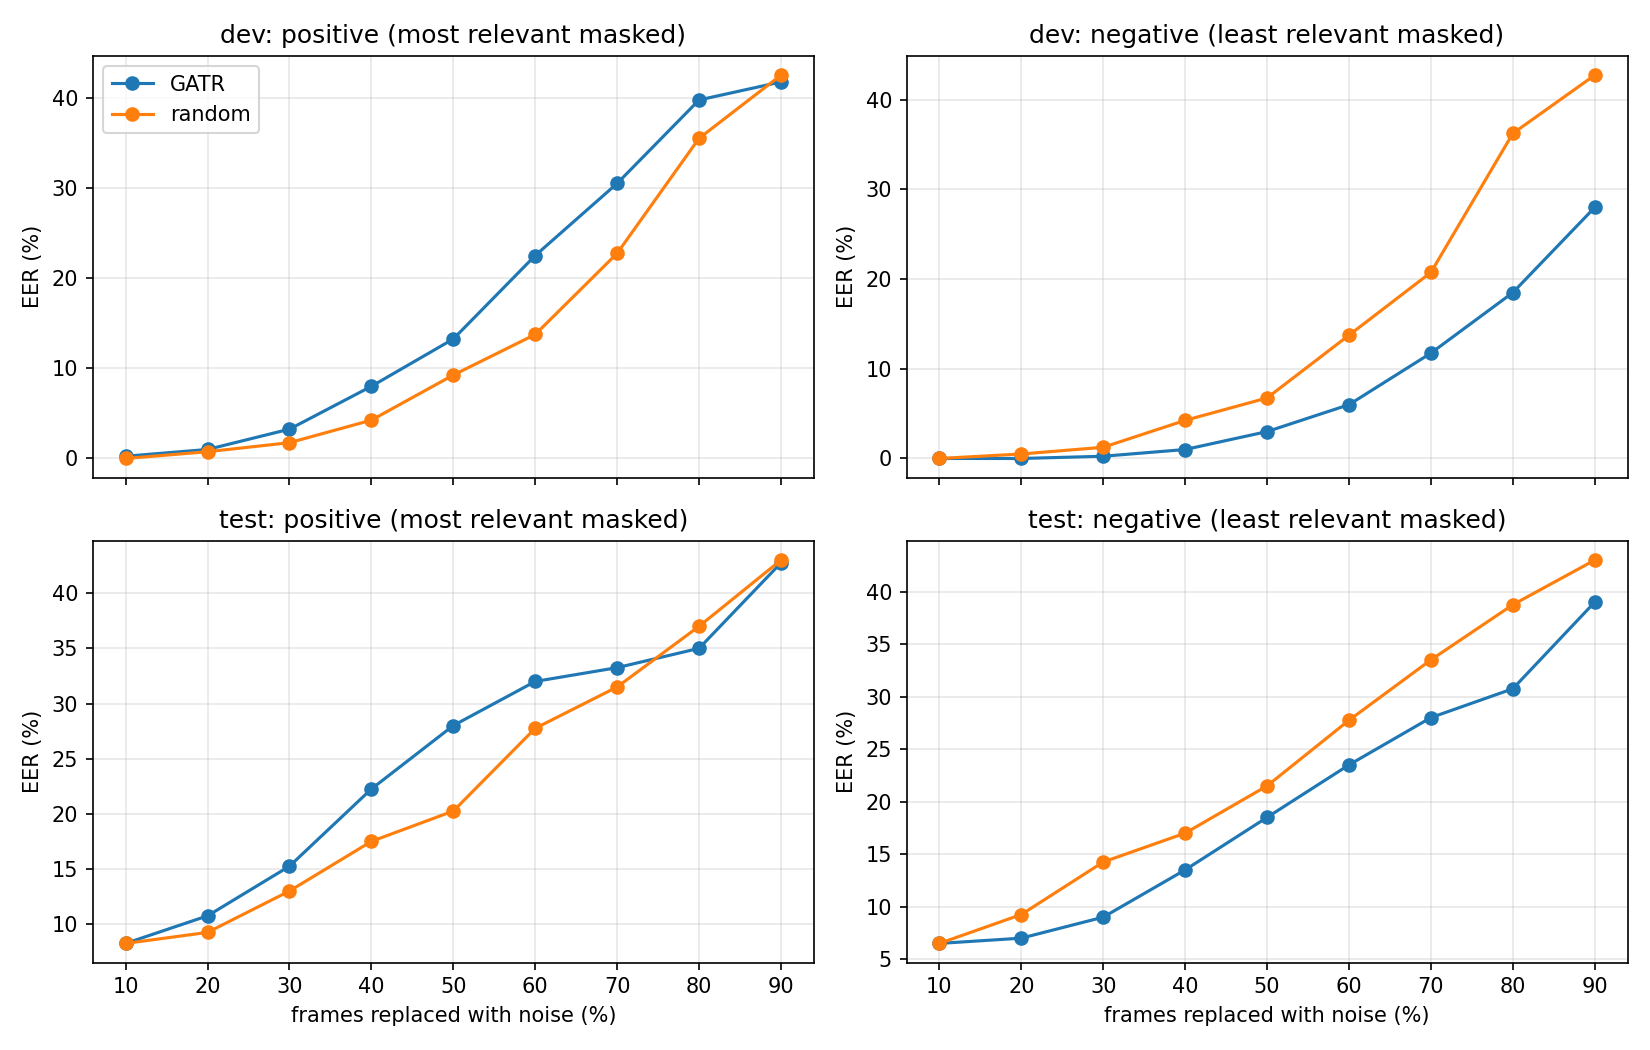

example_bona_fide_correct.png


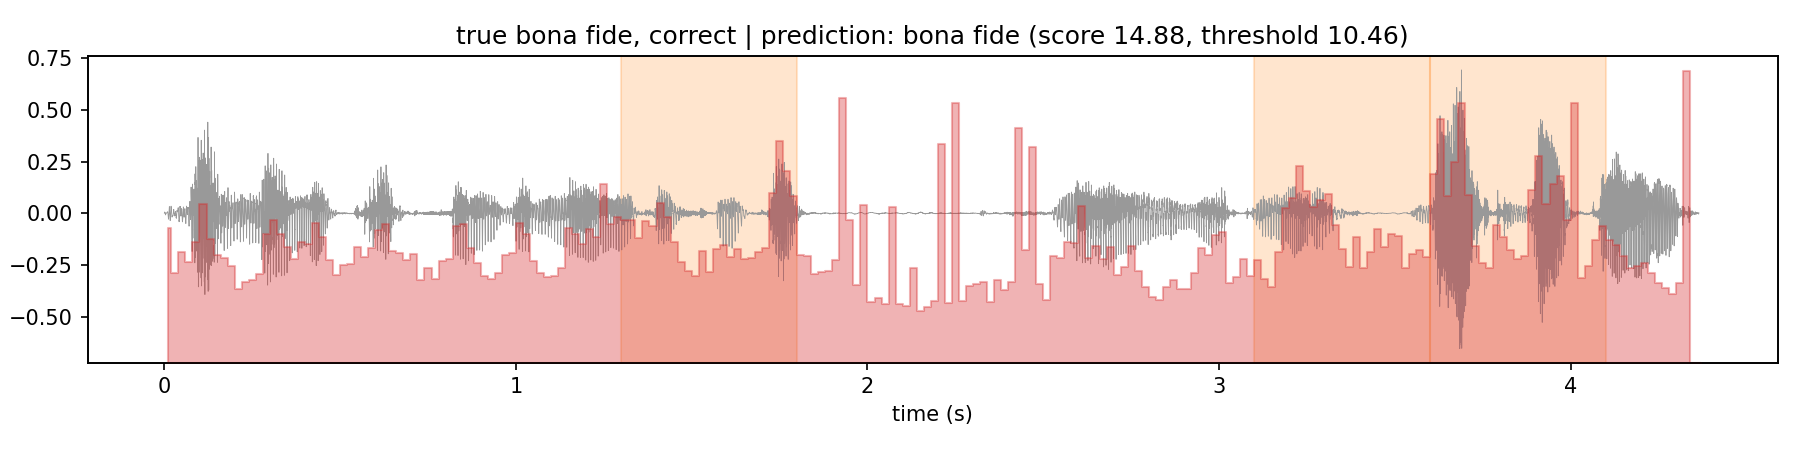

example_bona_fide_wrong.png


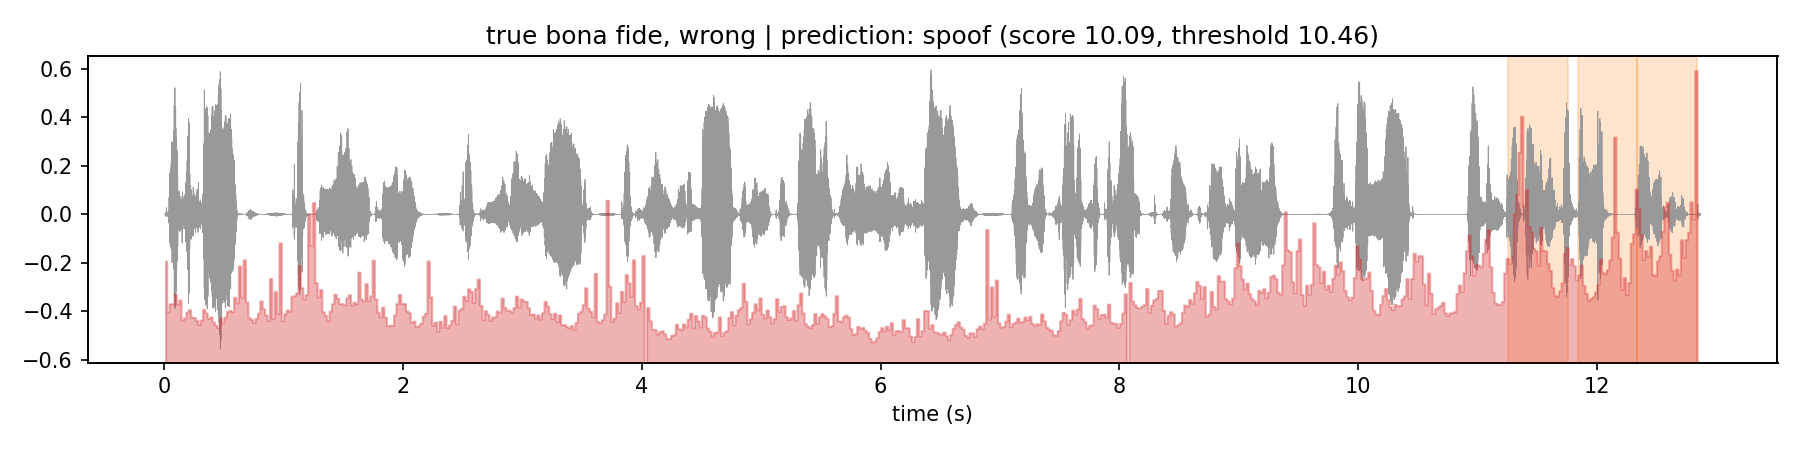

example_spoof_correct.png


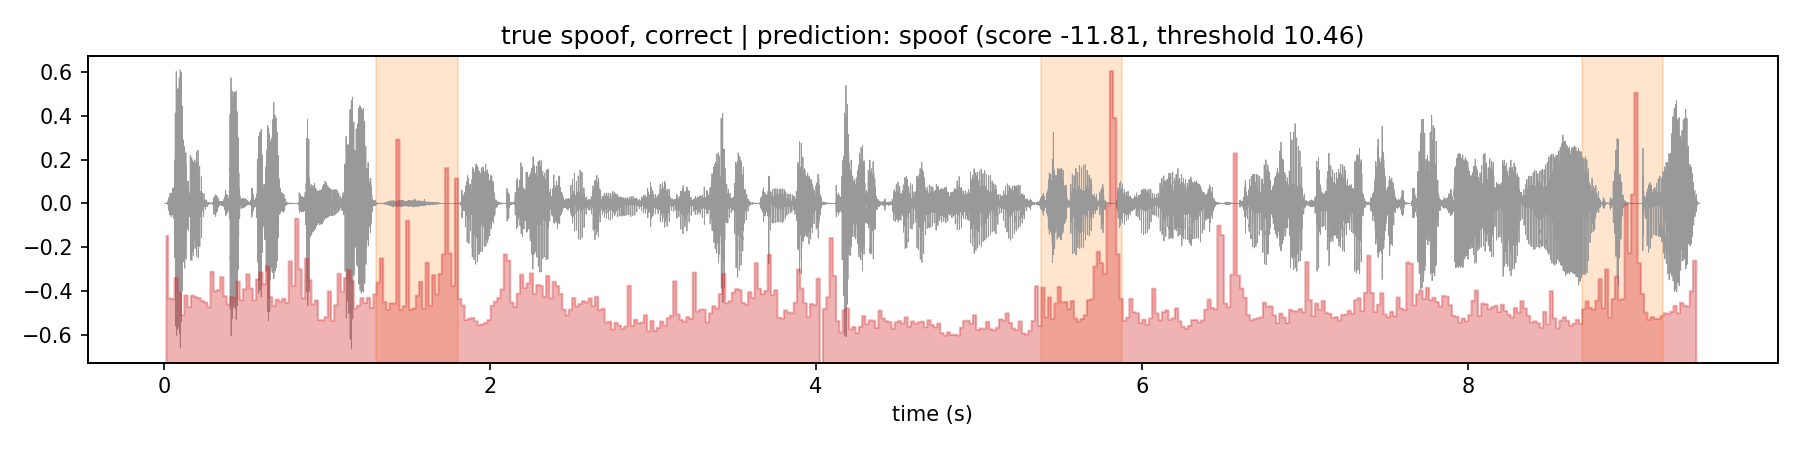

example_spoof_wrong.png


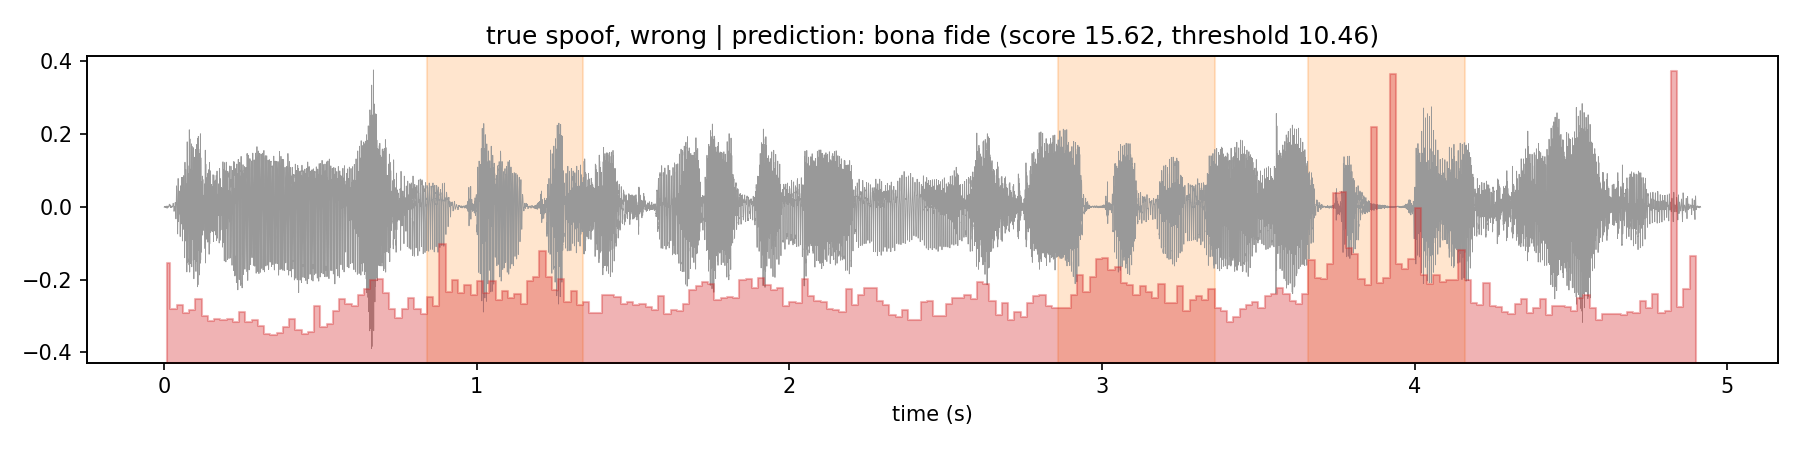

In [83]:
# F. Saved results
XG = os.path.join(RUNS, MAIN, "xai_gatr")
faith = read_csv("faithfulness.csv", XG, index_col=0)
if faith is not None:
    print("Perturbation test: AUC of the EER curve, GATR order vs random order; advantage > 0 = GATR better (95% CI)")
    keys = ["auc_gatr_pos", "auc_random_pos", "gatr_advantage_pos", "ci_low_pos", "ci_high_pos",
            "auc_gatr_neg", "auc_random_neg", "gatr_advantage_neg", "ci_low_neg", "ci_high_neg", "gatr_better_than_random",
            "peak_on_edges_pct", "chance_pct"]
    display(faith.loc[[k for k in keys if k in faith.index]])
mm = read_csv("map_metrics.csv", XG)
if mm is not None:
    print("\nMap metrics (AD lower is better; AI, AG, Fid-In higher are better); CI = GATR minus random maps")
    display(mm.round(2))
san = read_csv("sanity_check.csv", XG)
if san is not None:
    v = san.groupby("level", sort=False)["rho"].median()
    print("\nSanity check (cascading randomization): median Spearman with the trained-model map")
    display(v.round(3).to_frame("median_rho"))
    print(f"rule: {v['head+prompts']:.3f} after randomizing all trained parameters -> "
          f"{'FAILS' if v['head+prompts'] >= 0.5 else 'passes'} (fails if >= 0.5)")
rq = read_csv("rcq_speech.csv", XG)
if rq is not None:
    print("\nRCQ (> 0: the category gets more GATR relevance than average)")
    display(rq.pivot_table(index=["split", "cls"], columns="category", values="RCQ").round(1))
for f in ["perturbation_curves.png", "example_bona_fide_correct.png", "example_bona_fide_wrong.png",
          "example_spoof_correct.png", "example_spoof_wrong.png"]:
    show_png(f, XG)

---
# G. Golden data
200 bona fide dev recordings with a 0.6-1.6 s segment replaced by spoof speech of the same dialect and gender. The control uses a bona fide segment instead. Localization is measured with RMA and RRA.

In [84]:
%%step RUN_XAI
# G1. Settings and protocol
QUICK = False
N_ITEMS = 10 if QUICK else 200
SEG_MIN, SEG_MAX, MARGIN, FADE = 0.6, 1.6, 0.4, 160
RUN = "xlsr300m__wpt__ftrecipe__lr0.0001__seed42"
HF_NAME = "facebook/wav2vec2-xls-r-300m"
REPO_ID, REVISION = "ArabicSpeech/ArA-DF-2026", "2b1f042dc166b1d372841cb0d7110661ea5b2a93"
DEVTEST, TEST = "track-1_development_test", "track-1_test"

if IN_COLAB:
    PROJECT_ROOT = "/content/drive/MyDrive/nabra"
    AUDIO_ROOT = os.path.join(PROJECT_ROOT, "xai_audio")
    RUN_DIR = os.path.join(PROJECT_ROOT, "runs", RUN)
else:
    PROJECT_ROOT = r"C:\Users\Aisha\OneDrive\سطح المكتب\vss\Grad"
    AUDIO_ROOT = r"C:\Users\Aisha\nabra_data\aradf_audio"
    RUN_DIR = os.path.join(r"C:\Users\Aisha\nabra_runs", RUN)
ART_DIR = os.path.join(PROJECT_ROOT, "artifacts", "aradf_eda")
XDIR = os.path.join(RUN_DIR, "xai_golden_quick" if QUICK else "xai_golden"); os.makedirs(XDIR, exist_ok=True)

CFG = dict(seed=42, sample_rate=16000, max_len=64600, trim_silence=True, rms_dbfs=-23.0, spec_augment=False,
           n_prompts=6, n_wavelet_prompts=4, prompt_dropout=0.1, gradient_checkpointing=False,
           lora=dict(r=8, alpha=32, dropout=0.1, targets=["q_proj", "k_proj", "v_proj", "out_proj"]),
           aasist=dict(filts=[70, [1, 32], [32, 32], [32, 64], [64, 64]], gat_dims=[64, 32],
                       pool_ratios=[0.5, 0.7, 0.5, 0.5], temperatures=[2.0, 2.0, 100.0, 100.0]))
run_cfg = json.load(open(os.path.join(RUN_DIR, "config.json")))
for k in ["seed", "sample_rate", "max_len", "trim_silence", "rms_dbfs", "n_prompts", "n_wavelet_prompts", "prompt_dropout", "aasist"]:
    assert run_cfg[k] == CFG[k], f"{k}: notebook {CFG[k]} vs run {run_cfg[k]}"
METRICS = json.load(open(os.path.join(RUN_DIR, "metrics.json")))
THR = METRICS["threshold_from_devtest"]

import random
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.benchmark = False

PROTOCOL = dict(
    purpose="check whether GATR points at known spoofed regions, as the GATR paper does with PartialSpoof",
    data=(f"ArA-DF development split (not used for training). {N_ITEMS} bona fide hosts (duration >= 5 s, dialect and gender known), "
          "drawn with seed 42. For each host: one spoof donor and one bona fide donor of the same dialect and gender"),
    construction=(f"all clips preprocessed as in training (silence trim, RMS -23 dBFS); centre window of 64,600 samples of the host; "
                  f"one segment of uniform length {SEG_MIN}-{SEG_MAX} s at a uniform position at least {MARGIN} s from the window edges "
                  f"is replaced by the middle of the donor; linear cross-fade of {FADE} samples at both joins; same length, position "
                  "and cross-fade in the spliced and the control version"),
    ground_truth="frames whose centre sample lies inside the replaced segment (20 ms frames)",
    target="spoof class for all conditions; GATR as in part F",
    metrics=("RMA = positive relevance inside / total positive relevance; RRA = share of the K most relevant frames inside, "
             "K = ground-truth frames; chance = K / 201 frames; Arras et al. 2022"),
    tests=("paired bootstrap over hosts, 2000 resamples, 95% CI, for (spliced - chance) and (spliced - control), "
           "for RMA and RRA; also on the hosts whose spliced version the model scores as spoof"),
    decision_rule=("GATR localizes the spoofed segment only if the CI of (spliced - chance) and of (spliced - control) both "
                   "exclude 0 for RMA; otherwise this is reported as not shown"),
    scores="model score (logit bona fide - logit spoof) for host, control and spliced windows; threshold from T1 dev-test shown for reference",
    limits=("artificial splices of ArA-DF clips, not natural partial spoofs; one model; dev conditions only (wideband, three dialects)"),
    written="before running this notebook",
)
json.dump(PROTOCOL, open(os.path.join(XDIR, "protocol.json"), "w"), indent=2)
print(f"run: {RUN_DIR}\nresults: {XDIR}\nhosts: {N_ITEMS} | threshold (T1 dev-test): {THR:.3f}")

skipped (RUN_XAI = False)


In [85]:
%%step RUN_XAI
# G2. Data
import tarfile
def load_manifest(split):
    m = pd.read_csv(os.path.join(ART_DIR, "manifests", f"{split}.csv"), low_memory=False)
    return m[m["keep"].astype(bool)].reset_index(drop=True)
MAN = {s: load_manifest(s) for s in ["dev", DEVTEST]}
dev = MAN["dev"]
known = dev[dev.dialect.isin(["EGY", "Gulf", "MSA"]) & dev.gender.isin(["Male", "Female"])]
rs = np.random.RandomState(CFG["seed"])
hosts = known[(known.label == 1) & (known.duration_sec >= 5)].sample(frac=1, random_state=CFG["seed"]).head(2 * N_ITEMS)
rows, used = [], set()
for _, h in hosts.iterrows():
    same = known[(known.dialect == h.dialect) & (known.gender == h.gender) & (known.duration_sec >= 3) & ~known.id.isin(used | {h.id})]
    sp, bf = same[same.label == 0], same[same.label == 1]
    if not len(sp) or not len(bf): continue
    s_id, b_id = sp.id.iloc[rs.randint(len(sp))], bf.id.iloc[rs.randint(len(bf))]
    used |= {h.id, s_id, b_id}
    rows.append(dict(host=h.id, spoof_donor=s_id, bona_donor=b_id, dialect=h.dialect, gender=h.gender))
ITEMS = pd.DataFrame(rows)
print(f"{len(ITEMS)} candidate hosts | by dialect: {ITEMS.head(N_ITEMS).dialect.value_counts().to_dict()} | "
      f"by gender: {ITEMS.head(N_ITEMS).gender.value_counts().to_dict()}")
PATH = dev.set_index("id")["path"]

def extract_split(split, ids):
    os.makedirs(os.path.join(AUDIO_ROOT, split), exist_ok=True)
    want = {i for i in ids if not os.path.exists(os.path.join(AUDIO_ROOT, split, f"{i}.flac"))}
    if not want:
        print(f"{split}: all {len(ids):,} clips already on disk"); return
    from huggingface_hub import HfApi, hf_hub_download
    tok = os.environ.get("HF_TOKEN")
    files = HfApi().list_repo_files(REPO_ID, repo_type="dataset", revision=REVISION, token=tok)
    for t in sorted(f for f in files if f.startswith(f"data/{split}/") and f.endswith(".tar")):
        with tarfile.open(hf_hub_download(REPO_ID, t, repo_type="dataset", revision=REVISION, token=tok)) as tf:
            for mem in tf:
                cid = os.path.basename(mem.name)[:-5]
                if mem.isfile() and mem.name.endswith(".flac") and cid in want:
                    with open(os.path.join(AUDIO_ROOT, split, f"{cid}.flac"), "wb") as f: f.write(tf.extractfile(mem).read())
                    want.discard(cid)
        if not want: break
    assert not want, f"{split}: {len(want)} clips missing"
    print(f"{split}: {len(ids):,} clips ready")

check_man = MAN[DEVTEST].sample(32, random_state=CFG["seed"]).reset_index(drop=True)
extract_split("dev", sorted(set(ITEMS.host) | set(ITEMS.spoof_donor) | set(ITEMS.bona_donor)))
extract_split(DEVTEST, check_man.id.tolist())

skipped (RUN_XAI = False)


In [86]:
%%step RUN_XAI
# G3. Build the golden set
def clip_of(cid):
    return clean_wave(load_wave(os.path.join(AUDIO_ROOT, PATH[cid])))

def splice(host, donor, a, L):
    seg = crop_or_pad(donor, L + 2 * FADE, "center")
    out = host.copy(); ramp = np.linspace(0, 1, FADE, dtype=np.float32)
    out[a - FADE:a] = host[a - FADE:a] * (1 - ramp) + seg[:FADE] * ramp
    out[a:a + L] = seg[FADE:FADE + L]
    out[a + L:a + L + FADE] = seg[FADE + L:] * (1 - ramp) + host[a + L:a + L + FADE] * ramp
    return out

FR = np.arange(201) * HOP + 200
rs = np.random.RandomState(CFG["seed"] + 3)
G, kept = {"host": [], "control": [], "spliced": []}, []
for _, it in ITEMS.iterrows():
    x = clip_of(it.host)
    if len(x) < N: continue
    host = crop_or_pad(x, N, "center")
    L = int(rs.uniform(SEG_MIN, SEG_MAX) * SR)
    a = int(rs.uniform(MARGIN * SR, N - MARGIN * SR - L))
    G["host"].append(host)
    G["control"].append(splice(host, clip_of(it.bona_donor), a, L))
    G["spliced"].append(splice(host, clip_of(it.spoof_donor), a, L))
    kept.append(dict(it, start_s=a / SR, length_s=L / SR, gt_mask=((FR >= a) & (FR < a + L))))
    if len(kept) == N_ITEMS: break
GS = pd.DataFrame(kept); G = {k: np.stack(v).astype(np.float32) for k, v in G.items()}
GT = np.stack(GS["gt_mask"].values); GS["chance"] = GT.mean(1)
assert len(GS) == N_ITEMS, f"only {len(GS)} usable hosts"
GS.drop(columns="gt_mask").to_csv(os.path.join(XDIR, "golden_items.csv"), index=False)
print(f"{len(GS)} hosts | segment {GS.length_s.mean():.2f} s on average ({GS.length_s.min():.2f}-{GS.length_s.max():.2f}) | "
      f"chance level (segment / window) {100 * GS.chance.mean():.1f}%")

skipped (RUN_XAI = False)


In [87]:
%%step RUN_XAI
# G4. Scores and maps
@torch.no_grad()
def scores_of(X, chunk=16):
    return torch.cat([score_of(model(b.cuda())).cpu() for b in torch.from_numpy(X).split(chunk)]).numpy()

SC = {k: scores_of(v) for k, v in G.items()}
for k in G: GS[f"score_{k}"] = SC[k]
out = os.path.join(XDIR, "maps.npz")
if os.path.exists(out):
    z = np.load(out); MAPS = {k: z[k] for k in G}; print("maps loaded from", out)
else:
    t0 = time.time(); MAPS = {k: np.stack([gatr_window(x, 0)[0] for x in v]).astype(np.float32) for k, v in G.items()}
    np.savez_compressed(out, **MAPS, gt=GT); print(f"maps: {time.time() - t0:.0f} s | saved {out}")

from sklearn.metrics import roc_auc_score
y = np.r_[np.zeros(len(GS)), np.ones(len(GS))]
print("model score (logit bona fide - logit spoof), median [IQR]:")
for k in G:
    q = np.percentile(SC[k], [25, 50, 75])
    print(f"  {k:8s} {q[1]:7.2f} [{q[0]:.2f}, {q[2]:.2f}] | below the T1 dev-test threshold ({THR:.2f}): {100 * (SC[k] < THR).mean():.0f}%")
print(f"spliced scored lower than its control: {100 * (SC['spliced'] < SC['control']).mean():.0f}% of hosts | "
      f"AUC spliced vs control {100 * roc_auc_score(y, np.r_[SC['spliced'], SC['control']]):.1f}%")

skipped (RUN_XAI = False)


In [88]:
%%step RUN_XAI
# G5. Localization
def rma(h, gt):
    h = np.clip(h, 0, None); return h[gt].sum() / h.sum() if h.sum() > 0 else np.nan
def rra(h, gt):
    k = int(gt.sum()); return gt[np.argsort(-h, kind="stable")[:k]].mean()

for k in G:
    GS[f"RMA_{k}"] = [rma(h, g) for h, g in zip(MAPS[k], GT)]
    GS[f"RRA_{k}"] = [rra(h, g) for h, g in zip(MAPS[k], GT)]
GS.drop(columns="gt_mask").to_csv(os.path.join(XDIR, "golden_items.csv"), index=False)

def summary(D, label, nboot=2000):
    rs = np.random.RandomState(CFG["seed"] + 11); rows = []
    for m in ["RMA", "RRA"]:
        s, c, ch = D[f"{m}_spliced"].values, D[f"{m}_control"].values, D.chance.values
        ok = ~np.isnan(s) & ~np.isnan(c); s, c, ch = s[ok], c[ok], ch[ok]
        B = np.array([[(s[i] - ch[i]).mean(), (s[i] - c[i]).mean()] for i in (rs.randint(0, len(s), len(s)) for _ in range(nboot))])
        lo, hi = np.percentile(B, [2.5, 97.5], axis=0)
        rows.append(dict(subset=label, n=len(s), metric=m, spliced=100 * s.mean(), control=100 * c.mean(),
                         host=100 * np.nanmean(D[f"{m}_host"]), chance=100 * ch.mean(),
                         spliced_minus_chance=100 * (s - ch).mean(), ci_chance=f"[{100 * lo[0]:.1f}, {100 * hi[0]:.1f}]",
                         spliced_minus_control=100 * (s - c).mean(), ci_control=f"[{100 * lo[1]:.1f}, {100 * hi[1]:.1f}]",
                         better_than_chance=bool(lo[0] > 0), better_than_control=bool(lo[1] > 0)))
    return rows

det = GS.score_spliced < GS.score_host
LOC = pd.DataFrame(summary(GS, "all hosts") + summary(GS[det], "spliced scored lower than host"))
LOC.to_csv(os.path.join(XDIR, "localization.csv"), index=False)
print("RMA / RRA in % (higher = more relevance inside the replaced segment); host = the same frames without any splice")
print(LOC.round(1).to_string(index=False))
r = LOC[(LOC.subset == "all hosts") & (LOC.metric == "RMA")].iloc[0]
print("\nDecision rule:", "GATR localizes the spoofed segment (RMA above chance and above the bona fide control)"
      if r.better_than_chance and r.better_than_control else "not shown (RMA not above both chance and the control)")
by = GS.groupby("dialect")[["RMA_spliced", "RMA_control"]].mean().astype(float).mul(100).round(1)
by["hosts"] = GS.dialect.value_counts(); print("\nRMA by dialect (%):"); print(by.to_string())

skipped (RUN_XAI = False)


In [89]:
%%step RUN_XAI
# G6. Figures
import matplotlib.pyplot as plt
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .3})
grid = np.linspace(-1, 2, 61); prof = {k: [] for k in G}
for i, row in GS.iterrows():
    g = np.where(GT[i])[0]; s0, s1 = g[0], g[-1] + 1; pos = (np.arange(201) - s0) / (s1 - s0)
    for k in G:
        h = np.clip(MAPS[k][i], 0, None); h = h / h.max() if h.max() > 0 else h
        prof[k].append(np.interp(grid, pos, h, left=np.nan, right=np.nan))
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for k, c in [("spliced", "#eb6834"), ("control", "#2a78d6"), ("host", "0.5")]:
    ax.plot(grid, np.nanmean(prof[k], 0), color=c, lw=2, label={"spliced": "spoof segment inside", "control": "bona fide segment inside (control)", "host": "no splice"}[k])
ax.axvspan(0, 1, color="0.85", zorder=0, label="replaced segment")
ax.set(xlabel="position relative to the replaced segment (0 = start, 1 = end)", ylabel="mean GATR relevance (peak = 1)",
       title="XLS-R 300M + WPT: GATR relevance around the replaced segment (dev)")
ax.legend(frameon=False, fontsize=8); fig.tight_layout(); fig.savefig(os.path.join(XDIR, "relevance_profile.png"), dpi=200, bbox_inches="tight"); plt.show()

fig, axs = plt.subplots(2, 2, figsize=(12, 5), sharex=True)
for r_, i in enumerate(GS.RMA_spliced.sort_values().index[[len(GS) // 2, -1]]):
    for c_, k in enumerate(["spliced", "control"]):
        a = axs[r_, c_]; x = G[k][i]; h = np.clip(MAPS[k][i], 0, None)
        a.plot(np.arange(N) / SR, x, lw=.4, color="0.6"); a2 = a.twinx()
        a2.fill_between((np.arange(201) + .5) * HOP / SR, h / max(h.max(), 1e-12), color="tab:red", alpha=.35, step="mid"); a2.set_yticks([])
        a.axvspan(GS.start_s[i], GS.start_s[i] + GS.length_s[i], color="tab:orange", alpha=.2)
        a.set_title(f"{k} | RMA {100 * GS[f'RMA_{k}'][i]:.0f}% (chance {100 * GS.chance[i]:.0f}%) | score {GS[f'score_{k}'][i]:.2f}", fontsize=9)
for a in axs[1]: a.set_xlabel("time (s)")
fig.tight_layout(); fig.savefig(os.path.join(XDIR, "examples.png"), dpi=150); plt.show()
print("files in", XDIR, ":", sorted(os.listdir(XDIR)))

skipped (RUN_XAI = False)


200 hosts | by dialect {'Gulf': 140, 'EGY': 46, 'MSA': 14} | by gender {'Male': 178, 'Female': 22}
segment 1.12 s on average | chance level 27.9%
model score (logit bona fide - logit spoof), median [IQR]:
  host       12.88 [10.53, 14.63] | below the threshold (10.46): 24%
  control     7.86 [4.48, 10.18] | below the threshold (10.46): 78%
  spliced     1.56 [-3.61, 5.47] | below the threshold (10.46): 97%
AUC spliced vs control 80.2%

RMA / RRA in % (higher = more relevance inside the replaced segment)


,subset,n,metric,spliced,control,host,chance,spliced_minus_chance,ci_chance,spliced_minus_control,ci_control,better_than_chance,better_than_control
0,all hosts,200,RMA,40.0,28.2,28.2,27.9,12.1,"[10.9, 13.3]",11.8,"[10.5, 13.2]",True,True
1,all hosts,200,RRA,57.7,28.5,28.3,27.9,29.8,"[27.1, 32.6]",29.2,"[25.7, 32.7]",True,True
2,spliced scored lower than host,199,RMA,40.0,28.2,28.1,27.9,12.1,"[10.9, 13.4]",11.8,"[10.4, 13.3]",True,True
3,spliced scored lower than host,199,RRA,57.6,28.6,28.2,27.9,29.8,"[27.0, 32.5]",29.1,"[25.5, 32.6]",True,True


Decision rule: GATR localizes the spoofed segment (RMA above chance and above the control)

RMA by dialect (%)


,RMA_spliced,RMA_control
dialect,,
EGY,40.9,25.9
Gulf,39.9,28.8
MSA,38.0,29.5


relevance_profile.png


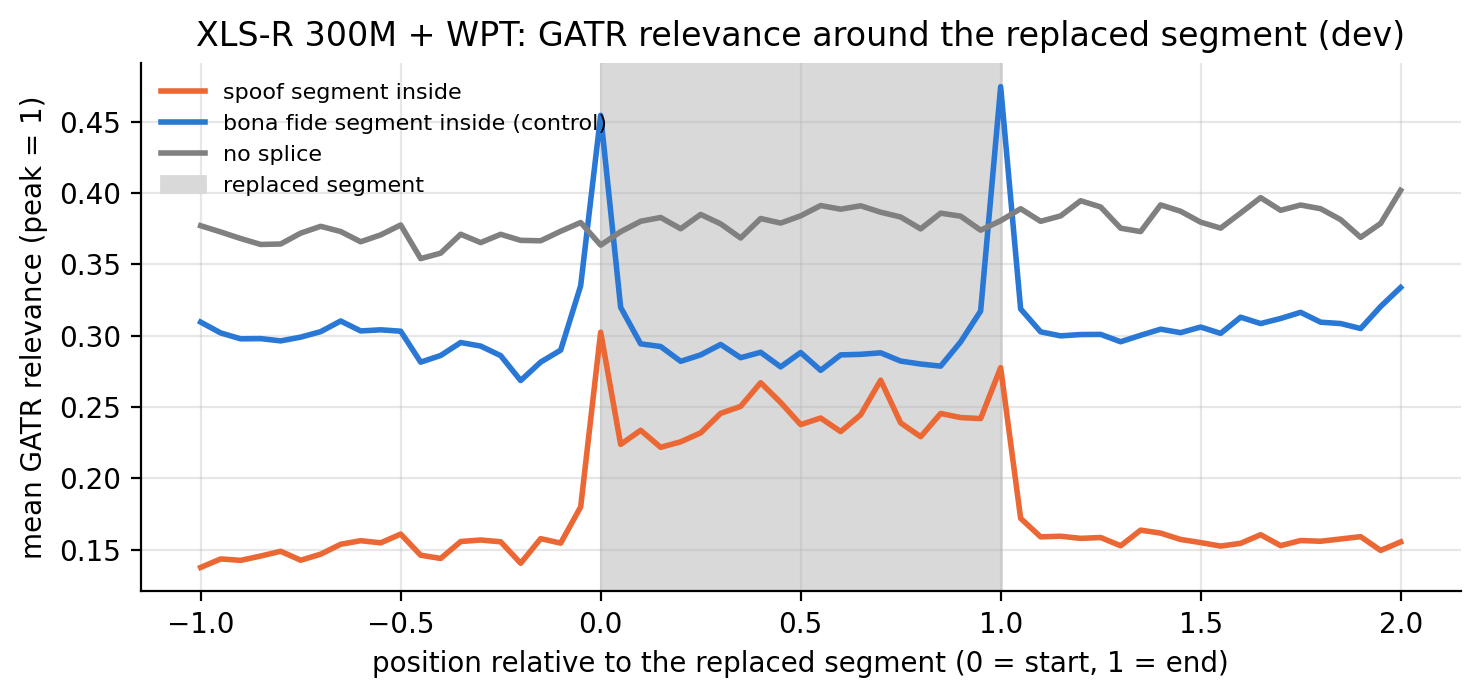

examples.png


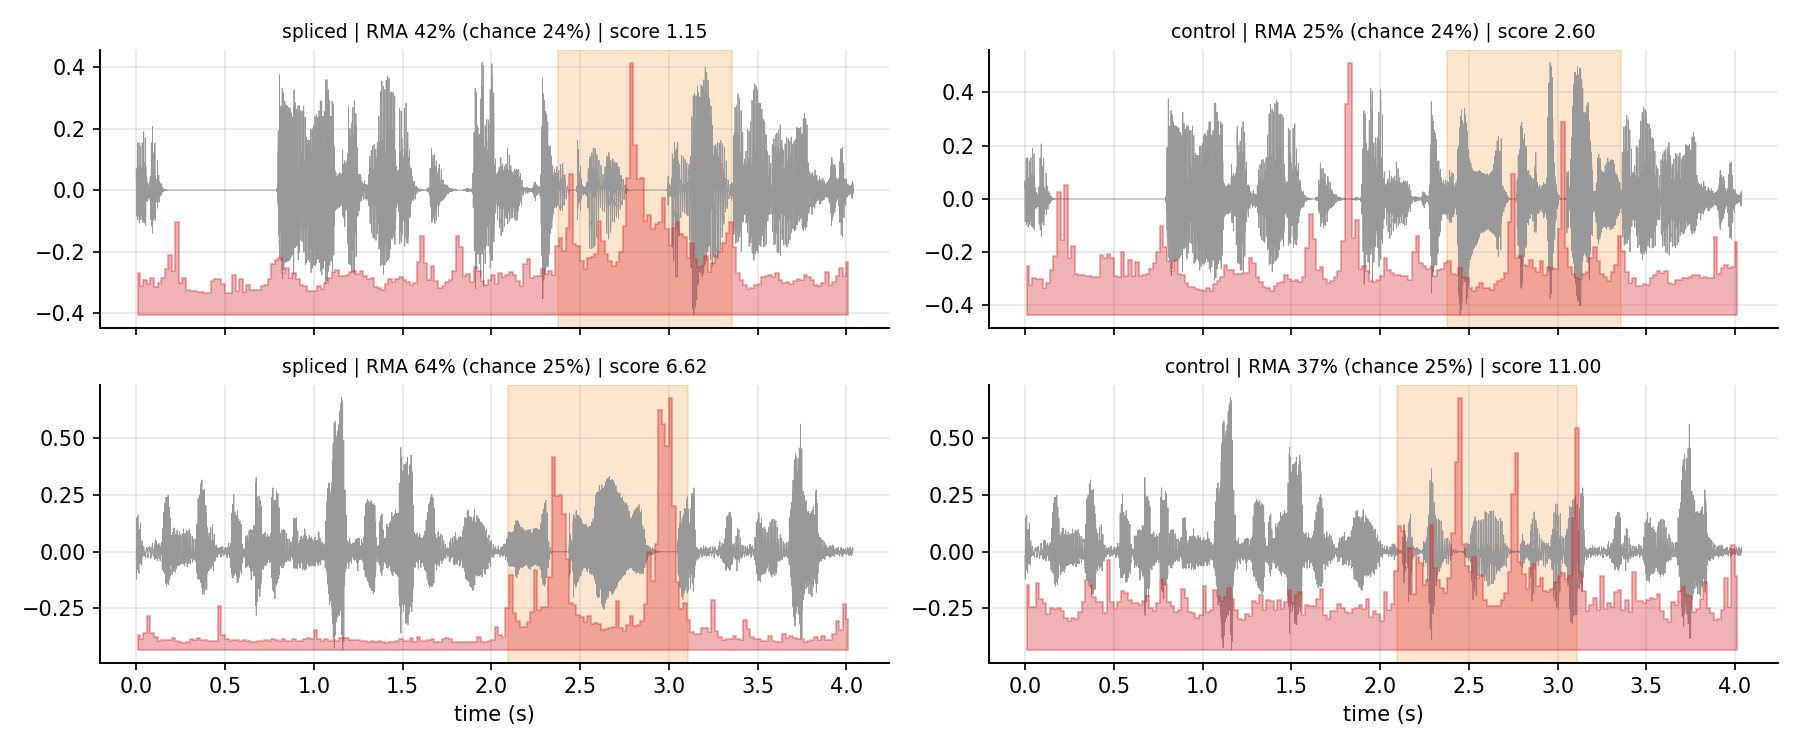

In [90]:
# G. Saved results
XO = os.path.join(RUNS, MAIN, "xai_golden")
thr = metrics_of(MAIN)["threshold_from_devtest"] if metrics_of(MAIN) else 10.4609375
gi = read_csv("golden_items.csv", XO)
if gi is not None:
    print(f"{len(gi)} hosts | by dialect {gi.dialect.value_counts().to_dict()} | by gender {gi.gender.value_counts().to_dict()}")
    print(f"segment {gi.length_s.mean():.2f} s on average | chance level {100 * gi.chance.mean():.1f}%")
    print("model score (logit bona fide - logit spoof), median [IQR]:")
    for k in ["host", "control", "spliced"]:
        q = np.percentile(gi[f"score_{k}"], [25, 50, 75])
        print(f"  {k:8s} {q[1]:7.2f} [{q[0]:.2f}, {q[2]:.2f}] | below the threshold ({thr:.2f}): {100 * (gi[f'score_{k}'] < thr).mean():.0f}%")
    yy = np.r_[np.zeros(len(gi)), np.ones(len(gi))]
    print(f"AUC spliced vs control {100 * roc_auc_score(yy, np.r_[gi.score_spliced, gi.score_control]):.1f}%")
loc = read_csv("localization.csv", XO)
if loc is not None:
    print("\nRMA / RRA in % (higher = more relevance inside the replaced segment)")
    display(loc.round(1))
    r = loc[(loc.subset == "all hosts") & (loc.metric == "RMA")].iloc[0]
    print("Decision rule:", "GATR localizes the spoofed segment (RMA above chance and above the control)"
          if r.better_than_chance and r.better_than_control else "not shown")
if gi is not None:
    print("\nRMA by dialect (%)"); display((gi.groupby("dialect")[["RMA_spliced", "RMA_control"]].mean() * 100).round(1))
for f in ["relevance_profile.png", "examples.png"]:
    show_png(f, XO)

---
# Summary
| | Result |
|---|---|
| Main model | XLS-R 300M + WPT + AASIST, 0.55% of parameters trained, epoch 18 |
| T1 dev-test EER | 6.06% [5.64, 6.46] |
| Final-test EER | **5.93%**, AUC 98.59 |
| At threshold 10.46 | accuracy 94.15%, FRR 6.08%, FAR 5.77% |
| Hardest clips | up to 4 s: EER 11.67% |
| GATR | better than random on both perturbation tests; sanity check 0.508 (pass mark below 0.5) |
| Golden data | RMA 40.0% spliced vs 28.2% control (chance 27.9%) |